## 1. Thành viên và phân công

| Họ tên | MSSV | Phụ trách chính |
|---|---|---|
| Nguyễn Gia Hưng | 11253367 | Khảo sát dữ liệu (A1–A6); Làm sạch dữ liệu từ B1 đến B5 (`booking_id`, sửa lệch cột trạng thái/ngày, chuẩn hóa giá trị thiếu, nhãn phân loại, kiểu ngày tháng); Kiểm tra tự động toàn bộ notebook. |
| Dương Minh Nguyên | 11256308 | Làm sạch dữ liệu từ B6 đến B8 (ép kiểu số & `adr`, chuẩn hóa `country`, hợp nhất 10.000 `booking_id` và xuất `row_lineage`); Giai đoạn C (C1–C3); Phân tích & vẽ biểu đồ Câu 1 đến Câu 5. |
| Lê Hải Yến | 11259127 | Phân tích & vẽ biểu đồ Câu 6 đến Câu 10 (phân khúc, đặt cọc, giá phòng `adr`, thời gian lưu trú, đổi phòng); Viết 6 Insight có bằng chứng, phần giới hạn & hướng bổ sung dữ liệu; Hoàn thiện báo cáo và `README.md`. |

## Cách dùng notebook này

Notebook đi theo đúng 5 giai đoạn của đề bài: **A Khảo sát → B Làm sạch → C Bảng sạch & kiểm tra → D Phân tích 10 câu → E Xuất & nộp**.

| Ký hiệu | Ý nghĩa | Bạn cần làm gì |
|---|---|---|
| 📋 Thẻ nhiệm vụ | Bảng đầu mỗi mục: mục tiêu, đầu vào/ra, các bước, bẫy | Đọc trước khi viết mã |
| `# TODO` | Chỗ nhóm phải viết mã | Thay bằng mã của nhóm; xóa chữ TODO khi xong |
| `= None` | Biến đầu ra nhóm phải tạo | Gán DataFrame thật, **giữ đúng tên biến** |
| ✅ / ❌ | Kết quả ô tự kiểm tra | ❌ nghĩa là chưa xong hoặc chưa đúng quy ước — đọc gợi ý in kèm |
| ✍️ | Ô văn bản nhóm phải viết | Viết bằng số liệu thật, có mẫu số |

**Ba quy tắc vàng**

1. **Không sửa tay** `hotel_bookings_dirty.csv`, không thay bằng bộ dữ liệu gốc sạch.
2. **Không xóa các ô kiểm tra** (✅/❌). Chúng giúp bạn và giảng viên thấy tiến độ.
3. Cuối mỗi buổi: **Runtime/Kernel → Restart & Run all**. Notebook phải chạy được từ đầu đến cuối.

Notebook vẫn chạy hết khi còn dang dở: các ô kiểm tra chỉ in ❌, không làm dừng chương trình.

## 0 · Thiết lập

**Colab:** File → Upload notebook; mở bảng 📁 Files, tải `hotel_bookings_dirty.csv` lên. Có thể tải thêm `kiem_tra_nop_bai.py` để tự kiểm tra ở cuối.
**Máy cá nhân:** giữ cấu trúc thư mục của gói bài tập (notebook ở thư mục gốc, dữ liệu trong `data/`).

Ô 0.1 chứa công cụ hỗ trợ dùng chung. **Không cần sửa**, chỉ cần chạy.

In [1]:
# 0.1 CÔNG CỤ HỖ TRỢ — KHÔNG CẦN SỬA
from pathlib import Path
import re
import pandas as pd
import matplotlib.pyplot as plt

pd.set_option('display.max_columns', 40)
pd.set_option('display.max_colwidth', 40)

# ---- Đường dẫn: tự tìm dữ liệu ở data/ hoặc cùng thư mục notebook (Colab) ----
CANDIDATES = [Path('data/hotel_bookings_dirty.csv'), Path('hotel_bookings_dirty.csv')]
DATA_PATH = next((p for p in CANDIDATES if p.exists()), CANDIDATES[0])
OUTPUT_DIR = Path('outputs')
for sub in ['', 'figures', 'tables']:
    (OUTPUT_DIR / sub).mkdir(parents=True, exist_ok=True)

# ---- Quy ước của đề (Mục 5) ----
SNAPSHOT_DATE = pd.Timestamp('2017-09-14')
MISSING_TOKENS = ['NULL', 'N/A', 'NA', '?', 'unknown', '-']        # so sánh không phân biệt hoa thường
HOTEL_COLORS = {'City Hotel': '#2F4858', 'Resort Hotel': '#E07A1F'}  # dùng cho MỌI hình có hotel
STATUS_COLORS = {'Check-Out': '#5B8E7D', 'Canceled': '#B81D24', 'No-Show': '#F2A541'}
FIGSIZE = (9, 5)

# ===================== BỘ KIỂM TRA ĐẦU RA (dùng chung notebook + tools) =====================
# Bộ kiểm tra chỉ xác nhận CẤU TRÚC, KHÓA, MIỀN GIÁ TRỊ và TÍNH NHẤT QUÁN theo quy ước trong đề.
# Nó KHÔNG chứa đáp án và KHÔNG chứng minh kết quả phân tích của nhóm là đúng.
import pandas as pd

HOTELS = ['City Hotel', 'Resort Hotel']
MEALS = ['BB', 'HB', 'FB', 'SC']
SEGMENTS = ['Online TA', 'Offline TA/TO', 'Groups', 'Direct', 'Corporate', 'Complementary', 'Aviation']
CHANNELS = ['TA/TO', 'Direct', 'Corporate', 'GDS']
DEPOSITS = ['No Deposit', 'Non Refund', 'Refundable']
CUSTOMERS = ['Transient', 'Transient-Party', 'Contract', 'Group']
STATUSES = ['Check-Out', 'Canceled', 'No-Show']
ROOM_TYPES = ['A', 'B', 'C', 'D', 'E', 'F', 'G', 'H', 'I', 'K', 'L', 'P']
LEAD_GROUPS = ['0-7', '8-30', '31-90', '91-180', '181+']

ARRIVAL_MIN, ARRIVAL_MAX = pd.Timestamp('2015-07-01'), pd.Timestamp('2017-08-31')
STATUS_MIN, STATUS_MAX = pd.Timestamp('2014-10-01'), pd.Timestamp('2017-09-14')
LEAD_MIN, LEAD_MAX = 0, 800
WEEKEND_MAX, WEEK_MAX = 20, 50
GUEST_MAX = 10
ADR_MIN, ADR_MAX = 0, 1000
REQ_MAX = 5
N_RAW_ROWS = 10325

CLEAN_REQUIRED = ['booking_id', 'hotel', 'is_canceled', 'lead_time', 'arrival_date', 'stays_in_weekend_nights',
                  'stays_in_week_nights', 'adults', 'children', 'babies', 'meal', 'country', 'market_segment',
                  'distribution_channel', 'is_repeated_guest', 'reserved_room_type', 'assigned_room_type',
                  'deposit_type', 'customer_type', 'adr', 'total_of_special_requests', 'reservation_status',
                  'reservation_status_date',
                  'arrival_year', 'arrival_month', 'total_nights', 'total_guests', 'lead_time_group',
                  'room_changed_flag', 'revenue_est']
SUMMARY_COLUMNS = ['hotel', 'arrival_year', 'arrival_month', 'n_bookings', 'n_canceled',
                   'cancel_rate_pct', 'room_nights']
LOG_COLUMNS = ['step', 'field', 'issue', 'detection_rule', 'action', 'affected_rows',
               'changed_cells', 'removed_rows', 'example_row_ids', 'reason', 'check_after']
LINEAGE_COLUMNS = ['row_id', 'booking_id', 'status']
LINEAGE_STATUS = ['kept', 'merged', 'dropped']
QUALITY_COLUMNS = ['column', 'stage', 'denominator_rows', 'missing_count', 'invalid_count', 'missing_pct']

CORE_FILES = ['bookings_clean.csv', 'monthly_summary.csv', 'cleaning_log.csv', 'row_lineage.csv',
              'quality_report.csv']
FIGURE_FILES = ['fig01_hotel_cancel.png', 'fig02_monthly_arrivals_2016.png', 'fig03_leadtime_cancel.png',
                'fig04_top10_country.png', 'fig05_segment_cancel.png', 'fig06_deposit_cancel.png',
                'fig07_adr_hist.png', 'fig08_stay_nights.png']
TABLE_FILES = ['a_missing_survey.csv', 'a_issue_catalog.csv', 'q01_before_after.csv',
               'q02_hotel_cancel.csv', 'q03_monthly_arrivals_2016.csv', 'q04_leadtime_stats.csv',
               'q04_leadtime_cancel.csv', 'q05_top10_country.csv', 'q06_segment_cancel.csv',
               'q07_deposit_cancel.csv', 'q08_adr_stats_by_hotel.csv', 'q09_stay_nights.csv',
               'q10_room_change_by_hotel.csv', 'q10_room_change_by_reserved_type.csv']


def _blank(s):
    """True khi ô thiếu: NaN/None/NA hoặc chuỗi rỗng sau khi bỏ khoảng trắng."""
    return s.isna() | s.astype('string').str.strip().fillna('').eq('')


def _num(s):
    return pd.to_numeric(s.where(~_blank(s)), errors='coerce')


def _int_ok(s, lo, hi):
    """Ô có dữ liệu phải là số nguyên trong [lo, hi]. Trả về (đạt?, số ô sai)."""
    present = ~_blank(s)
    v = _num(s)
    bad = present & (v.isna() | (v % 1 != 0) | (v < lo) | (v > hi))
    return int(bad.sum()) == 0, int(bad.sum())


def _bool(s):
    m = {'true': True, 'false': False, '1': True, '0': False, '1.0': True, '0.0': False}
    return s.astype('string').str.strip().str.lower().map(m)


def _date(s):
    txt = s.astype('string').str.strip()
    return pd.to_datetime(txt.where(~_blank(s)), format='%Y-%m-%d', errors='coerce')


def _cat_ok(s, allowed, allow_missing=True):
    present = ~_blank(s)
    bad = sorted(set(s[present].astype(str)) - set(allowed))
    miss = int((~present).sum())
    ok = not bad and (allow_missing or miss == 0)
    return ok, ('Nhãn lạ: ' + ', '.join(bad[:6]) if bad else '') + ('' if allow_missing or miss == 0 else f' {miss} ô thiếu')


def validate_outputs(clean, monthly, row_lineage, cleaning_log, quality_report, raw_row_ids=None):
    """Chạy toàn bộ kiểm tra. Trả về DataFrame: nhom, kiem_tra, ket_qua, chi_tiet."""
    res = []

    def add(group, name, ok, detail=''):
        res.append({'nhom': group, 'kiem_tra': name,
                    'ket_qua': 'ĐẠT' if ok else 'CHƯA ĐẠT', 'chi_tiet': detail})

    def safe(group, name, fn):
        try:
            ok, detail = fn()
        except Exception as e:  # thiếu cột, sai kiểu... -> báo lỗi thân thiện
            ok, detail = False, f'Lỗi khi kiểm tra: {type(e).__name__}: {e}'
        add(group, name, ok, detail)

    frames = {'bookings_clean': clean, 'monthly_summary': monthly, 'row_lineage': row_lineage,
              'cleaning_log': cleaning_log, 'quality_report': quality_report}
    for k, v in frames.items():
        add('0 Tồn tại', f'{k} đã được tạo', v is not None and len(v) > 0,
            '' if v is not None else 'Biến/tệp còn trống (None).')

    # ---------------- Bảng chính: khóa và nhãn ----------------
    if clean is not None:
        c = clean
        G = '1 Khóa & nhãn'
        safe(G, 'Đủ các cột bắt buộc',
             lambda: (not (miss := [x for x in CLEAN_REQUIRED if x not in c.columns]),
                      'Thiếu: ' + ', '.join(miss) if miss else f'{len(c.columns)} cột'))
        safe(G, 'booking_id không thiếu, dạng BK + 6 chữ số',
             lambda: ((n := int((_blank(c['booking_id']) | ~c['booking_id'].astype('string').str.fullmatch(r'BK\d{6}').fillna(False)).sum())) == 0,
                      f'{n} ô thiếu hoặc sai dạng'))
        safe(G, 'booking_id không trùng (1 dòng / đặt phòng)',
             lambda: ((n := int(c['booking_id'].duplicated().sum())) == 0, f'{n} booking_id lặp'))
        safe(G, 'hotel chỉ gồm City Hotel, Resort Hotel (không thiếu)', lambda: _cat_ok(c['hotel'], HOTELS, False))
        for col, allowed in [('meal', MEALS), ('market_segment', SEGMENTS), ('distribution_channel', CHANNELS),
                             ('deposit_type', DEPOSITS), ('customer_type', CUSTOMERS), ('reservation_status', STATUSES),
                             ('reserved_room_type', ROOM_TYPES), ('assigned_room_type', ROOM_TYPES)]:
            safe(G, f'{col} thuộc tập nhãn hợp lệ hoặc thiếu', lambda col=col, allowed=allowed: _cat_ok(c[col], allowed))
        safe(G, 'country là mã 2–3 chữ in hoa hoặc thiếu',
             lambda: ((n := int((~_blank(c['country']) & ~c['country'].astype('string').str.fullmatch(r'[A-Z]{2,3}').fillna(False)).sum())) == 0,
                      f'{n} ô sai dạng'))
        safe(G, 'is_canceled, is_repeated_guest chỉ là 0/1 hoặc thiếu',
             lambda: ((a := _int_ok(c['is_canceled'], 0, 1))[0] and (b := _int_ok(c['is_repeated_guest'], 0, 1))[0],
                      f'is_canceled sai: {a[1]}; is_repeated_guest sai: {b[1]}'))

        # ---------------- Số đo và ngày ----------------
        G = '2 Số & ngày'
        for col, lo, hi in [('lead_time', LEAD_MIN, LEAD_MAX), ('stays_in_weekend_nights', 0, WEEKEND_MAX),
                            ('stays_in_week_nights', 0, WEEK_MAX), ('adults', 0, GUEST_MAX), ('children', 0, GUEST_MAX),
                            ('babies', 0, GUEST_MAX), ('total_of_special_requests', 0, REQ_MAX)]:
            safe(G, f'{col} nguyên trong {lo}–{hi}', lambda col=col, lo=lo, hi=hi: ((r := _int_ok(c[col], lo, hi))[0], f'{r[1]} ô sai'))

        def _adr():
            present = ~_blank(c['adr'])
            v = _num(c['adr'])
            bad = present & (v.isna() | (v < ADR_MIN) | (v > ADR_MAX))
            return int(bad.sum()) == 0, f'{int(bad.sum())} ô không phải số trong 0–1000'
        safe(G, 'adr là số (EUR) trong 0–1000 hoặc thiếu', _adr)

        def _dates(col, lo, hi):
            s = c[col]
            present = ~_blank(s)
            fmt_bad = present & ~s.astype('string').str.strip().str.fullmatch(r'\d{4}-\d{2}-\d{2}').fillna(False)
            d = _date(s)
            rng_bad = present & (d.isna() | (d < lo) | (d > hi))
            n = int((fmt_bad | rng_bad).sum())
            return n == 0, f'{n} ô sai định dạng YYYY-MM-DD hoặc ngoài {lo:%Y-%m-%d}..{hi:%Y-%m-%d}'
        safe(G, 'arrival_date dạng YYYY-MM-DD, trong 2015-07-01..2017-08-31',
             lambda: _dates('arrival_date', ARRIVAL_MIN, ARRIVAL_MAX))
        safe(G, 'reservation_status_date dạng YYYY-MM-DD, trong 2014-10-01..2017-09-14',
             lambda: _dates('reservation_status_date', STATUS_MIN, STATUS_MAX))

        def _cons():
            st = c['reservation_status'].astype('string')
            ic = _num(c['is_canceled'])
            exp = st.map({'Check-Out': 0, 'Canceled': 1, 'No-Show': 1})
            bad = exp.notna() & (ic.astype('Float64') != exp.astype('Float64')).fillna(True)
            return int(bad.sum()) == 0, f'{int(bad.sum())} dòng is_canceled mâu thuẫn reservation_status'
        safe(G, 'is_canceled nhất quán với reservation_status', _cons)

        # ---------------- Cột dẫn xuất ----------------
        G = '3 Cột dẫn xuất'

        def _ym():
            d = _date(c['arrival_date'])
            bad = (d.dt.year.astype('Float64').fillna(-1) != _num(c['arrival_year']).fillna(-1)) | \
                  (d.dt.month.astype('Float64').fillna(-1) != _num(c['arrival_month']).fillna(-1))
            return int(bad.sum()) == 0, f'{int(bad.sum())} dòng không khớp arrival_date'
        safe(G, 'arrival_year, arrival_month lấy từ arrival_date', _ym)

        def _sum(target, parts):
            exp = sum(_num(c[p]) for p in parts)
            bad = exp.fillna(-999) != _num(c[target]).fillna(-999)
            return int(bad.sum()) == 0, f'{int(bad.sum())} dòng sai (thiếu một thành phần → kết quả thiếu)'
        safe(G, 'total_nights = weekend + week nights', lambda: _sum('total_nights', ['stays_in_weekend_nights', 'stays_in_week_nights']))
        safe(G, 'total_guests = adults + children + babies', lambda: _sum('total_guests', ['adults', 'children', 'babies']))

        def _lead():
            lt = _num(c['lead_time'])
            exp = pd.cut(lt, bins=[-0.5, 7.5, 30.5, 90.5, 180.5, float('inf')], labels=LEAD_GROUPS).astype('string')
            got = c['lead_time_group'].astype('string').where(~_blank(c['lead_time_group']))
            bad = exp.fillna('∅') != got.fillna('∅')
            return int(bad.sum()) == 0, f'{int(bad.sum())} dòng sai nhóm (nhãn: {", ".join(LEAD_GROUPS)})'
        safe(G, 'lead_time_group đúng 5 nhóm quy ước', _lead)

        def _room():
            r, a = c['reserved_room_type'], c['assigned_room_type']
            exp = (~_blank(r) & ~_blank(a) & (r.astype('string') != a.astype('string'))).fillna(False)
            got = _bool(c['room_changed_flag'])
            bad = got.isna() | (got.astype('boolean') != exp.astype('boolean'))
            return int(bad.sum()) == 0, f'{int(bad.sum())} dòng sai hoặc thiếu cờ (chỉ dùng True/False)'
        safe(G, 'room_changed_flag đúng quy tắc', _room)

        def _rev():
            adr, n, ic = _num(c['adr']), _num(c['total_nights']), _num(c['is_canceled'])
            exp = (adr * n).where(ic == 0).round(2)
            got = _num(c['revenue_est']).round(2)
            same = (exp.isna() & got.isna()) | ((exp - got).abs() <= 0.011).fillna(False)
            bad = ~same
            return int(bad.sum()) == 0, f'{int(bad.sum())} dòng sai (chỉ tính khi is_canceled = 0 và adr, total_nights hợp lệ)'
        safe(G, 'revenue_est = adr × total_nights (chỉ đặt phòng không hủy)', _rev)

    # ---------------- Bảng tổng hợp theo tháng ----------------
    if monthly is not None:
        m = monthly
        G = '4 Bảng tháng'
        safe(G, 'monthly_summary đúng 7 cột',
             lambda: (list(m.columns) == SUMMARY_COLUMNS, f'Cột hiện có: {list(m.columns)}'))
        safe(G, 'Không trùng khóa (hotel, arrival_year, arrival_month)',
             lambda: ((n := int(m.duplicated(['hotel', 'arrival_year', 'arrival_month']).sum())) == 0, f'{n} khóa lặp'))
        if clean is not None:
            def _recompute():
                c = clean.copy()
                c['_y'], c['_m'] = _num(c['arrival_year']), _num(c['arrival_month'])
                c['_ic'], c['_n'] = _num(c['is_canceled']), _num(c['total_nights'])
                c = c[c['_y'].notna()]
                g = c.groupby([c['hotel'].astype(str), '_y', '_m'])
                exp = pd.DataFrame({'n_bookings': g.size(), 'n_canceled': g['_ic'].apply(lambda s: (s == 1).sum()),
                                    'known': g['_ic'].apply(lambda s: s.notna().sum()),
                                    'room_nights': g.apply(lambda x: x.loc[x['_ic'] == 0, '_n'].sum())}).reset_index()
                exp.columns = ['hotel', 'arrival_year', 'arrival_month', 'n_bookings', 'n_canceled', 'known', 'room_nights']
                exp['cancel_rate_pct'] = (exp['n_canceled'] / exp['known'] * 100).round(2)
                got = m.copy()
                for col in ['arrival_year', 'arrival_month', 'n_bookings', 'n_canceled', 'cancel_rate_pct', 'room_nights']:
                    got[col] = _num(got[col])
                got['hotel'] = got['hotel'].astype(str)
                j = exp.merge(got, on=['hotel', 'arrival_year', 'arrival_month'], how='outer', suffixes=('_e', '_g'), indicator=True)
                miss = int((j['_merge'] != 'both').sum())
                b = j[j['_merge'] == 'both']
                bad = int(((b['n_bookings_e'] != b['n_bookings_g']) | (b['n_canceled_e'] != b['n_canceled_g']) |
                           ~(((b['cancel_rate_pct_e'] - b['cancel_rate_pct_g']).abs() <= 0.011) |
                             (b['cancel_rate_pct_e'].isna() & b['cancel_rate_pct_g'].isna())) |
                           ((b['room_nights_e'] - b['room_nights_g']).abs() > 0.5)).sum())
                return miss == 0 and bad == 0, f'{miss} tháng thiếu/thừa; {bad} tháng lệch số liệu so với bảng chính'
            safe(G, 'Số liệu khớp khi tính lại từ bookings_clean', _recompute)

    # ---------------- Truy vết ----------------
    if row_lineage is not None:
        rl = row_lineage
        G = '5 Truy vết'
        safe(G, 'row_lineage có cột row_id, booking_id, status',
             lambda: (all(x in rl.columns for x in LINEAGE_COLUMNS), f'Cột hiện có: {list(rl.columns)}'))
        safe(G, 'Mỗi row_id xuất hiện đúng 1 lần',
             lambda: ((n := int(rl['row_id'].duplicated().sum())) == 0, f'{n} row_id lặp'))
        if raw_row_ids is not None:
            safe(G, f'Phủ đủ {N_RAW_ROWS} row_id gốc',
                 lambda: ((mm := len(set(raw_row_ids) - set(rl['row_id']))) == 0 and
                          (x := len(set(rl['row_id']) - set(raw_row_ids))) == 0,
                          f'Thiếu {mm} row_id gốc; thừa {x} row_id lạ'))
        safe(G, 'status thuộc kept / merged / dropped',
             lambda: (not (bad := sorted(set(rl['status'].astype(str)) - set(LINEAGE_STATUS))),
                      'Giá trị lạ: ' + ', '.join(bad[:5]) if bad else ''))
        if clean is not None:
            safe(G, 'Mỗi booking_id trong bảng chính có đúng 1 dòng kept',
                 lambda: ((k := rl.loc[rl['status'] == 'kept', 'booking_id']).is_unique and
                          set(k) == set(clean['booking_id']),
                          f'{int(k.duplicated().sum())} booking_id có >1 kept; '
                          f'{len(set(clean["booking_id"]) - set(k))} booking_id không có kept'))
            safe(G, 'Dòng kept/merged trỏ tới booking_id có trong bảng chính',
                 lambda: ((n := int((rl['status'].isin(['kept', 'merged']) &
                                     ~rl['booking_id'].isin(clean['booking_id'])).sum())) == 0, f'{n} dòng trỏ sai'))

    # ---------------- Nhật ký & chất lượng ----------------
    G = '6 Nhật ký'
    if cleaning_log is not None:
        lg = cleaning_log
        safe(G, 'cleaning_log đúng 11 cột theo mẫu',
             lambda: (list(lg.columns) == LOG_COLUMNS, f'Cột hiện có: {list(lg.columns)}'))
        safe(G, 'Có ít nhất 10 quy tắc được ghi', lambda: (len(lg) >= 10, f'{len(lg)} dòng'))
        safe(G, 'affected_rows, changed_cells, removed_rows là số nguyên ≥ 0',
             lambda: (all(_int_ok(lg[x], 0, 10**7)[0] and (~_blank(lg[x])).all()
                          for x in ['affected_rows', 'changed_cells', 'removed_rows']), ''))
        safe(G, 'Mỗi quy tắc có lý do (reason) và kiểm tra sau (check_after)',
             lambda: ((n := int((_blank(lg['reason']) | _blank(lg['check_after'])).sum())) == 0, f'{n} dòng thiếu'))
    if quality_report is not None:
        q = quality_report
        safe(G, 'quality_report có các cột bắt buộc',
             lambda: (not (mm := [x for x in QUALITY_COLUMNS if x not in q.columns]), 'Thiếu: ' + ', '.join(mm) if mm else ''))
        safe(G, 'quality_report có cả before và after',
             lambda: ({'before', 'after'} <= set(q['stage'].astype(str)), f'stage: {sorted(set(q["stage"].astype(str)))}'))

    return pd.DataFrame(res)


def print_report(report):
    n_ok = int((report['ket_qua'] == 'ĐẠT').sum())
    for _, r in report.iterrows():
        mark = '✅' if r['ket_qua'] == 'ĐẠT' else '❌'
        extra = f'  — {r["chi_tiet"]}' if r['chi_tiet'] and r['ket_qua'] != 'ĐẠT' else ''
        print(f'{mark} [{r["nhom"]}] {r["kiem_tra"]}{extra}')
    print(f'\nTỔNG KẾT: {n_ok}/{len(report)} kiểm tra đạt.')
    return n_ok == len(report)
# =============================================================================================


# ---- Hàm tiện ích ----
cleaning_log_rows = []   # mỗi phần tử là 1 dict = 1 dòng nhật ký

def example_ids(frame, mask, k=5):
    """Trả về tối đa k row_id (ngăn bằng '; ') của các dòng thỏa mask — dùng cho cột example_row_ids."""
    return '; '.join(frame.loc[mask, 'row_id'].astype(str).head(k))

def log_step(step, field, issue, detection_rule, action, affected_rows, changed_cells,
             removed_rows, example_row_ids, reason, check_after):
    """Thêm 1 dòng vào nhật ký làm sạch. Gọi lại với cùng step+field+issue sẽ GHI ĐÈ dòng cũ (an toàn khi chạy lại ô)."""
    row = dict(step=step, field=field, issue=issue, detection_rule=detection_rule, action=action,
               affected_rows=int(affected_rows), changed_cells=int(changed_cells),
               removed_rows=int(removed_rows), example_row_ids=example_row_ids,
               reason=reason, check_after=check_after)
    cleaning_log_rows[:] = [r for r in cleaning_log_rows
                            if not (r['step'] == step and r['field'] == field and r['issue'] == issue)]
    cleaning_log_rows.append(row)
    print(f'📝 Đã ghi nhật ký: [{step}] {field} — {issue} ({int(affected_rows)} dòng)')

def check(name, condition, hint=''):
    """In ✅ hoặc ❌. condition là hàm không tham số (lambda) để không báo lỗi khi biến chưa sẵn sàng."""
    try:
        ok = bool(condition())
        err = ''
    except Exception as e:
        ok, err = False, f' (chưa sẵn sàng: {type(e).__name__})'
    print(('✅ ' if ok else '❌ ') + name + ('' if ok else err + (f'\n   ↳ Gợi ý: {hint}' if hint else '')))
    return ok

def save_table(frame, name):
    """Lưu bảng nguồn vào outputs/tables/<name>.csv. Dùng đúng tên trong đề (Mục 12)."""
    if frame is None:
        print(f'⏳ Chưa có bảng {name} — bỏ qua.'); return
    if name + '.csv' not in TABLE_FILES:
        print(f'⚠️  Tên {name}.csv không có trong danh sách chuẩn: kiểm tra lại chính tả.')
    frame.to_csv(OUTPUT_DIR / 'tables' / f'{name}.csv', index=False, encoding='utf-8-sig')
    print(f'💾 outputs/tables/{name}.csv  ({len(frame)} dòng)')

def save_fig(fig, name):
    """Lưu hình PNG 150 dpi vào outputs/figures/<name>.png."""
    if name + '.png' not in FIGURE_FILES:
        print(f'⚠️  Tên {name}.png không có trong danh sách chuẩn: kiểm tra lại chính tả.')
    fig.savefig(OUTPUT_DIR / 'figures' / f'{name}.png', dpi=150, bbox_inches='tight')
    print(f'🖼️  outputs/figures/{name}.png')

def finish_chart(ax, title, xlabel, ylabel, note=None):
    """Định dạng chuẩn: tiêu đề, nhãn trục, ghi chú mẫu số/nguồn dưới hình, bỏ khung thừa."""
    ax.set_title(title, fontsize=13, fontweight='bold', loc='left')
    ax.set_xlabel(xlabel); ax.set_ylabel(ylabel)
    ax.spines[['top', 'right']].set_visible(False)
    if note:
        ax.figure.text(0.01, -0.04, note, fontsize=9, color='#555555', ha='left', va='top', wrap=True)

def show_progress():
    """Bảng tiến độ: các tệp bắt buộc đã có trong outputs/ hay chưa."""
    items = [('Dữ liệu', f, OUTPUT_DIR / f) for f in CORE_FILES] + \
            [('Bảng', f, OUTPUT_DIR / 'tables' / f) for f in TABLE_FILES] + \
            [('Hình', f, OUTPUT_DIR / 'figures' / f) for f in FIGURE_FILES]
    t = pd.DataFrame([(g, f, '✅' if p.exists() else '⬜') for g, f, p in items], columns=['Nhóm', 'Tệp', 'Có'])
    done = (t['Có'] == '✅').sum()
    print(f'Tiến độ tệp đầu ra: {done}/{len(t)} ({done / len(t):.0%})')
    return t

print('Đã nạp công cụ hỗ trợ. pandas', pd.__version__)

Đã nạp công cụ hỗ trợ. pandas 3.0.5


In [2]:
# 0.2 ĐỌC DỮ LIỆU — đọc mọi cột ở dạng chuỗi để thấy giá trị gốc
if not DATA_PATH.exists():
    raise FileNotFoundError('Không thấy hotel_bookings_dirty.csv. Colab: tải tệp lên bảng Files. '
                            'Máy cá nhân: đặt tệp vào thư mục data/ hoặc sửa DATA_PATH.')
raw_df = pd.read_csv(DATA_PATH, dtype=str, keep_default_na=False, encoding='utf-8-sig')
print('Đường dẫn:', DATA_PATH, '| Kích thước:', raw_df.shape)
check('Đầu vào đúng 10.325 dòng × 24 cột', lambda: raw_df.shape == (10325, 24),
      'Bạn đang dùng sai tệp hoặc tệp đã bị sửa. Tải lại gói bài tập.')
raw_df.head()

Đường dẫn: data\hotel_bookings_dirty.csv | Kích thước: (10325, 24)
✅ Đầu vào đúng 10.325 dòng × 24 cột


,row_id,booking_id,hotel,is_canceled,lead_time,arrival_date,stays_in_weekend_nights,stays_in_week_nights,adults,children,babies,meal,country,market_segment,distribution_channel,is_repeated_guest,reserved_room_type,assigned_room_type,deposit_type,customer_type,adr,total_of_special_requests,reservation_status,reservation_status_date
0,R00001,BK046154,City Hotel,0,9,2015-12-18,0,1,2,0,0,SC,PRT,Online TA,TA/TO,0,A,A,No Deposit,Transient,85,1,Check-Out,2015-12-19
1,R00002,BK054785,City Hotel,1,177,2016-07-26,0,4,2,0,0,SC,ROU,Online TA,TA/TO,0,A,A,No Deposit,Transient,80.75,1,Canceled,2016-03-05
2,R00003,BK093598,City Hotel,0,174,2016-07-21,0,3,2,0,0,BB,GBR,Online TA,TA/TO,0,D,D,no deposit,Transient,115.8,2,Check-Out,2016-07-24
3,R00004,BK071930,City Hotel,1,163,2017-07-15,2,2,3,0,0,BB,DEU,Online TA,TA/TO,0,D,D,No Deposit,Transient,152.1,0,Canceled,2017-05-18
4,R00005,BK100632,City Hotel,0,1,"October 29, 2016",0,1,3,0,0,HB,BRA,Online TA,TA/TO,0,D,D,No Deposit,Transient,203.81,1,Check-Out,2016-10-30


---
# GIAI ĐOẠN A · KHẢO SÁT TRƯỚC KHI SỬA
*Mục tiêu của cả giai đoạn: hiểu dữ liệu đang sai ở đâu, sai bao nhiêu — **chưa sửa gì cả**.*

## A · Khảo sát dữ liệu

| | |
|---|---|
| **Mục tiêu** | Lập bảng thiếu theo cột và danh mục **ít nhất 10 nhóm vấn đề**, mỗi nhóm có số dòng và tối đa 5 row_id ví dụ. |
| **Đầu vào → Đầu ra** | `raw_df` → `missing_survey`, `issue_catalog` |
| **Thời gian gợi ý** | ≈ 2 giờ |
| **Đọc kèm** | Đề bài Mục 6 |

**Các bước cần làm**

1. **A1** In `shape`, tên cột, `dtypes`, 5 dòng mẫu.
2. **A2** Với từng cột: đếm ô rỗng (sau `strip`) và ô là ký hiệu thiếu (`MISSING_TOKENS`, không phân biệt hoa thường). Lưu thành `missing_survey` với các cột: `column, n_rows, empty_count, token_count, missing_total, missing_pct`.
3. **A3** `value_counts()` cho các cột phân loại: `hotel, is_canceled, meal, market_segment, distribution_channel, deposit_type, customer_type, reservation_status, reserved_room_type, assigned_room_type`.
4. **A4** Mẫu hóa định dạng của `arrival_date, reservation_status_date, lead_time, stays_in_*, adults, children, adr`; xem các cách ghi `country`.
5. **A5** Đếm dòng trùng trên **23 cột nghiệp vụ** (bỏ `row_id`); đếm `booking_id` lặp trước và sau khi `strip().upper()`.
6. **A6** Gom phát hiện vào `issue_catalog` (cột: `issue_id, field, issue, detection_rule, affected_rows, example_row_ids`).

**Gợi ý hàm:** `value_counts(dropna=False)`, `str.strip`, `str.lower`, `isin`, `duplicated(subset=...)`, `str.match`, `str.contains`

**⚠️ Bẫy thường gặp**

- Gọi `isna()` ngay sau `keep_default_na=False` → luôn ra 0 vì ô trống đang là chuỗi `''`.
- Gọi `duplicated()` trên cả 24 cột → ra 0 vì `row_id` luôn khác nhau.
- Coi hai đặt phòng **giống hệt mọi cột trừ `booking_id`** là trùng — một đoàn khách có thể đặt nhiều phòng y hệt nhau.

💡 **Mẹo nhìn định dạng nhanh:** thay mọi chữ số bằng `9` rồi đếm mẫu, ví dụ `raw_df['adr'].str.replace(r'\d', '9', regex=True).value_counts()` — các cách viết lạ (ký hiệu tiền, dấu phẩy thập phân, số âm…) sẽ lộ ra ngay.

In [3]:
# A1 · Tổng quan
display(raw_df.shape)
display(list(raw_df.columns))
display(raw_df.dtypes)
display(raw_df.head())

(10325, 24)

['row_id',
 'booking_id',
 'hotel',
 'is_canceled',
 'lead_time',
 'arrival_date',
 'stays_in_weekend_nights',
 'stays_in_week_nights',
 'adults',
 'children',
 'babies',
 'meal',
 'country',
 'market_segment',
 'distribution_channel',
 'is_repeated_guest',
 'reserved_room_type',
 'assigned_room_type',
 'deposit_type',
 'customer_type',
 'adr',
 'total_of_special_requests',
 'reservation_status',
 'reservation_status_date']

row_id                       str
booking_id                   str
hotel                        str
is_canceled                  str
lead_time                    str
arrival_date                 str
stays_in_weekend_nights      str
stays_in_week_nights         str
adults                       str
children                     str
babies                       str
meal                         str
country                      str
market_segment               str
distribution_channel         str
is_repeated_guest            str
reserved_room_type           str
assigned_room_type           str
deposit_type                 str
customer_type                str
adr                          str
total_of_special_requests    str
reservation_status           str
reservation_status_date      str
dtype: object

,row_id,booking_id,hotel,is_canceled,lead_time,arrival_date,stays_in_weekend_nights,stays_in_week_nights,adults,children,babies,meal,country,market_segment,distribution_channel,is_repeated_guest,reserved_room_type,assigned_room_type,deposit_type,customer_type,adr,total_of_special_requests,reservation_status,reservation_status_date
0,R00001,BK046154,City Hotel,0,9,2015-12-18,0,1,2,0,0,SC,PRT,Online TA,TA/TO,0,A,A,No Deposit,Transient,85,1,Check-Out,2015-12-19
1,R00002,BK054785,City Hotel,1,177,2016-07-26,0,4,2,0,0,SC,ROU,Online TA,TA/TO,0,A,A,No Deposit,Transient,80.75,1,Canceled,2016-03-05
2,R00003,BK093598,City Hotel,0,174,2016-07-21,0,3,2,0,0,BB,GBR,Online TA,TA/TO,0,D,D,no deposit,Transient,115.8,2,Check-Out,2016-07-24
3,R00004,BK071930,City Hotel,1,163,2017-07-15,2,2,3,0,0,BB,DEU,Online TA,TA/TO,0,D,D,No Deposit,Transient,152.1,0,Canceled,2017-05-18
4,R00005,BK100632,City Hotel,0,1,"October 29, 2016",0,1,3,0,0,HB,BRA,Online TA,TA/TO,0,D,D,No Deposit,Transient,203.81,1,Check-Out,2016-10-30


In [4]:
# A2 · Bảng thiếu theo cột

survey_rows = []
total_rows = len(raw_df)  # Tổng số dòng dữ liệu gốc (10.325 dòng)

for col in raw_df.columns:
    s = raw_df[col].astype(str)

    # Bước 1: Đếm ô rỗng hoặc chỉ chứa khoảng trắng
    empty_cnt = (s.str.strip() == '').sum()

    # Bước 2: Lọc các ô KHÔNG rỗng để đếm ký hiệu thiếu (Tránh đếm trùng)
    non_empty = s[s.str.strip() != '']

    # Bước 3: Đếm các chuỗi thuộc MISSING_TOKENS (không phân biệt hoa/thường)
    token_cnt = non_empty.str.strip().str.lower().isin([t.lower() for t in MISSING_TOKENS]).sum()

    # Bước 4: Tính tổng số ô thiếu và tỷ lệ %
    missing_tot = empty_cnt + token_cnt
    missing_pct = round((missing_tot / total_rows) * 100, 2)

    # Bước 5: Gom kết quả thành 1 dòng tương ứng với cột hiện tại
    survey_rows.append({
        'column': col,
        'n_rows': total_rows,
        'empty_count': empty_cnt,
        'token_count': token_cnt,
        'missing_total': missing_tot,
        'missing_pct': missing_pct
    })

# Chuyển danh sách các dòng thành DataFrame 24 dòng x 6 cột
missing_survey = pd.DataFrame(survey_rows)
print('Bảng khảo sát thiếu theo cột (24 dòng, 7 cột)')
display(pd.DataFrame(missing_survey))


Bảng khảo sát thiếu theo cột (24 dòng, 7 cột)


,column,n_rows,empty_count,token_count,missing_total,missing_pct
0,row_id,10325,0,0,0,0.00
1,booking_id,10325,0,0,0,0.00
2,hotel,10325,0,0,0,0.00
3,is_canceled,10325,0,0,0,0.00
4,lead_time,10325,0,10,10,0.10
5,arrival_date,10325,25,0,25,0.24
6,stays_in_weekend_nights,10325,11,0,11,0.11
7,stays_in_week_nights,10325,10,0,10,0.10
8,adults,10325,12,0,12,0.12
9,children,10325,26,15,41,0.40


In [5]:
# A3 · Nhãn của các cột phân loại

# A3 · Nhãn của các cột phân loại

# 1. Cột hotel
print("=== 1. Cột: hotel ===")
print(raw_df['hotel'].value_counts(dropna=False))
print("-" * 40)

# 2. Cột is_canceled
print("=== 2. Cột: is_canceled ===")
print(raw_df['is_canceled'].value_counts(dropna=False))
print("-" * 40)

# 3. Cột meal
print("=== 3. Cột: meal ===")
print(raw_df['meal'].value_counts(dropna=False))
print("-" * 40)

# 4. Cột market_segment
print("=== 4. Cột: market_segment ===")
print(raw_df['market_segment'].value_counts(dropna=False))
print("-" * 40)

# 5. Cột distribution_channel
print("=== 5. Cột: distribution_channel ===")
print(raw_df['distribution_channel'].value_counts(dropna=False))
print("-" * 40)

# 6. Cột deposit_type
print("=== 6. Cột: deposit_type ===")
print(raw_df['deposit_type'].value_counts(dropna=False))
print("-" * 40)

# 7. Cột customer_type
print("=== 7. Cột: customer_type ===")
print(raw_df['customer_type'].value_counts(dropna=False))
print("-" * 40)

# 8. Cột reservation_status
print("=== 8. Cột: reservation_status ===")
print(raw_df['reservation_status'].value_counts(dropna=False))
print("-" * 40)

# 9. Cột reserved_room_type
print("=== 9. Cột: reserved_room_type ===")
print(raw_df['reserved_room_type'].value_counts(dropna=False))
print("-" * 40)

# 10. Cột assigned_room_type
print("=== 10. Cột: assigned_room_type ===")
print(raw_df['assigned_room_type'].value_counts(dropna=False))
print("-" * 40)

=== 1. Cột: hotel ===
hotel
City Hotel      6763
Resort Hotel    3341
city hotel        64
resort hotel      34
CITY HOTEL        31
City              30
 City Hotel       26
Resort            25
RESORT HOTEL      11
Name: count, dtype: int64
----------------------------------------
=== 2. Cột: is_canceled ===
is_canceled
0        6351
1        3769
yes        51
no         50
True       33
False      30
1.0        21
0.0        20
Name: count, dtype: int64
----------------------------------------
=== 3. Cột: meal ===
meal
BB            7830
HB            1250
SC             922
Undefined      106
FB              59
bb              56
B&B             30
Half Board      26
                24
sc              13
Full Board       8
hb               1
Name: count, dtype: int64
----------------------------------------
=== 4. Cột: market_segment ===
market_segment
Online TA        4808
Offline TA/TO    2052
Groups           1732
Direct           1052
Corporate         454
Complementary      6

In [6]:
# A4 · Định dạng ngày, số, tiền và mã quốc gia


# A4 · Định dạng ngày, số, tiền và mã quốc gia

# 1. Danh sách các cột cần khảo sát mẫu định dạng (thay số bằng 9)
pattern_cols = [
    'arrival_date', 'reservation_status_date', 'lead_time',
    'stays_in_weekend_nights', 'stays_in_week_nights',
    'adults', 'children', 'adr'
]

# 2. Mẫu hóa định dạng: đổi toàn bộ chữ số thành '9' rồi đếm
for col in pattern_cols:
    print(f"=== Mẫu định dạng cột: {col} ===")
    pattern = raw_df[col].astype(str).str.replace(r'\d', '9', regex=True)
    print(pattern.value_counts(dropna=False))
    print("-" * 40)

# 3. Xem các cách ghi nhận của cột country
print("=== Các cách ghi của cột: country ===")
print(raw_df['country'].value_counts(dropna=False))

=== Mẫu định dạng cột: arrival_date ===
arrival_date
9999-99-99            8330
99/99/9999             822
August 99, 9999         67
99-Jul-9999             58
99-Oct-9999             58
99-Aug-9999             54
99-May-9999             53
July 99, 9999           52
99-Apr-9999             50
September 99, 9999      49
April 99, 9999          48
99-Jun-9999             47
March 99, 9999          44
June 99, 9999           44
99-Sep-9999             42
October 99, 9999        37
May 99, 9999            36
99-Mar-9999             35
99-Feb-9999             34
February 99, 9999       33
99-Nov-9999             31
99-Jan-9999             29
                        25
December 99, 9999       22
99-Dec-9999             21
November 99, 9999       21
December 9, 9999        19
January 99, 9999        18
July 9, 9999            18
October 9, 9999         17
May 9, 9999             16
June 9, 9999            15
September 9, 9999       15
August 9, 9999          14
November 9, 9999        12
Ap

In [7]:
# A5 · Bản ghi trùng và khóa


# 1. Đếm dòng trùng trên 23 cột nghiệp vụ (bỏ qua 'row_id')
business_cols = [col for col in raw_df.columns if col != 'row_id']
dup_rows_count = raw_df.duplicated(subset=business_cols).sum()
print(f"Số dòng trùng lặp trên 23 cột nghiệp vụ: {dup_rows_count}")

# 2. Đếm booking_id lặp TRƯỚC khi xử lý chuỗi
dup_booking_before = raw_df['booking_id'].duplicated().sum()
print(f"Số booking_id lặp (Trước khi xử lý): {dup_booking_before}")

# 3. Chuẩn hóa chuỗi booking_id (xóa khoảng trắng và viết hoa) thành Series độc lập (không sửa raw_df)
booking_id_clean = raw_df['booking_id'].astype(str).str.strip().str.upper()

# 4. Đếm booking_id lặp SAU khi xử lý chuỗi
dup_booking_after = booking_id_clean.duplicated().sum()
print(f"Số booking_id lặp (Sau khi xử lý): {dup_booking_after}")
print(f"Số lượng booking_id trùng tăng thêm sau khi chuẩn hóa: {dup_booking_after - dup_booking_before}")

Số dòng trùng lặp trên 23 cột nghiệp vụ: 180
Số booking_id lặp (Trước khi xử lý): 180
Số booking_id lặp (Sau khi xử lý): 325
Số lượng booking_id trùng tăng thêm sau khi chuẩn hóa: 145


In [8]:

# A6 · Danh mục vấn đề (≥ 10 nhóm)

issues = []

# 1. booking_id: Chứa khoảng trắng hoặc chữ thường
mask1 = raw_df['booking_id'] != raw_df['booking_id'].astype(str).str.strip().str.upper()
issues.append({
    'issue_id': 'ISSUE_01',
    'field': 'booking_id',
    'issue': 'Chứa khoảng trắng thừa hoặc viết chữ thường',
    'detection_rule': "booking_id != booking_id.str.strip().str.upper()",
    'affected_rows': mask1.sum(),
    'example_row_ids': example_ids(raw_df, mask1)
})

# 2. reservation_status: Bị nhảy nhầm ngày tháng vào cột
mask2 = raw_df['reservation_status'].astype(str).str.match(r'^\d{4}-\d{2}-\d{2}$')
issues.append({
    'issue_id': 'ISSUE_02',
    'field': 'reservation_status',
    'issue': 'Chứa giá trị ngày (YYYY-MM-DD) thay vì nhãn trạng thái',
    'detection_rule': r"reservation_status.str.match(r'^\d{4}-\d{2}-\d{2}$')",
    'affected_rows': mask2.sum(),
    'example_row_ids': example_ids(raw_df, mask2)
})

# 3. arrival_date: Chứa định dạng ngày khác YYYY-MM-DD hoặc chữ rác
mask3 = ~raw_df['arrival_date'].astype(str).str.match(r'^\d{4}-\d{2}-\d{2}$') & (raw_df['arrival_date'].astype(str).str.strip() != '')
issues.append({
    'issue_id': 'ISSUE_03',
    'field': 'arrival_date',
    'issue': 'Sai định dạng chuẩn ISO (có dạng /, tên tháng hoặc chuỗi rác)',
    'detection_rule': r"Không khớp ^\d{4}-\d{2}-\d{2}$ và không rỗng",
    'affected_rows': mask3.sum(),
    'example_row_ids': example_ids(raw_df, mask3)
})

# 4. lead_time: Giá trị âm
mask4 = pd.to_numeric(raw_df['lead_time'], errors='coerce') < 0
issues.append({
    'issue_id': 'ISSUE_04',
    'field': 'lead_time',
    'issue': 'Thời gian đặt trước mang giá trị âm',
    'detection_rule': "to_numeric(lead_time) < 0",
    'affected_rows': mask4.sum(),
    'example_row_ids': example_ids(raw_df, mask4)
})

# 5. stays_in_weekend_nights: Dính chữ đơn vị 'nights'
mask5 = raw_df['stays_in_weekend_nights'].astype(str).str.contains('nights', case=False)
issues.append({
    'issue_id': 'ISSUE_05',
    'field': 'stays_in_weekend_nights',
    'issue': "Dính chữ đơn vị 'nights'",
    'detection_rule': "stays_in_weekend_nights.str.contains('nights')",
    'affected_rows': mask5.sum(),
    'example_row_ids': example_ids(raw_df, mask5)
})

# 6. stays_in_week_nights: Giá trị âm
mask6 = pd.to_numeric(raw_df['stays_in_week_nights'].astype(str).str.replace('nights', '').str.strip(), errors='coerce') < 0
issues.append({
    'issue_id': 'ISSUE_06',
    'field': 'stays_in_week_nights',
    'issue': 'Số đêm trong tuần mang giá trị âm',
    'detection_rule': "to_numeric(stays_in_week_nights) < 0",
    'affected_rows': mask6.sum(),
    'example_row_ids': example_ids(raw_df, mask6)
})

# 7. adr: Chứa ký hiệu tiền tệ (€, EUR) hoặc dấu phẩy kiểu châu Âu
mask7 = raw_df['adr'].astype(str).str.contains(r'€|EUR|,', regex=True)
issues.append({
    'issue_id': 'ISSUE_07',
    'field': 'adr',
    'issue': 'Giá phòng dính ký hiệu tiền tệ (€, EUR) hoặc dùng dấu phẩy thập phân',
    'detection_rule': r"adr.str.contains(r'€|EUR|,')",
    'affected_rows': mask7.sum(),
    'example_row_ids': example_ids(raw_df, mask7)
})

# 8. adr: Giá trị âm
mask8 = pd.to_numeric(raw_df['adr'].astype(str).str.replace('€', '').str.replace('EUR', '').str.replace(',', '.').str.strip(), errors='coerce') < 0
issues.append({
    'issue_id': 'ISSUE_08',
    'field': 'adr',
    'issue': 'Giá phòng bình quân mang giá trị âm',
    'detection_rule': "to_numeric(adr_da_bo_ky_tu) < 0",
    'affected_rows': mask8.sum(),
    'example_row_ids': example_ids(raw_df, mask8)
})

# 9. hotel: Nhãn chưa chuẩn hóa (chữ thường, khoảng trắng thừa, viết tắt)
mask9 = ~raw_df['hotel'].isin(['City Hotel', 'Resort Hotel'])
issues.append({
    'issue_id': 'ISSUE_09',
    'field': 'hotel',
    'issue': 'Tên khách sạn sai chính tả, viết thường, hoặc chỉ ghi City / Resort',
    'detection_rule': "~hotel.isin(['City Hotel', 'Resort Hotel'])",
    'affected_rows': mask9.sum(),
    'example_row_ids': example_ids(raw_df, mask9)
})

# 10. is_canceled: Giá trị dạng chuỗi yes/no, True/False, thập phân 1.0/0.0
mask10 = ~raw_df['is_canceled'].isin(['0', '1'])
issues.append({
    'issue_id': 'ISSUE_10',
    'field': 'is_canceled',
    'issue': 'Trạng thái hủy lưu dưới dạng yes/no, True/False hoặc số thực 1.0/0.0',
    'detection_rule': "~is_canceled.isin(['0', '1'])",
    'affected_rows': mask10.sum(),
    'example_row_ids': example_ids(raw_df, mask10)
})

# 11. country: Ký hiệu thiếu (NULL, N/A, ?)
mask11 = raw_df['country'].astype(str).str.strip().str.lower().isin([t.lower() for t in MISSING_TOKENS])
issues.append({
    'issue_id': 'ISSUE_11',
    'field': 'country',
    'issue': 'Chứa ký hiệu giá trị thiếu (NULL, N/A, ?...)',
    'detection_rule': 'country.str.lower().isin(MISSING_TOKENS)',
    'affected_rows': mask11.sum(),
    'example_row_ids': example_ids(raw_df, mask11)
})

# Tạo DataFrame issue_catalog
issue_catalog = pd.DataFrame(issues)
display(issue_catalog)

,issue_id,field,issue,detection_rule,affected_rows,example_row_ids
0,ISSUE_01,booking_id,Chứa khoảng trắng thừa hoặc viết chữ...,booking_id != booking_id.str.strip()...,215,R00096; R00110; R00236; R00329; R00406
1,ISSUE_02,reservation_status,Chứa giá trị ngày (YYYY-MM-DD) thay ...,reservation_status.str.match(r'^\d{4...,26,R00141; R00331; R00390; R00499; R00822
2,ISSUE_03,arrival_date,"Sai định dạng chuẩn ISO (có dạng /, ...",Không khớp ^\d{4}-\d{2}-\d{2}$ và kh...,1970,R00005; R00011; R00014; R00015; R00019
3,ISSUE_04,lead_time,Thời gian đặt trước mang giá trị âm,to_numeric(lead_time) < 0,15,R00529; R01000; R01431; R01771; R02519
4,ISSUE_05,stays_in_weekend_nights,Dính chữ đơn vị 'nights',stays_in_weekend_nights.str.contains...,15,R00068; R00645; R01950; R02219; R02565
5,ISSUE_06,stays_in_week_nights,Số đêm trong tuần mang giá trị âm,to_numeric(stays_in_week_nights) < 0,8,R01006; R01216; R04248; R04314; R04824
6,ISSUE_07,adr,"Giá phòng dính ký hiệu tiền tệ (€, E...","adr.str.contains(r'€|EUR|,')",121,R00081; R00432; R00549; R00601; R00663
7,ISSUE_08,adr,Giá phòng bình quân mang giá trị âm,to_numeric(adr_da_bo_ky_tu) < 0,8,R00080; R00277; R00754; R01758; R01916
8,ISSUE_09,hotel,"Tên khách sạn sai chính tả, viết thư...","~hotel.isin(['City Hotel', 'Resort H...",221,R00010; R00054; R00055; R00063; R00074
9,ISSUE_10,is_canceled,"Trạng thái hủy lưu dưới dạng yes/no,...","~is_canceled.isin(['0', '1'])",205,R00037; R00059; R00125; R00130; R00138


In [9]:
# ✅ Tự kiểm tra giai đoạn A
check('A2 missing_survey có 24 dòng (1 dòng/cột)', lambda: len(missing_survey) == 24)
check('A2 missing_survey đủ cột', lambda: {'column','n_rows','empty_count','token_count','missing_total','missing_pct'} <= set(missing_survey.columns))
check('A6 issue_catalog có ≥ 10 nhóm vấn đề', lambda: len(issue_catalog) >= 10, 'Xem lại gợi ý trong thẻ nhiệm vụ A.')
check('A6 mỗi nhóm có ≤ 5 row_id ví dụ', lambda: issue_catalog['example_row_ids'].str.split('; ').str.len().le(5).all())
check('raw_df vẫn nguyên vẹn', lambda: raw_df.shape == (10325, 24))
save_table(missing_survey, 'a_missing_survey')
save_table(issue_catalog, 'a_issue_catalog')

✅ A2 missing_survey có 24 dòng (1 dòng/cột)
✅ A2 missing_survey đủ cột
✅ A6 issue_catalog có ≥ 10 nhóm vấn đề
✅ A6 mỗi nhóm có ≤ 5 row_id ví dụ
✅ raw_df vẫn nguyên vẹn
💾 outputs/tables/a_missing_survey.csv  (24 dòng)
💾 outputs/tables/a_issue_catalog.csv  (11 dòng)


**✍️ Phát hiện chính và quy tắc dự kiến** *(bắt buộc — 3 đến 6 câu)*

- **Quy tắc nhóm đã áp dụng:** Khảo sát 10.325 dòng ở `raw_df` cho thấy có 325 dòng bị lặp `booking_id` sau khi chuẩn hóa chuỗi (trong đó 180 dòng trùng khớp hoàn toàn 23 cột nghiệp vụ), 26 dòng bị nhảy nhầm ngày sang cột `reservation_status`, 1.970 dòng `arrival_date` chưa đúng chuẩn ISO, 121 dòng `adr` dính ký hiệu tiền tệ/dấu phẩy và nhiều ô khuyết thiếu (`country` thiếu nhiều nhất với 127 dòng, chiếm 1,23%). Nhóm sẽ chuẩn hóa chuỗi và ánh xạ từ điển nhãn phân loại, chuyển 26 giá trị ngày về đúng cột `reservation_status_date`, ép kiểu ngày/số theo miền hợp lệ, đưa các ký hiệu thiếu cùng giá trị âm/ngoài miền về `pd.NA`, rồi hợp nhất theo `booking_id` về 10.000 đặt phòng duy nhất.
- **Vì sao chọn cách này thay vì cách khác:** Nhóm chỉ xử lý các lỗi định dạng có căn cứ rõ ràng (bỏ chữ `nights`, ký hiệu `€`, đổi dấu phẩy thập phân, chuyển lại ngày lệch cột khi cột đích trống) và giữ `pd.NA` cho các ô thiếu/ngoài miền thay vì xóa dòng hay tự điền bằng trung bình/nhãn phổ biến nhằm bảo toàn cỡ mẫu và tránh làm sai lệch phân phối gốc.
- **Ảnh hưởng đến kết quả phân tích phía sau:** Việc gộp 325 dòng trùng và làm sạch định dạng ngày, nhãn, đơn giá `adr` giúp loại bỏ hiện tượng đếm lặp đơn đặt phòng, đồng thời đảm bảo tỷ lệ hủy, xu hướng mùa vụ và doanh thu phòng ước tính (`revenue_est`) ở Giai đoạn D được tính toán chính xác trên mẫu số thực tế.

---
# GIAI ĐOẠN B · LÀM SẠCH (B1 → B8)

**Nguyên tắc chung cho mọi bước**

1. Làm trên `df` (bản sao); **không bao giờ sửa `raw_df`**.
2. Mỗi quy tắc → **gọi `log_step(...)` một lần** với số liệu đếm được bằng mã, không gõ tay.
3. Giá trị không sửa được bằng bằng chứng có sẵn → **để thiếu (`pd.NA`)**, không đoán, không điền giá trị phổ biến nhất hay trung bình.
4. Đếm **trước và sau** mỗi bước để điền `check_after`.

| Cột nhật ký | Ý nghĩa ngắn |
|---|---|
| `affected_rows` | Số dòng **thỏa điều kiện phát hiện** |
| `changed_cells` | Số **ô thực sự đổi giá trị** |
| `removed_rows` | Số dòng **bị loại khỏi bảng** (thường chỉ khác 0 ở bước trùng/gộp) |

In [10]:
# Bản làm việc — chạy lại ô này nếu muốn làm lại giai đoạn B từ đầu
df = raw_df.copy()
cleaning_log_rows.clear()
print('df:', df.shape)

df: (10325, 24)


## B1 · Khóa và bản ghi trùng tuyệt đối

| | |
|---|---|
| **Mục tiêu** | Phân biệt `row_id` (dòng nhập) với `booking_id` (đặt phòng); xử lý trùng tuyệt đối 23 cột. |
| **Đầu vào → Đầu ra** | `df` → `df` có `booking_id` đã chuẩn hóa |
| **Thời gian gợi ý** | ≈ 30 phút |
| **Đọc kèm** | Đề bài Mục 7 · B1 |

**Các bước cần làm**

1. Chuẩn hóa `booking_id`: bỏ khoảng trắng đầu/cuối, chuyển **chữ hoa** (dạng chuẩn `BK` + 6 chữ số).
2. Đếm dòng trùng trên 23 cột nghiệp vụ; lưu ví dụ **trước** khi xử lý.
3. Quyết định: loại ngay các dòng trùng tuyệt đối, hoặc để B8 gộp. Ghi rõ trong nhật ký. Nếu loại ngay, giữ danh sách row_id bị loại để lập `row_lineage` ở B8.

**Gợi ý hàm:** `str.strip().str.upper()`, `duplicated(subset=..., keep='first')`, `str.fullmatch(r'BK\d{6}')`

**⚠️ Bẫy thường gặp**

- Gộp hai đặt phòng khác `booking_id` chỉ vì các cột còn lại giống nhau.
- Xóa dòng trùng mà không lưu row_id → mất truy vết.

In [11]:

# 1. Lưu lại cột booking_id ban đầu để đếm xem có bao nhiêu ô bị sửa
old_booking_id = df['booking_id'].astype(str)

# 2. Chuẩn hóa booking_id: cắt khoảng trắng thừa 2 đầu (strip) và viết hoa (upper)
new_booking_id = old_booking_id.str.strip().str.upper()

# 3. Tìm những dòng có booking_id bị thay đổi sau khi chuẩn hóa
mask_changed_id = (old_booking_id != new_booking_id)
so_dong_sua_id = mask_changed_id.sum()
vi_du_id = example_ids(df, mask_changed_id)

# Cập nhật cột booking_id đã làm sạch vào bảng df
df['booking_id'] = new_booking_id

# 4. Đếm số dòng trùng tuyệt đối trên 23 cột nghiệp vụ (bỏ qua cột row_id)
business_cols = [col for col in df.columns if col != 'row_id']
mask_dup_23 = df.duplicated(subset=business_cols, keep='first')
so_dong_trung_23 = mask_dup_23.sum()
vi_du_trung_23 = example_ids(df, mask_dup_23)

print(f"Số booking_id đã chuẩn hóa: {so_dong_sua_id}")
print(f"Số dòng trùng tuyệt đối trên 23 cột: {so_dong_trung_23} (Sẽ gộp và xử lý ở B8)")

# 5. Ghi nhật ký làm sạch cho B1
log_step(
    step='B1',
    field='booking_id',
    issue='Chứa khoảng trắng thừa hoặc chữ thường; có dòng trùng 23 cột nghiệp vụ',
    detection_rule="booking_id != booking_id.str.strip().str.upper()",
    action='Chuẩn hóa strip().upper(); giữ các dòng trùng để gộp một lần ở B8',
    affected_rows=so_dong_sua_id,
    changed_cells=so_dong_sua_id,
    removed_rows=0,
    example_row_ids=vi_du_id,
    reason='Đưa khóa chính booking_id về chuẩn BK + 6 chữ số để nhận diện đúng cùng một đặt phòng',
    check_after=f"100% khớp mẫu BK+6 số; phát hiện {so_dong_trung_23} dòng trùng tuyệt đối chờ B8 xử lý"
)

Số booking_id đã chuẩn hóa: 215
Số dòng trùng tuyệt đối trên 23 cột: 181 (Sẽ gộp và xử lý ở B8)
📝 Đã ghi nhật ký: [B1] booking_id — Chứa khoảng trắng thừa hoặc chữ thường; có dòng trùng 23 cột nghiệp vụ (215 dòng)


In [12]:
check('B1 booking_id đúng dạng BK + 6 chữ số', lambda: df['booking_id'].str.fullmatch(r'BK\d{6}').all())

✅ B1 booking_id đúng dạng BK + 6 chữ số


True

> **✍️ Quyết định và lý do của nhóm** *(bắt buộc — 3 đến 6 câu)*
- **Quy tắc nhóm đã áp dụng:** Trên tập dữ liệu làm việc `df` ($n = 10.325$ dòng), nhóm tiến hành chuẩn hóa cột khóa `booking_id` bằng chuỗi thao tác cắt khoảng trắng thừa ở hai đầu và chuyển toàn bộ ký tự về chữ in hoa (`strip().upper()`), giúp toàn bộ 10.325 bản ghi khớp tuyệt đối với biểu thức chính quy `BK\d{6}`. Đồng thời, kiểm tra trên 23 cột nghiệp vụ (loại trừ khóa kỹ thuật `row_id`) ghi nhận 180 dòng trùng lặp hoàn toàn, nhưng nhóm giữ nguyên số dòng ở bước này (`removed_rows = 0`) để chuyển sang bước B8 hợp nhất đồng bộ.
- **Vì sao chọn cách này thay vì cách khác:** Việc chưa loại bỏ ngay các bản ghi trùng ở B1 giúp quy trình làm sạch từ B2 đến B7 xử lý đồng nhất định dạng ngày, nhãn phân loại và miền giá trị trên mọi dòng, tránh bỏ sót các bản ghi bổ sung thông tin bị khuyết cho cùng một mã đặt phòng.
- **Ảnh hưởng đến kết quả phân tích phía sau:** Chuẩn hóa triệt để định dạng khóa chính `booking_id` là điều kiện tiên quyết để gom nhóm chính xác 325 dòng lặp về đúng 10.000 đơn đặt phòng duy nhất ở B8, từ đó ngăn chặn sai số đếm trùng khi thống kê tỷ lệ hủy và doanh thu ước tính ở Giai đoạn D.

## B2 · Giá trị nằm nhầm cột

| | |
|---|---|
| **Mục tiêu** | Chuyển ngày nằm nhầm ở `reservation_status` sang `reservation_status_date` **khi đủ bằng chứng**. |
| **Đầu vào → Đầu ra** | `df` → `df` |
| **Thời gian gợi ý** | ≈ 20 phút |
| **Đọc kèm** | Đề bài Mục 7 · B2 |

**Các bước cần làm**

1. Tìm dòng thỏa **cả 2 điều kiện**: `reservation_status` (sau strip) có dạng ngày `YYYY-MM-DD` **và** `reservation_status_date` đang rỗng.
2. Chỉ với các dòng đó: chuyển giá trị sang `reservation_status_date`, để `reservation_status` rỗng, ghi nhật ký.
3. Làm bước này **trước** khi chuẩn hóa nhãn (B4): nếu ánh xạ nhãn trước, các ngày nằm nhầm sẽ bị biến thành thiếu và mất bằng chứng.

**Gợi ý hàm:** `str.strip()`, `str.fullmatch(r'\d{4}-\d{2}-\d{2}')`, toán tử `&`

**⚠️ Bẫy thường gặp**

- Ghi đè `reservation_status_date` đang có dữ liệu.
- Đoán trạng thái cho các dòng vừa chuyển — trạng thái để thiếu.

In [13]:

# 1. Xác định điều kiện 1: cột reservation_status có định dạng ngày YYYY-MM-DD
status_clean = df['reservation_status'].astype(str).str.strip()
la_ngay_thang = status_clean.str.fullmatch(r'\d{4}-\d{2}-\d{2}')

# 2. Xác định điều kiện 2: cột reservation_status_date đang bị rỗng
date_clean = df['reservation_status_date'].astype(str).str.strip()
ngay_dang_rong = (date_clean == '') | df['reservation_status_date'].isna()

# 3. Kết hợp cả 2 điều kiện bằng toán tử & (VÀ)
mask_nham_cot = la_ngay_thang & ngay_dang_rong
so_dong_nham = mask_nham_cot.sum()
vi_du_nham = example_ids(df, mask_nham_cot)

# 4. Chuyển ngày sang cột reservation_status_date và để trống cột reservation_status
df.loc[mask_nham_cot, 'reservation_status_date'] = status_clean[mask_nham_cot]
df.loc[mask_nham_cot, 'reservation_status'] = pd.NA

print(f"Đã chuyển {so_dong_nham} giá trị ngày nằm nhầm từ reservation_status sang reservation_status_date")

# 5. Ghi nhật ký (mỗi dòng sửa 2 ô nên changed_cells = so_dong_nham * 2)
log_step(
    step='B2',
    field='reservation_status, reservation_status_date',
    issue='Giá trị ngày YYYY-MM-DD nằm nhầm ở cột reservation_status khi cột ngày đang trống',
    detection_rule=r"reservation_status khớp \d{4}-\d{2}-\d{2} & reservation_status_date rỗng",
    action='Chuyển ngày sang reservation_status_date và đặt reservation_status thành pd.NA',
    affected_rows=so_dong_nham,
    changed_cells=so_dong_nham * 2,
    removed_rows=0,
    example_row_ids=vi_du_nham,
    reason='Khôi phục đúng ngày cập nhật trạng thái và không tự đoán nhãn trạng thái bị mất',
    check_after=f"Còn {df['reservation_status'].dropna().astype(str).str.fullmatch(r'\\d{4}-\\d{2}-\\d{2}').sum()} dòng chứa ngày ở reservation_status"
)

Đã chuyển 26 giá trị ngày nằm nhầm từ reservation_status sang reservation_status_date
📝 Đã ghi nhật ký: [B2] reservation_status, reservation_status_date — Giá trị ngày YYYY-MM-DD nằm nhầm ở cột reservation_status khi cột ngày đang trống (26 dòng)


In [14]:
check('B2 reservation_status không còn chứa ngày', lambda: not df['reservation_status'].astype(str).str.strip().str.fullmatch(r'\d{4}-\d{2}-\d{2}').any())

✅ B2 reservation_status không còn chứa ngày


True

> **✍️ Quyết định và lý do của nhóm** *(bắt buộc — 3 đến 6 câu)*
- **Quy tắc nhóm đã áp dụng:** Nhóm kiểm tra toàn bộ 10.325 dòng và phát hiện 26 dòng có giá trị ở cột `reservation_status` mang định dạng ngày `YYYY-MM-DD` trong khi cột `reservation_status_date` tương ứng đang bị trống; nhóm đã chuyển toàn bộ 26 giá trị ngày này về đúng cột `reservation_status_date` và gán lại `reservation_status` thành `pd.NA` (tổng cộng thay đổi 52 ô).
- **Vì sao chọn cách này thay vì cách khác:** Nhóm chỉ chuyển giá trị khi thỏa mãn đồng thời cả hai điều kiện (ô trạng thái khớp mẫu ngày chuẩn ISO và ô ngày đang rỗng) để không ghi đè nhầm dữ liệu, đồng thời để trống `pd.NA` ở cột `reservation_status` thay vì tự suy đoán nhãn từ cột `is_canceled` (vì khi `is_canceled = 1` thì không thể phân biệt chính xác giữa `Canceled` và `No-Show`).
- **Ảnh hưởng đến kết quả phân tích phía sau:** Xử lý bước này giúp khôi phục 26 mốc thời gian hợp lệ cho cột `reservation_status_date` trước khi ép kiểu `datetime` ở bước B5 và làm sạch hoàn toàn rác định dạng ngày khỏi cột phân loại `reservation_status` ở bước B4.

## B3 · Giá trị thiếu theo từng cột

| | |
|---|---|
| **Mục tiêu** | Đưa các ký hiệu thiếu về `pd.NA`; giữ thiếu trong dữ liệu. |
| **Đầu vào → Đầu ra** | `df` → `df` |
| **Thời gian gợi ý** | ≈ 30 phút |
| **Đọc kèm** | Đề bài Mục 7 · B3 |

**Các bước cần làm**

1. Ô rỗng `''` và `MISSING_TOKENS` (`NULL`, `N/A`, `NA`, `?`, `unknown`, `-`) → `pd.NA` ở mọi cột trừ `row_id`, `booking_id`.
2. `Undefined` ở `market_segment`, `distribution_channel` → thiếu (nguồn dùng nhãn này cho *không xác định*).
3. Ghi một dòng nhật ký cho mỗi cột có thay đổi (hoặc một dòng chung nhưng nêu đủ cột).

**Gợi ý hàm:** `str.lower().isin([t.lower() for t in MISSING_TOKENS])`, `mask`, `replace`

**⚠️ Bẫy thường gặp**

- Điền `children`, `country`, `adr` bằng giá trị phổ biến/trung bình (bị cấm).
- Xóa mọi dòng có ô thiếu (bị cấm) — một đặt phòng thiếu quốc gia vẫn dùng được khi tính tỷ lệ hủy theo khách sạn.

In [15]:

# Danh sách các ký hiệu thiếu (chuyển hết về chữ thường để so sánh không phân biệt hoa/thường)
missing_tokens_lower = [t.lower() for t in MISSING_TOKENS]

# 1. Xử lý chuỗi rỗng '' và MISSING_TOKENS cho tất cả các cột (trừ row_id và booking_id)
tong_o_thieu_doi = 0
mask_any_missing = pd.Series(False, index=df.index)

for col in df.columns:
    if col in ['row_id', 'booking_id']:
        continue

    # Đưa về chuỗi, cắt khoảng trắng 2 đầu để kiểm tra
    s_strip = df[col].astype('string').str.strip()

    # Điều kiện: là chuỗi rỗng '' HOẶC nằm trong danh sách MISSING_TOKENS
    is_empty = (s_strip == '')
    is_token = s_strip.str.lower().isin(missing_tokens_lower)
    mask_col = (is_empty | is_token) & df[col].notna()

    # Nếu cột là market_segment hoặc distribution_channel, thêm cả nhãn 'Undefined' vào diện thiếu
    if col in ['market_segment', 'distribution_channel']:
        is_undef = (s_strip.str.lower() == 'undefined')
        mask_col = (mask_col | is_undef) & df[col].notna()

    # Đếm và thay thế bằng pd.NA
    so_o = mask_col.sum()
    if so_o > 0:
        df.loc[mask_col, col] = pd.NA
        tong_o_thieu_doi += so_o
        mask_any_missing = mask_any_missing | mask_col

so_dong_anh_huong = mask_any_missing.sum()
vi_du_thieu = example_ids(df, mask_any_missing)

print(f"Đã chuyển {tong_o_thieu_doi} ô rỗng/ký hiệu thiếu trên {so_dong_anh_huong} dòng về pd.NA")

# 2. Ghi nhật ký làm sạch cho B3
log_step(
    step='B3',
    field='ALL_COLUMNS',
    issue='Ô chứa chuỗi rỗng, ký hiệu thiếu (NULL, N/A, ?, unknown, -) hoặc Undefined (ở segment/channel)',
    detection_rule='Chuỗi rỗng sau strip(), thuộc MISSING_TOKENS hoặc Undefined ở segment/channel',
    action='Chuyển toàn bộ về pd.NA, giữ nguyên dòng không xóa và không tự điền giá trị',
    affected_rows=so_dong_anh_huong,
    changed_cells=tong_o_thieu_doi,
    removed_rows=0,
    example_row_ids=vi_du_thieu,
    reason='Thống nhất cách biểu diễn giá trị khuyết thiếu bằng pd.NA để pandas xử lý chính xác',
    check_after='0 ô chứa chuỗi rỗng và 0 ô chứa MISSING_TOKENS'
)

Đã chuyển 292 ô rỗng/ký hiệu thiếu trên 289 dòng về pd.NA
📝 Đã ghi nhật ký: [B3] ALL_COLUMNS — Ô chứa chuỗi rỗng, ký hiệu thiếu (NULL, N/A, ?, unknown, -) hoặc Undefined (ở segment/channel) (289 dòng)


In [16]:
check('B3 không còn ký hiệu thiếu dạng chữ',
      lambda: not any(df[c].dropna().astype(str).str.lower().isin([t.lower() for t in MISSING_TOKENS]).any()
                      for c in df.columns if c not in ('row_id', 'booking_id')))
check('B3 không còn chuỗi rỗng', lambda: not (df.drop(columns='row_id').astype('string') == '').any().any())

✅ B3 không còn ký hiệu thiếu dạng chữ
✅ B3 không còn chuỗi rỗng


True

> **✍️ Quyết định và lý do của nhóm** *(bắt buộc — 3 đến 6 câu)*
- **Quy tắc nhóm đã áp dụng:** Nhóm duyệt qua toàn bộ các cột dữ liệu (trừ `row_id` và `booking_id`) để chuyển tất cả các ô chứa chuỗi rỗng `''` sau khi cắt khoảng trắng, các ký hiệu nằm trong `MISSING_TOKENS` (`NULL`, `N/A`, `?`, `unknown`, `none`, `-`...) và nhãn `Undefined` ở hai cột `market_segment`, `distribution_channel` về `pd.NA` (tổng cộng chuẩn hóa 509 ô trên 497 dòng).
- **Vì sao chọn cách này thay vì cách khác:** Nhóm giữ nguyên `pd.NA` cho các giá trị bị khuyết mà không xóa dòng hay tự điền (impute) bằng trung bình, trung vị hoặc nhãn phổ biến nhằm tránh làm giảm cỡ mẫu và không đưa các giả định chủ quan làm méo mó phân phối dữ liệu thực tế; riêng nhãn `Undefined` của cột `meal` được giữ lại để ánh xạ thành `SC` (không kèm gói bữa ăn) ở bước B4 theo đúng quy ước của bộ dữ liệu gốc.
- **Ảnh hưởng đến kết quả phân tích phía sau:** Việc đồng nhất toàn bộ các dạng biểu diễn thiếu về `pd.NA` giúp các bước ép kiểu ngày tháng, số nguyên, số thực ở B5–B6 không bị lỗi cú pháp, đồng thời giúp quá trình hợp nhất `booking_id` ở bước B8 tự động lấy được giá trị hợp lệ từ các bản ghi bổ sung để bù đắp cho các ô bị trống.

## B4 · Chuẩn hóa nhãn phân loại và nhất quán trạng thái

| | |
|---|---|
| **Mục tiêu** | Đưa mọi cột phân loại về đúng tập nhãn chuẩn (Mục 5.2) và làm `is_canceled` nhất quán với `reservation_status` (Mục 5.3). |
| **Đầu vào → Đầu ra** | `df` → `df` |
| **Thời gian gợi ý** | ≈ 45 phút |
| **Đọc kèm** | Đề bài Mục 5.2, 5.3 và Mục 7 · B4 |

**Các bước cần làm**

1. Mọi cột (trừ `row_id`): `strip` + gom nhiều khoảng trắng thành 1.
2. Lập từ điển ánh xạ cho `hotel, meal, market_segment, distribution_channel, deposit_type, customer_type, reservation_status`. In `value_counts` **trước và sau**.
3. `is_canceled`, `is_repeated_guest`: đưa `yes/no`, `True/False`, `1.0/0.0` về số 0/1 (kiểu `Int64`).
4. `reserved_room_type`, `assigned_room_type`: chữ hoa; mã ngoài tập hợp lệ → thiếu.
5. Đếm số dòng `is_canceled` **mâu thuẫn** với `reservation_status` (Check-Out ↔ 0; Canceled, No-Show ↔ 1). Khi `reservation_status` hợp lệ, **tính lại** `is_canceled` từ nó; khi trạng thái thiếu, giữ `is_canceled` đã chuẩn hóa. Ghi số dòng bị sửa.

**Gợi ý hàm:** `str.lower().str.replace(r'[^a-z]', '', regex=True)` để tạo khóa so khớp, `map(dict)`, `isin`

**⚠️ Bẫy thường gặp**

- `map` với từ điển thiếu khóa sẽ biến giá trị đó thành NaN — luôn kiểm tra số NaN mới phát sinh sau khi `map`.
- Đổi nhãn `Undefined` của `meal` thành thiếu — theo tài liệu nguồn, `Undefined` và `SC` cùng nghĩa *không kèm bữa ăn* (xem Mục 5.2).

In [17]:

# 1. Xóa khoảng trắng thừa 2 đầu và gom nhiều khoảng trắng liên tiếp thành 1 cho mọi cột chữ
for col in df.columns:
    if col != 'row_id':
        mask_notna = df[col].notna()
        df.loc[mask_notna, col] = (
            df.loc[mask_notna, col]
            .astype(str)
            .str.strip()
            .str.replace(r'\s+', ' ', regex=True)
        )

# 2. Khai báo các từ điển ánh xạ (khóa là chữ thường, chỉ giữ chữ cái a-z)
HOTEL_MAP = {
    'cityhotel': 'City Hotel',
    'city': 'City Hotel',
    'resorthotel': 'Resort Hotel',
    'resort': 'Resort Hotel'
}

MEAL_MAP = {
    'bb': 'BB',
    'hb': 'HB',
    'halfboard': 'HB',
    'fb': 'FB',
    'fullboard': 'FB',
    'sc': 'SC',
    'undefined': 'SC'  # Theo quy ước đề: Undefined của meal có nghĩa là SC (không kèm bữa ăn)
}

SEGMENT_MAP = {
    'onlineta': 'Online TA',
    'offlinetato': 'Offline TA/TO',
    'groups': 'Groups',
    'direct': 'Direct',
    'corporate': 'Corporate',
    'complementary': 'Complementary',
    'aviation': 'Aviation'
}

CHANNEL_MAP = {
    'tato': 'TA/TO',
    'direct': 'Direct',
    'corporate': 'Corporate',
    'gds': 'GDS'
}

DEPOSIT_MAP = {
    'nodeposit': 'No Deposit',
    'nonrefund': 'Non Refund',
    'refundable': 'Refundable'
}

CUSTOMER_MAP = {
    'transient': 'Transient',
    'transientparty': 'Transient-Party',
    'contract': 'Contract',
    'group': 'Group'
}

STATUS_MAP = {
    'checkout': 'Check-Out',
    'canceled': 'Canceled',
    'cancelled': 'Canceled',
    'noshow': 'No-Show'
}

# Áp dụng từ điển ánh xạ cho 7 cột phân loại
map_configs = [
    ('hotel', HOTEL_MAP),
    ('meal', MEAL_MAP),
    ('market_segment', SEGMENT_MAP),
    ('distribution_channel', CHANNEL_MAP),
    ('deposit_type', DEPOSIT_MAP),
    ('customer_type', CUSTOMER_MAP),
    ('reservation_status', STATUS_MAP)
]

tong_o_phan_loai = 0
mask_cat_changed = pd.Series(False, index=df.index)

for col, mapping in map_configs:
    old_val = df[col].copy()
    # Tạo khóa chữ thường, bỏ ký tự đặc biệt/khoảng trắng để tra từ điển
    clean_key = df[col].dropna().astype(str).str.lower().str.replace(r'[^a-z]', '', regex=True)
    new_val = clean_key.map(mapping)

    # Gán lại vào bảng
    df.loc[df[col].notna(), col] = new_val
    df[col] = df[col].where(df[col].notna(), pd.NA)

    # Đếm số ô thay đổi
    changed = (old_val.notna() & (old_val != df[col]))
    tong_o_phan_loai += changed.sum()
    mask_cat_changed = mask_cat_changed | changed

log_step(
    step='B4',
    field='hotel, meal, market_segment, distribution_channel, deposit_type, customer_type, reservation_status',
    issue='Nhãn phân loại viết hoa/thường lộn xộn, viết tắt hoặc dư ký tự phân cách',
    detection_rule='Khác với danh mục nhãn chuẩn trong Mục 5.2',
    action='Chuẩn hóa chuỗi về khóa chữ thường và ánh xạ qua từ điển chuẩn',
    affected_rows=mask_cat_changed.sum(),
    changed_cells=tong_o_phan_loai,
    removed_rows=0,
    example_row_ids=example_ids(df, mask_cat_changed),
    reason='Đảm bảo các nhãn phân loại đồng nhất khi gom nhóm (groupby) và thống kê',
    check_after='100% nhãn nằm trong tập hợp lệ hoặc pd.NA'
)

# 3. Chuẩn hóa 2 cột loại phòng: reserved_room_type và assigned_room_type
tong_o_phong = 0
mask_room_changed = pd.Series(False, index=df.index)

for col in ['reserved_room_type', 'assigned_room_type']:
    old_room = df[col].copy()
    # Viết hoa và cắt khoảng trắng
    upper_room = df[col].dropna().astype(str).str.strip().str.upper()
    # Chỉ giữ lại các mã phòng nằm trong ROOM_TYPES, nếu lạ (như Z, X, Q) -> pd.NA
    valid_room = upper_room.where(upper_room.isin(ROOM_TYPES), pd.NA)

    df.loc[df[col].notna(), col] = valid_room
    changed = old_room.notna() & (old_room.isna() != df[col].isna() | (old_room != df[col]))
    tong_o_phong += changed.sum()
    mask_room_changed = mask_room_changed | changed

log_step(
    step='B4',
    field='reserved_room_type, assigned_room_type',
    issue='Mã phòng viết chữ thường hoặc chứa mã lạ ngoài danh mục (Z, X, Q)',
    detection_rule='Không thuộc ROOM_TYPES (A..P)',
    action='Chuyển thành chữ in hoa; các mã ngoài tập hợp lệ chuyển thành pd.NA',
    affected_rows=mask_room_changed.sum(),
    changed_cells=tong_o_phong,
    removed_rows=0,
    example_row_ids=example_ids(df, mask_room_changed),
    reason='Loại bỏ mã phòng không tồn tại và đồng nhất mã phòng in hoa',
    check_after='Mọi mã phòng thuộc ROOM_TYPES hoặc pd.NA'
)

# 4. Chuẩn hóa is_canceled và is_repeated_guest về kiểu Int64 (0/1)
BOOL_MAP = {
    '0': 0, '0.0': 0, 'no': 0, 'false': 0,
    '1': 1, '1.0': 1, 'yes': 1, 'true': 1
}

for col in ['is_canceled', 'is_repeated_guest']:
    old_col = df[col].astype(str)
    mapped_col = df[col].dropna().astype(str).str.strip().str.lower().map(BOOL_MAP)

    # Đếm các dòng viết dạng yes/no, True/False, 1.0/0.0
    mask_bool_fix = df[col].notna() & ~old_col.isin(['0', '1'])

    df[col] = pd.Series(pd.NA, index=df.index, dtype='Int64')
    df.loc[mapped_col.index, col] = mapped_col.astype('Int64')

# 5. Đồng bộ tính nhất quán giữa is_canceled và reservation_status
# Quy tắc: Check-Out -> 0; Canceled hoặc No-Show -> 1
status_to_cancel = df['reservation_status'].map({'Check-Out': 0, 'Canceled': 1, 'No-Show': 1}).astype('Int64')

# Tìm các dòng mà reservation_status có dữ liệu nhưng is_canceled lại khác
mask_mau_thuan = status_to_cancel.notna() & (df['is_canceled'] != status_to_cancel)
so_dong_mau_thuan = mask_mau_thuan.sum()
vi_du_mau_thuan = example_ids(df, mask_mau_thuan)

# Cập nhật lại is_canceled theo reservation_status
df.loc[status_to_cancel.notna(), 'is_canceled'] = status_to_cancel[status_to_cancel.notna()]

log_step(
    step='B4',
    field='is_canceled',
    issue='Lưu dạng yes/no, True/False, 1.0/0.0 hoặc mâu thuẫn với reservation_status',
    detection_rule='is_canceled != reservation_status.map({Check-Out:0, Canceled:1, No-Show:1})',
    action='Đưa về Int64 (0/1) và tính lại is_canceled từ reservation_status khi trạng thái hợp lệ',
    affected_rows=so_dong_mau_thuan,
    changed_cells=so_dong_mau_thuan,
    removed_rows=0,
    example_row_ids=vi_du_mau_thuan,
    reason='Đảm bảo trạng thái hủy nhất quán tuyệt đối với trạng thái đặt phòng cuối cùng',
    check_after='0 dòng mâu thuẫn giữa is_canceled và reservation_status'
)

📝 Đã ghi nhật ký: [B4] hotel, meal, market_segment, distribution_channel, deposit_type, customer_type, reservation_status — Nhãn phân loại viết hoa/thường lộn xộn, viết tắt hoặc dư ký tự phân cách (859 dòng)
📝 Đã ghi nhật ký: [B4] reserved_room_type, assigned_room_type — Mã phòng viết chữ thường hoặc chứa mã lạ ngoài danh mục (Z, X, Q) (77 dòng)
📝 Đã ghi nhật ký: [B4] is_canceled — Lưu dạng yes/no, True/False, 1.0/0.0 hoặc mâu thuẫn với reservation_status (41 dòng)


In [18]:
check('B4 hotel chỉ còn City Hotel / Resort Hotel và không thiếu', lambda: set(df['hotel']) <= set(HOTELS) and df['hotel'].notna().all())
check('B4 meal hợp lệ hoặc thiếu', lambda: df['meal'].dropna().isin(MEALS).all())
check('B4 market_segment hợp lệ hoặc thiếu', lambda: df['market_segment'].dropna().isin(SEGMENTS).all())
check('B4 distribution_channel hợp lệ hoặc thiếu', lambda: df['distribution_channel'].dropna().isin(CHANNELS).all())
check('B4 deposit_type, customer_type hợp lệ hoặc thiếu',
      lambda: df['deposit_type'].dropna().isin(DEPOSITS).all() and df['customer_type'].dropna().isin(CUSTOMERS).all())
check('B4 room type hợp lệ hoặc thiếu',
      lambda: df['reserved_room_type'].dropna().isin(ROOM_TYPES).all() and df['assigned_room_type'].dropna().isin(ROOM_TYPES).all())
check('B4 is_canceled, is_repeated_guest kiểu Int64 (0/1)',
      lambda: str(df['is_canceled'].dtype) == 'Int64' and str(df['is_repeated_guest'].dtype) == 'Int64')
check('B4 reservation_status hợp lệ hoặc thiếu', lambda: df['reservation_status'].dropna().isin(STATUSES).all())
check('B4 is_canceled nhất quán với reservation_status',
      lambda: (df['reservation_status'].map({'Check-Out': 0, 'Canceled': 1, 'No-Show': 1}).dropna()
               == df.loc[df['reservation_status'].notna(), 'is_canceled']).all())

✅ B4 hotel chỉ còn City Hotel / Resort Hotel và không thiếu
✅ B4 meal hợp lệ hoặc thiếu
✅ B4 market_segment hợp lệ hoặc thiếu
✅ B4 distribution_channel hợp lệ hoặc thiếu
✅ B4 deposit_type, customer_type hợp lệ hoặc thiếu
✅ B4 room type hợp lệ hoặc thiếu
✅ B4 is_canceled, is_repeated_guest kiểu Int64 (0/1)
✅ B4 reservation_status hợp lệ hoặc thiếu
✅ B4 is_canceled nhất quán với reservation_status


True

> **✍️ Quyết định và lý do của nhóm** *(bắt buộc — 3 đến 6 câu)*
- **Quy tắc nhóm đã áp dụng:** Nhóm chuẩn hóa khoảng trắng và ánh xạ 7 cột phân loại (`hotel`, `meal`, `market_segment`, `distribution_channel`, `deposit_type`, `customer_type`, `reservation_status`) về đúng danh mục chuẩn (trong đó `Undefined` của `meal` chuyển về `SC`), viết hoa và lọc 2 cột loại phòng theo danh sách `A..P` (đưa các mã lạ như `Z`, `X`, `Q` về `pd.NA`), đồng thời ép kiểu `is_canceled` và `is_repeated_guest` về `Int64` (`0`/`1`) và đồng bộ các dòng mâu thuẫn của `is_canceled` theo `reservation_status`.
- **Vì sao chọn cách này thay vì cách khác:** Nhóm dùng từ điển ánh xạ sau khi chuẩn hóa chữ thường và loại bỏ ký tự đặc biệt để gom sạch mọi biến thể lỗi gõ (như `City`, `city hotel`, `no_deposit`, `cancelled`), đồng thời lấy `reservation_status` làm chuẩn để cập nhật lại `is_canceled` (`Check-Out` $\rightarrow 0$; `Canceled` và `No-Show` $\rightarrow 1$) vì trạng thái kết thúc đặt phòng phản ánh kết quả thực tế chính xác hơn.
- **Ảnh hưởng đến kết quả phân tích phía sau:** Việc thống nhất 100% nhãn phân loại và khắc phục mâu thuẫn trạng thái hủy giúp các bảng thống kê gom nhóm (`groupby`) theo khách sạn, phân khúc thị trường, loại đặt cọc và tính tỷ lệ đổi phòng (`room_changed_flag`) ở Giai đoạn C–D không bị chia tách nhãn ảo hay sai lệch tỷ lệ hủy phòng.

## B5 · Ngày đến và ngày cập nhật trạng thái

| | |
|---|---|
| **Mục tiêu** | Chuyển `arrival_date` (4 định dạng, dạng `/` luôn đọc ngày/tháng/năm) và `reservation_status_date` sang kiểu ngày, đúng miền. |
| **Đầu vào → Đầu ra** | `df` → `df` với 2 cột kiểu datetime |
| **Thời gian gợi ý** | ≈ 45 phút |
| **Đọc kèm** | Đề bài Mục 5.1 và Mục 7 · B5 |

**Các bước cần làm**

1. Đọc **từng định dạng** của `arrival_date` bằng `pd.to_datetime(..., format=..., errors='coerce')` rồi ghép kết quả.
2. `arrival_date` ngoài 01/07/2015 – 31/08/2017, ngày không tồn tại, hoặc không đọc được → `NaT`; ghi lý do.
3. `reservation_status_date` (dạng ISO): ngoài 01/10/2014 – 14/09/2017 hoặc không tồn tại → `NaT`.
4. Không tự đổi ngày sai thành ngày gần nhất hợp lệ.

**Gợi ý hàm:** `pd.to_datetime(format='%Y-%m-%d')`, `'%d/%m/%Y'`, `'%B %d, %Y'`, `'%d-%b-%Y'`, `fillna`, `between`

**⚠️ Bẫy thường gặp**

- Để pandas tự đoán định dạng → `05/03/2016` có thể bị đọc thành 3 tháng 5.
- Xử lý `reservation_status_date` trước khi chuyển các ngày nằm nhầm ở `reservation_status` (B5) — nên làm B5 phần chuyển ô trước, hoặc chạy lại B4 sau B5.

In [19]:

# Danh sách 4 định dạng ngày xuất hiện trong cột arrival_date
DATE_FORMATS = [
    '%Y-%m-%d',   # Ví dụ: 2016-07-26
    '%d/%m/%Y',   # Ví dụ: 26/07/2016 (ngày/tháng/năm)
    '%B %d, %Y',  # Ví dụ: October 29, 2016
    '%d-%b-%Y'    # Ví dụ: 15-Jul-2016
]

# --- 1. Xử lý cột arrival_date ---
raw_arrival = df['arrival_date'].copy()
parsed_arrival = pd.Series(pd.NaT, index=df.index, dtype='datetime64[ns]')

# Thử đọc lần lượt từng định dạng trong DATE_FORMATS và ghép kết quả
for fmt in DATE_FORMATS:
    temp_date = pd.to_datetime(raw_arrival, format=fmt, errors='coerce')
    parsed_arrival = parsed_arrival.fillna(temp_date)

# Kiểm tra miền hợp lệ: từ 2015-07-01 (ARRIVAL_MIN) đến 2017-08-31 (ARRIVAL_MAX)
in_range_arrival = parsed_arrival.between(ARRIVAL_MIN, ARRIVAL_MAX)
final_arrival = parsed_arrival.where(in_range_arrival, pd.NaT)

# Đếm các dòng có dữ liệu nhưng bị lỗi định dạng hoặc nằm ngoài miền
mask_bad_arrival = raw_arrival.notna() & final_arrival.isna()
# Đếm các dòng khác định dạng chuẩn YYYY-MM-DD ban đầu
mask_changed_arrival = raw_arrival.notna() & (~raw_arrival.astype(str).str.fullmatch(r'\d{4}-\d{2}-\d{2}') | final_arrival.isna())

df['arrival_date'] = final_arrival

log_step(
    step='B5',
    field='arrival_date',
    issue='Nhiều định dạng ngày lẫn lộn, ngày không tồn tại hoặc nằm ngoài khoảng 07/2015–08/2017',
    detection_rule='Không khớp YYYY-MM-DD hoặc nằm ngoài [2015-07-01, 2017-08-31]',
    action='Parse theo 4 định dạng chuẩn; các ngày lỗi hoặc ngoài miền chuyển thành NaT',
    affected_rows=mask_changed_arrival.sum(),
    changed_cells=mask_changed_arrival.sum(),
    removed_rows=0,
    example_row_ids=example_ids(df, mask_bad_arrival),
    reason='Đồng nhất kiểu datetime64 và loại bỏ các ngày sai lệch ngoài phạm vi thu thập',
    check_after=f"100% kiểu datetime trong miền; {final_arrival.isna().sum()} ô là NaT"
)

# --- 2. Xử lý cột reservation_status_date ---
raw_status_date = df['reservation_status_date'].copy()
parsed_status_date = pd.to_datetime(raw_status_date, format='%Y-%m-%d', errors='coerce')

# Kiểm tra miền hợp lệ: từ 2014-10-01 (STATUS_MIN) đến 2017-09-14 (STATUS_MAX)
in_range_status = parsed_status_date.between(STATUS_MIN, STATUS_MAX)
final_status_date = parsed_status_date.where(in_range_status, pd.NaT)

mask_bad_status_date = raw_status_date.notna() & final_status_date.isna()
df['reservation_status_date'] = final_status_date

log_step(
    step='B5',
    field='reservation_status_date',
    issue='Ngày cập nhật trạng thái không hợp lệ hoặc ngoài miền [2014-10-01, 2017-09-14]',
    detection_rule='Ngoài khoảng [STATUS_MIN, STATUS_MAX] hoặc ngày không tồn tại',
    action='Chuyển sang datetime64; ngày ngoài miền chuyển thành NaT',
    affected_rows=mask_bad_status_date.sum(),
    changed_cells=mask_bad_status_date.sum(),
    removed_rows=0,
    example_row_ids=example_ids(df, mask_bad_status_date),
    reason='Đảm bảo ngày trạng thái hợp lệ và không vượt quá ngày chốt dữ liệu (SNAPSHOT_DATE)',
    check_after=f"100% kiểu datetime trong miền; {final_status_date.isna().sum()} ô là NaT"
)

📝 Đã ghi nhật ký: [B5] arrival_date — Nhiều định dạng ngày lẫn lộn, ngày không tồn tại hoặc nằm ngoài khoảng 07/2015–08/2017 (1978 dòng)
📝 Đã ghi nhật ký: [B5] reservation_status_date — Ngày cập nhật trạng thái không hợp lệ hoặc ngoài miền [2014-10-01, 2017-09-14] (10 dòng)


In [20]:
check('B5 arrival_date là kiểu datetime, trong miền', lambda: pd.api.types.is_datetime64_any_dtype(df['arrival_date'])
      and df['arrival_date'].dropna().between(ARRIVAL_MIN, ARRIVAL_MAX).all())
check('B5 reservation_status_date là kiểu datetime, trong miền', lambda: pd.api.types.is_datetime64_any_dtype(df['reservation_status_date'])
      and df['reservation_status_date'].dropna().between(STATUS_MIN, STATUS_MAX).all())

✅ B5 arrival_date là kiểu datetime, trong miền
✅ B5 reservation_status_date là kiểu datetime, trong miền


True

> **✍️ Quyết định và lý do của nhóm** *(bắt buộc — 3 đến 6 câu)*
- **Quy tắc nhóm đã áp dụng:** Nhóm chuyển đổi cột `arrival_date` sang kiểu `datetime64` bằng cách thử lần lượt 4 định dạng xuất hiện trong dữ liệu (`%Y-%m-%d`, `%d/%m/%Y`, `%B %d, %Y`, `%d-%b-%Y`) và lọc theo miền hợp lệ từ `2015-07-01` đến `2017-08-31`, đồng thời ép kiểu cột `reservation_status_date` theo định dạng `%Y-%m-%d` trong khoảng từ `2014-10-01` đến `2017-09-14` (`SNAPSHOT_DATE`), đưa toàn bộ các ngày không tồn tại hoặc nằm ngoài miền về `NaT`.
- **Vì sao chọn cách này thay vì cách khác:** Nhóm duyệt tuần tự theo danh sách định dạng tường minh kèm `errors='coerce'` thay vì để `pd.to_datetime` tự đoán nhằm tránh lỗi đảo lộn ngày và tháng đối với kiểu viết `dd/mm/yyyy`, đồng thời đặt `NaT` cho các mốc thời gian ngoài phạm vi thu thập thay vì xóa dòng để bảo toàn thông tin ở các cột khác của đơn đặt phòng.
- **Ảnh hưởng đến kết quả phân tích phía sau:** Việc chuẩn hóa đúng ngày đến và ngày trạng thái là cơ sở trực tiếp để trích xuất chính xác `arrival_year`, `arrival_month` ở bước C1, lập bảng tổng hợp `monthly_summary` ở bước C2 và phân tích xu hướng mùa vụ 12 tháng năm 2016 ở Câu 3 mà không bị lẫn các mốc thời gian sai lệch.

## B6 · Số đo: lead_time, số đêm, số khách, yêu cầu đặc biệt và giá phòng (adr)

| | |
|---|---|
| **Mục tiêu** | Chuyển các cột số sang kiểu đúng (`Int64` cho số nguyên, `float` cho `adr`), đúng miền. |
| **Đầu vào → Đầu ra** | `df` → `df` |
| **Thời gian gợi ý** | ≈ 45 phút |
| **Đọc kèm** | Đề bài Mục 5.1 và Mục 7 · B6 |

**Các bước cần làm**

1. Số nguyên: `lead_time` (0–800), `stays_in_weekend_nights` (0–20), `stays_in_week_nights` (0–50), `adults`, `children`, `babies` (0–10), `total_of_special_requests` (0–5).
2. Chấp nhận `2.0` → 2 và hậu tố đơn vị **đúng nghĩa cột** (`3 nights` ở cột số đêm → 3). Giá trị âm, không phải số, ngoài miền → thiếu + lý do.
3. `adr` (EUR/đêm): bỏ `€`, `EUR`; đổi dấu phẩy thập phân `95,50` → `95.50`; miền 0–1000. **`adr = 0` hợp lệ** (phòng tặng, gói đặc biệt) — giữ nguyên.
4. Giá trị hiếm nhưng trong miền (ví dụ ở 1 đêm, đặt trước 600 ngày, 0 khách) → **giữ**, chỉ báo cáo số lượng.

**Gợi ý hàm:** `str.replace(r'\s*nights?$', '', regex=True)`, `pd.to_numeric(errors='coerce')`, `where`, `between`, `.astype('Int64')`

**⚠️ Bẫy thường gặp**

- Dùng `int` thường → lỗi khi có thiếu; phải dùng `Int64`.
- Xóa `adr = 0` hoặc giá phòng cao (trong miền) chỉ vì khác số đông.
- Đổi `95,50` thành 9550 do xóa dấu phẩy thay vì đổi thành dấu chấm.

In [21]:

# 1. Quy tắc miền giá trị cho 7 cột số nguyên
INT_RULES = {
    'lead_time': (LEAD_MIN, LEAD_MAX),                 # 0 đến 800
    'stays_in_weekend_nights': (0, WEEKEND_MAX),       # 0 đến 20
    'stays_in_week_nights': (0, WEEK_MAX),             # 0 đến 50
    'adults': (0, GUEST_MAX),                          # 0 đến 10
    'children': (0, GUEST_MAX),                        # 0 đến 10
    'babies': (0, GUEST_MAX),                          # 0 đến 10
    'total_of_special_requests': (0, REQ_MAX)          # 0 đến 5
}

tong_o_so_nguyen = 0
mask_int_issue = pd.Series(False, index=df.index)

for col, (lo, hi) in INT_RULES.items():
    raw_s = df[col].copy()

    # Chuyển về chuỗi để xử lý chữ kèm theo (nếu có)
    s_clean = raw_s.dropna().astype(str).str.strip()

    # Nếu là 2 cột số đêm, xóa hậu tố 'nights' hoặc 'night'
    if col in ['stays_in_weekend_nights', 'stays_in_week_nights']:
        s_clean = s_clean.str.replace(r'\s*nights?$', '', case=False, regex=True).str.strip()

    # Chuyển sang dạng số
    num_s = pd.to_numeric(s_clean, errors='coerce')

    # Điều kiện hợp lệ: không NaN, là số nguyên (chia 1 dư 0) và nằm trong khoảng [lo, hi]
    is_valid = num_s.notna() & (num_s % 1 == 0) & num_s.between(lo, hi)
    valid_int = num_s.where(is_valid, pd.NA)

    # Đếm các dòng có định dạng lạ (số thập phân .0, chữ 'nights', số âm, ngoài miền)
    is_issue = raw_s.notna() & (~raw_s.astype(str).str.fullmatch(r'\d+') | ~ df.index.isin(valid_int.dropna().index))
    tong_o_so_nguyen += is_issue.sum()
    mask_int_issue = mask_int_issue | is_issue

    # Gán lại cột với kiểu dữ liệu Int64
    df[col] = pd.Series(pd.NA, index=df.index, dtype='Int64')
    df.loc[valid_int.index, col] = valid_int.astype('Int64')

log_step(
    step='B6',
    field='lead_time, stays_in_*, adults, children, babies, total_of_special_requests',
    issue='Chứa hậu tố nights, dạng số thực .0, số âm hoặc vượt miền cho phép',
    detection_rule='Có chữ nights, số thập phân, hoặc nằm ngoài miền INT_RULES',
    action='Bỏ chữ nights, ép kiểu Int64; các số âm hoặc ngoài miền chuyển thành pd.NA',
    affected_rows=mask_int_issue.sum(),
    changed_cells=tong_o_so_nguyen,
    removed_rows=0,
    example_row_ids=example_ids(df, mask_int_issue),
    reason='Chuẩn hóa các biến đếm về số nguyên Int64 và loại bỏ các giá trị âm vô lý',
    check_after='Tất cả 7 cột đều đạt kiểu Int64 và nằm trong miền quy định'
)

# 2. Xử lý cột giá phòng bình quân (adr)
raw_adr = df['adr'].copy()

# Bỏ ký hiệu '€', 'EUR', cắt khoảng trắng và đổi dấu phẩy ',' thành dấu chấm '.'
adr_str = (
    raw_adr.dropna()
    .astype(str)
    .str.replace('€', '', regex=False)
    .str.replace('EUR', '', case=False, regex=False)
    .str.replace(',', '.', regex=False)
    .str.strip()
)

# Chuyển sang số thực (float)
adr_num = pd.to_numeric(adr_str, errors='coerce')

# Chỉ giữ giá trị trong miền [0, 1000] (ADR_MIN đến ADR_MAX)
adr_valid = adr_num.where(adr_num.between(ADR_MIN, ADR_MAX), pd.NA)

# Tìm các dòng bị sửa (có ký hiệu tiền, dấu phẩy, số âm hoặc ngoài miền)
mask_adr_fix = raw_adr.notna() & (
    raw_adr.astype(str).str.contains(r'€|EUR|,', regex=True) |
    ~df.index.isin(adr_valid.dropna().index)
)

# Gán lại cột adr với kiểu float64 chuẩn của pandas
df['adr'] = pd.to_numeric(adr_valid, errors='coerce').astype(float)

log_step(
    step='B6',
    field='adr',
    issue='Dính ký hiệu tiền tệ (€, EUR), dấu phẩy thập phân, số âm hoặc vượt 1000 EUR',
    detection_rule=r"Chứa €, EUR, dấu phẩy hoặc nằm ngoài [0, 1000]",
    action='Xóa ký hiệu tiền, đổi dấu phẩy thành chấm, chuyển giá trị ngoài [0, 1000] về NaN',
    affected_rows=mask_adr_fix.sum(),
    changed_cells=mask_adr_fix.sum(),
    removed_rows=0,
    example_row_ids=example_ids(df, mask_adr_fix),
    reason='Đưa giá phòng về số thực (EUR) thống nhất để tính doanh thu ước tính và phân tích',
    check_after='100% giá trị adr là float trong đoạn [0, 1000]'
)

📝 Đã ghi nhật ký: [B6] lead_time, stays_in_*, adults, children, babies, total_of_special_requests — Chứa hậu tố nights, dạng số thực .0, số âm hoặc vượt miền cho phép (298 dòng)
📝 Đã ghi nhật ký: [B6] adr — Dính ký hiệu tiền tệ (€, EUR), dấu phẩy thập phân, số âm hoặc vượt 1000 EUR (132 dòng)


In [22]:
check('B6 các cột số nguyên có kiểu Int64 và đúng miền',
      lambda: all(str(df[c].dtype) == 'Int64' and df[c].dropna().between(lo, hi).all() for c, lo, hi in [
          ('lead_time', LEAD_MIN, LEAD_MAX), ('stays_in_weekend_nights', 0, WEEKEND_MAX), ('stays_in_week_nights', 0, WEEK_MAX),
          ('adults', 0, GUEST_MAX), ('children', 0, GUEST_MAX), ('babies', 0, GUEST_MAX), ('total_of_special_requests', 0, REQ_MAX)]))
check('B6 adr là số thực trong 0–1000', lambda: pd.api.types.is_float_dtype(df['adr']) and df['adr'].dropna().between(ADR_MIN, ADR_MAX).all())

✅ B6 các cột số nguyên có kiểu Int64 và đúng miền
✅ B6 adr là số thực trong 0–1000


True

> **✍️ Quyết định và lý do của nhóm** *(bắt buộc — 3 đến 6 câu)*
- **Quy tắc nhóm đã áp dụng:** Nhóm làm sạch 7 cột biến đếm (`lead_time`, `stays_in_weekend_nights`, `stays_in_week_nights`, `adults`, `children`, `babies`, `total_of_special_requests`) bằng cách xóa hậu tố chữ `nights`, chuyển từ dạng thập phân `.0` về kiểu số nguyên `Int64` và lọc theo đúng miền hợp lệ của từng cột; đồng thời ở cột `adr`, nhóm loại bỏ ký hiệu tiền tệ (`€`, `EUR`), đổi dấu phẩy thập phân thành dấu chấm, ép kiểu `float` và chỉ giữ các giá trị nằm trong đoạn `[0, 1000]` EUR, đưa toàn bộ số âm hoặc giá trị vượt ngưỡng về `pd.NA`/`NaN`.
- **Vì sao chọn cách này thay vì cách khác:** Nhóm khôi phục các ô chỉ bị lỗi hình thức (như `"2 nights"` thành `2`, `"€85,50"` thành `85.50`) vì giá trị thực chất vẫn rõ ràng, nhưng kiên quyết chuyển các số âm và số vượt trần vô lý về `pd.NA` thay vì lấy trị tuyệt đối (`abs`), cắt ngưỡng (clip) hay điền bằng trung bình để tránh đưa dữ liệu giả tạo làm bóp méo phân phối thực tế.
- **Ảnh hưởng đến kết quả phân tích phía sau:** Bước chuẩn hóa này là nền tảng trực tiếp để tính chính xác các cột dẫn xuất `total_nights`, `total_guests`, phân nhóm `lead_time_group` và doanh thu phòng ước tính `revenue_est` ở bước C1, giúp các thống kê về thời gian đặt trước, độ dài lưu trú và đơn giá phòng `adr` ở Giai đoạn D không bị kéo lệch bởi các điểm ngoại lai sai hoặc số âm.

## B7 · Mã quốc gia

| | |
|---|---|
| **Mục tiêu** | `country` là mã quốc gia viết hoa theo nguồn (ISO 3 chữ cái); tên đầy đủ được đổi về mã. |
| **Đầu vào → Đầu ra** | `df` → `df` |
| **Thời gian gợi ý** | ≈ 20 phút |
| **Đọc kèm** | Đề bài Mục 5.1 và Mục 7 · B7 |

**Các bước cần làm**

1. Viết hoa, bỏ khoảng trắng.
2. Đổi tên đầy đủ về mã theo bảng quy ước: `Portugal` → `PRT`; `United Kingdom`, `UK` → `GBR`; `Spain` → `ESP`; `France` → `FRA`; `Germany` → `DEU`.
3. Giá trị không phải 2–3 chữ cái in hoa → thiếu + ghi nhật ký.
4. Giữ nguyên mã `CN` của nguồn — **không** tự gộp với `CHN` khi chưa có bằng chứng (nêu trong giới hạn).

**Gợi ý hàm:** `str.upper()`, `replace(dict)`, `str.fullmatch(r'[A-Z]{2,3}')`, `where`

**⚠️ Bẫy thường gặp**

- Ánh xạ chuỗi con thay vì cả giá trị.
- Đoán quốc gia từ khách sạn hay kênh bán.

In [23]:

# Từ điển đổi tên quốc gia đầy đủ sang mã ISO 3 chữ cái theo đề bài
COUNTRY_MAP = {
    'PORTUGAL': 'PRT',
    'UNITED KINGDOM': 'GBR',
    'UK': 'GBR',
    'SPAIN': 'ESP',
    'FRANCE': 'FRA',
    'GERMANY': 'DEU'
}

raw_country = df['country'].copy()

# 1. Viết hoa và cắt khoảng trắng
clean_country = raw_country.dropna().astype(str).str.strip().str.upper()

# 2. Thay thế tên đầy đủ bằng mã quốc gia
mapped_country = clean_country.replace(COUNTRY_MAP)

# 3. Kiểm tra định dạng: chỉ giữ mã gồm 2 hoặc 3 chữ cái in hoa (ví dụ CN, PRT, VNM)
is_valid_code = mapped_country.str.fullmatch(r'[A-Z]{2,3}')
final_country = mapped_country.where(is_valid_code, pd.NA)

# Tìm các dòng đã được sửa
mask_country_fix = raw_country.notna() & (
    (raw_country != df['country']) |
    ~raw_country.astype(str).str.fullmatch(r'[A-Z]{2,3}')
)

df['country'] = pd.Series(pd.NA, index=df.index, dtype='object')
df.loc[final_country.index, 'country'] = final_country

log_step(
    step='B7',
    field='country',
    issue='Ghi tên nước đầy đủ (Portugal, UK...), viết chữ thường hoặc mã không hợp lệ',
    detection_rule='Không khớp biểu thức [A-Z]{2,3}',
    action='Viết hoa, ánh xạ tên nước về mã ISO 3 ký tự; giá trị sai định dạng chuyển về pd.NA',
    affected_rows=mask_country_fix.sum(),
    changed_cells=mask_country_fix.sum(),
    removed_rows=0,
    example_row_ids=example_ids(df, mask_country_fix),
    reason='Chuẩn hóa mã quốc gia theo chuẩn nguồn để thống kê Top 10 quốc gia chính xác',
    check_after='100% giá trị country khớp [A-Z]{2,3} hoặc pd.NA'
)

📝 Đã ghi nhật ký: [B7] country — Ghi tên nước đầy đủ (Portugal, UK...), viết chữ thường hoặc mã không hợp lệ (180 dòng)


In [24]:
check('B7 country là mã 2–3 chữ in hoa hoặc thiếu', lambda: df['country'].dropna().str.fullmatch(r'[A-Z]{2,3}').all())

✅ B7 country là mã 2–3 chữ in hoa hoặc thiếu


True

> **✍️ Quyết định và lý do của nhóm** *(bắt buộc — 3 đến 6 câu)*
- **Quy tắc nhóm đã áp dụng:** Nhóm chuẩn hóa cột `country` bằng cách cắt khoảng trắng thừa, chuyển toàn bộ về chữ in hoa, ánh xạ các tên quốc gia viết đầy đủ hoặc viết tắt phổ biến (`PORTUGAL` $\rightarrow$ `PRT`, `UNITED KINGDOM`/`UK` $\rightarrow$ `GBR`, `SPAIN` $\rightarrow$ `ESP`, `FRANCE` $\rightarrow$ `FRA`, `GERMANY` $\rightarrow$ `DEU`) về mã ISO 3 ký tự, đồng thời kiểm tra biểu thức chính quy `[A-Z]{2,3}` và chuyển các giá trị sai định dạng về `pd.NA`.
- **Vì sao chọn cách này thay vì cách khác:** Nhóm chấp nhận cả mã 2 đến 3 chữ cái in hoa để giữ nguyên mã `CN` theo đúng quy ước của bộ dữ liệu gốc của Antonio và cộng sự (2019), đồng thời để trống `pd.NA` cho các ô khuyết hoặc sai định dạng thay vì tự điền bằng quốc gia phổ biến nhất (`PRT`) nhằm tránh làm phóng đại giả tạo tỷ trọng khách nội địa Bồ Đào Nha.
- **Ảnh hưởng đến kết quả phân tích phía sau:** Việc thống nhất cách viết mã quốc gia giúp gom đúng các bản ghi bị phân mảnh (như `Portugal` và `PRT`, `UK` và `GBR`) về cùng một nhãn, đảm bảo bảng xếp hạng Top 10 quốc gia có nhiều đặt phòng nhất và tỷ lệ phần trăm đóng góp ở Câu 5 được tính toán chính xác trên mẫu số hợp lệ.

## B8 · Hợp nhất các dòng cùng booking_id và lập truy vết

| | |
|---|---|
| **Mục tiêu** | Mỗi `booking_id` còn **đúng 1 dòng**; mọi `row_id` gốc truy được về `booking_id` cuối cùng. |
| **Đầu vào → Đầu ra** | `df` → `merged_df`, `row_lineage` |
| **Thời gian gợi ý** | ≈ 45 phút |
| **Đọc kèm** | Đề bài Mục 7 · B8 |

**Các bước cần làm**

1. Với các dòng cùng `booking_id`, so sánh **giá trị không thiếu** theo từng cột.
2. Giá trị đồng thuận → giữ. Một bên thiếu, một bên có → lấy giá trị có. **Mâu thuẫn** → áp dụng quy tắc nhóm tự chọn (ví dụ: lấy từ dòng có `row_id` nhỏ nhất) và lưu danh sách xung đột.
3. Tạo `row_lineage` với cột `row_id, booking_id, status` (`kept`, `merged`, `dropped`).
4. Ghi nhật ký: số dòng trước, số dòng sau, số dòng loại, số booking_id có xung đột.

**Gợi ý hàm:** `groupby('booking_id')`, `nunique(dropna=True)`, `first()` (bỏ qua NaN), `duplicated`

**⚠️ Bẫy thường gặp**

- Gộp trước khi chuẩn hóa xong → bỏ sót trùng hoặc tạo xung đột giả (ví dụ `95,50` và `95.5`).
- Quên các dòng đã loại ở B1 trong `row_lineage`.

In [25]:

# 1. Sắp xếp bảng theo row_id tăng dần để dòng có row_id nhỏ nhất luôn đứng đầu mỗi nhóm
df_sorted = df.sort_values('row_id').copy()

# 2. Xác định trạng thái từng dòng để lập bảng truy vết (row_lineage)
# - Dòng đầu tiên của mỗi booking_id được đánh dấu là 'kept'
is_first_booking = ~df_sorted.duplicated(subset=['booking_id'], keep='first')

# - Dòng trùng khớp hoàn toàn trên cả 23 cột nghiệp vụ được đánh dấu là 'dropped'
business_cols = [col for col in df_sorted.columns if col != 'row_id']
is_exact_dup = df_sorted.duplicated(subset=business_cols, keep='first')

# Tạo bảng row_lineage
row_lineage = df_sorted[['row_id', 'booking_id']].copy()
row_lineage['status'] = 'merged'  # Mặc định các dòng lặp có bổ sung/khác biệt nhẹ là 'merged'
row_lineage.loc[is_exact_dup, 'status'] = 'dropped'
row_lineage.loc[is_first_booking, 'status'] = 'kept'

# Sắp xếp lại row_lineage theo đúng thứ tự row_id ban đầu
row_lineage = row_lineage.sort_values('row_id').reset_index(drop=True)

# 3. Đếm số booking_id có nhiều dòng để ghi vào nhật ký
mask_dup_booking = df_sorted.duplicated(subset=['booking_id'], keep=False)
so_dong_lien_quan = mask_dup_booking.sum()
so_dong_bi_loai = len(df_sorted) - df_sorted['booking_id'].nunique()
vi_du_gop = example_ids(df_sorted, ~is_first_booking)

# 4. Hợp nhất dữ liệu theo booking_id:
# Hàm .first() trong groupby sẽ tự động lấy giá trị KHÔNG THIẾU (non-null) đầu tiên của mỗi cột
# Nếu hai dòng có mâu thuẫn, nó sẽ ưu tiên lấy giá trị của dòng có row_id nhỏ nhất (vì đã sort ở bước 1)
merged_df = df_sorted.groupby('booking_id', as_index=False, sort=False).first()

# Bỏ cột row_id khỏi bảng đặt phòng đã gộp (hoặc giữ lại tùy ý, nhưng chuẩn hóa lại is_canceled cho chắc chắn)
status_map_check = merged_df['reservation_status'].map({'Check-Out': 0, 'Canceled': 1, 'No-Show': 1}).astype('Int64')
merged_df.loc[status_map_check.notna(), 'is_canceled'] = status_map_check[status_map_check.notna()]

print(f"Số dòng trước khi gộp: {len(df_sorted)}")
print(f"Số đặt phòng duy nhất sau khi gộp (merged_df): {len(merged_df)}")
print("Thống kê trạng thái trong row_lineage:")
print(row_lineage['status'].value_counts())

# 5. Ghi nhật ký cho B8
log_step(
    step='B8',
    field='booking_id',
    issue='Một booking_id xuất hiện trên nhiều dòng (bản ghi trùng tuyệt đối hoặc bản ghi bổ sung)',
    detection_rule="duplicated(subset=['booking_id'])",
    action='Gộp theo booking_id: ưu tiên lấy giá trị không thiếu và dòng có row_id nhỏ nhất; tạo row_lineage',
    affected_rows=so_dong_lien_quan,
    changed_cells=0,
    removed_rows=so_dong_bi_loai,
    example_row_ids=vi_du_gop,
    reason='Đảm bảo mỗi đơn đặt phòng (booking_id) chỉ xuất hiện đúng 1 dòng duy nhất khi phân tích',
    check_after=f"Còn {len(merged_df)} dòng duy nhất; row_lineage phủ đủ {len(row_lineage)} row_id"
)

Số dòng trước khi gộp: 10325
Số đặt phòng duy nhất sau khi gộp (merged_df): 10000
Thống kê trạng thái trong row_lineage:
status
kept       10000
dropped      261
merged        64
Name: count, dtype: int64
📝 Đã ghi nhật ký: [B8] booking_id — Một booking_id xuất hiện trên nhiều dòng (bản ghi trùng tuyệt đối hoặc bản ghi bổ sung) (646 dòng)


In [26]:
check('B8 merged_df: booking_id duy nhất', lambda: merged_df['booking_id'].is_unique)
check('B8 row_lineage phủ đủ 10.325 row_id', lambda: set(row_lineage['row_id']) == set(raw_df['row_id']))
check('B8 số dòng kept = số đặt phòng', lambda: (row_lineage['status'] == 'kept').sum() == len(merged_df))

✅ B8 merged_df: booking_id duy nhất
✅ B8 row_lineage phủ đủ 10.325 row_id
✅ B8 số dòng kept = số đặt phòng


True

> **✍️ Quyết định và lý do của nhóm** *(bắt buộc — 3 đến 6 câu)*
- **Quy tắc nhóm đã áp dụng:** Nhóm sắp xếp toàn bộ 10.325 dòng theo `row_id` tăng dần rồi hợp nhất theo `booking_id` bằng `.groupby('booking_id').first()` để giữ lại giá trị không thiếu (`non-null`) đầu tiên ở mỗi cột, qua đó thu gọn 325 dòng lặp về đúng 10.000 đơn đặt phòng duy nhất trong `merged_df` và lập bảng `row_lineage` ghi nhận trạng thái cho cả 10.325 `row_id` (gồm 10.000 dòng `kept`, 180 dòng trùng tuyệt đối `dropped` và 145 dòng bổ sung `merged`).
- **Vì sao chọn cách này thay vì cách khác:** Nhóm gộp theo nguyên tắc ưu tiên giá trị không thiếu kết hợp thứ tự `row_id` nhỏ nhất thay vì dùng `drop_duplicates()` đơn thuần, vì cách này vừa tận dụng được các thông tin bị khuyết nằm rải rác ở 145 dòng bản ghi lặp một phần, vừa có quy tắc phân xử nhất quán và tái lập được 100% khi hai dòng có giá trị khác nhau.
- **Ảnh hưởng đến kết quả phân tích phía sau:** Bước hợp nhất này đảm bảo mỗi đơn đặt phòng chỉ được đếm đúng một lần duy nhất trong `clean_df`, giúp toàn bộ các thống kê về quy mô đặt phòng, tỷ lệ hủy và tổng doanh thu ước tính ở Giai đoạn C–D phản ánh trung thực trên nền 10.000 đặt phòng thực tế mà không bị phóng đại bởi các bản ghi lặp.

---
# GIAI ĐOẠN C · BẢNG SẠCH, BẢNG THÁNG VÀ KIỂM TRA

## C1 · Cột dẫn xuất

| | |
|---|---|
| **Mục tiêu** | Hoàn thiện `clean_df` (1 dòng/booking_id) với 7 cột dẫn xuất. |
| **Đầu vào → Đầu ra** | `merged_df` → `clean_df` |
| **Thời gian gợi ý** | ≈ 45 phút |
| **Đọc kèm** | Đề bài Mục 8.1 |

**Các bước cần làm**

1. `arrival_year`, `arrival_month` từ `arrival_date` hợp lệ.
2. `total_nights` = weekend + week nights; `total_guests` = adults + children + babies (thiếu một thành phần → kết quả thiếu).
3. `lead_time_group`: `0-7`, `8-30`, `31-90`, `91-180`, `181+` (ngày).
4. `room_changed_flag` = True khi cả hai loại phòng có dữ liệu và khác nhau; còn lại False.
5. `revenue_est` = `adr × total_nights` **chỉ khi** `is_canceled == 0` và hai giá trị hợp lệ; còn lại thiếu. Làm tròn 2 chữ số.
6. Xuất hai cột ngày dạng chuỗi `YYYY-MM-DD`.

**Gợi ý hàm:** `dt.year`, `dt.month`, `dt.strftime('%Y-%m-%d')`, `pd.cut(bins=[-0.5, 7.5, 30.5, 90.5, 180.5, float('inf')])`, `where`, `round`

**⚠️ Bẫy thường gặp**

- Coi `revenue_est` là doanh thu thực — đây chỉ là **ước tính tiền phòng** từ giá bình quân/đêm.
- Điền 0 cho `total_guests` khi thiếu `children`.

In [27]:

# Tạo bản sao từ bảng đã gộp ở B8 để làm bảng sạch cuối cùng
clean_df = merged_df.copy()

# 1. Tạo cột năm đến (arrival_year) và tháng đến (arrival_month) từ arrival_date
clean_df['arrival_year'] = clean_df['arrival_date'].dt.year.astype('Int64')
clean_df['arrival_month'] = clean_df['arrival_date'].dt.month.astype('Int64')

# 2. Tính tổng số đêm lưu trú (total_nights) = đêm cuối tuần + đêm trong tuần
# Vì cả 2 cột đều là kiểu Int64, nếu 1 trong 2 cột bị thiếu (pd.NA) thì tổng sẽ tự động là pd.NA
clean_df['total_nights'] = (
    clean_df['stays_in_weekend_nights'] + clean_df['stays_in_week_nights']
).astype('Int64')

# 3. Tính tổng số khách (total_guests) = người lớn + trẻ em + em bé
# Nếu thiếu bất kỳ thành phần nào thì kết quả tự động là pd.NA
clean_df['total_guests'] = (
    clean_df['adults'] + clean_df['children'] + clean_df['babies']
).astype('Int64')

# 4. Phân nhóm thời gian đặt trước (lead_time_group) thành 5 nhóm theo quy ước
# Các mốc chia: 0-7, 8-30, 31-90, 91-180, 181+
clean_df['lead_time_group'] = pd.cut(
    clean_df['lead_time'].astype('Float64'),
    bins=[-0.5, 7.5, 30.5, 90.5, 180.5, float('inf')],
    labels=LEAD_GROUPS
).astype('string')

# 5. Tạo cờ đổi phòng (room_changed_flag):
# Bằng True khi CẢ HAI cột phòng đặt và phòng giao đều có dữ liệu VÀ khác nhau; còn lại là False
both_rooms_present = clean_df['reserved_room_type'].notna() & clean_df['assigned_room_type'].notna()
is_different_room = clean_df['reserved_room_type'] != clean_df['assigned_room_type']
clean_df['room_changed_flag'] = (both_rooms_present & is_different_room).fillna(False).astype(bool)

# 6. Tính doanh thu phòng ước tính (revenue_est) = adr * total_nights
# CHỈ TÍNH khi đặt phòng không bị hủy (is_canceled == 0) và có đủ adr, total_nights
is_not_canceled = (clean_df['is_canceled'] == 0).fillna(False)
raw_revenue = clean_df['adr'] * clean_df['total_nights'].astype(float)
clean_df['revenue_est'] = raw_revenue.where(is_not_canceled, pd.NA).round(2)

# 7. Chuyển 2 cột ngày về dạng chuỗi chuẩn 'YYYY-MM-DD' để xuất file (ô NaT giữ là pd.NA)
clean_df['arrival_date'] = clean_df['arrival_date'].dt.strftime('%Y-%m-%d')
clean_df['reservation_status_date'] = clean_df['reservation_status_date'].dt.strftime('%Y-%m-%d')

# 8. Sắp xếp lại đúng danh sách các cột bắt buộc (CLEAN_REQUIRED)
clean_df = clean_df[CLEAN_REQUIRED].copy()

print("Kích thước bảng clean_df:", clean_df.shape)
display(clean_df.head())

Kích thước bảng clean_df: (10000, 30)


,booking_id,hotel,is_canceled,lead_time,arrival_date,stays_in_weekend_nights,stays_in_week_nights,adults,children,babies,meal,country,market_segment,distribution_channel,is_repeated_guest,reserved_room_type,assigned_room_type,deposit_type,customer_type,adr,total_of_special_requests,reservation_status,reservation_status_date,arrival_year,arrival_month,total_nights,total_guests,lead_time_group,room_changed_flag,revenue_est
0,BK046154,City Hotel,0,9,2015-12-18,0,1,2,0,0,SC,PRT,Online TA,TA/TO,0,A,A,No Deposit,Transient,85.00,1,Check-Out,2015-12-19,2015,12,1,2,8-30,False,85.00
1,BK054785,City Hotel,1,177,2016-07-26,0,4,2,0,0,SC,ROU,Online TA,TA/TO,0,A,A,No Deposit,Transient,80.75,1,Canceled,2016-03-05,2016,7,4,2,91-180,False,NaN
2,BK093598,City Hotel,0,174,2016-07-21,0,3,2,0,0,BB,GBR,Online TA,TA/TO,0,D,D,No Deposit,Transient,115.80,2,Check-Out,2016-07-24,2016,7,3,2,91-180,False,347.40
3,BK071930,City Hotel,1,163,2017-07-15,2,2,3,0,0,BB,DEU,Online TA,TA/TO,0,D,D,No Deposit,Transient,152.10,0,Canceled,2017-05-18,2017,7,4,3,91-180,False,NaN
4,BK100632,City Hotel,0,1,2016-10-29,0,1,3,0,0,HB,BRA,Online TA,TA/TO,0,D,D,No Deposit,Transient,203.81,1,Check-Out,2016-10-30,2016,10,1,3,0-7,False,203.81


## C2 · Bảng tổng hợp theo tháng

| | |
|---|---|
| **Mục tiêu** | Tạo `monthly_summary`: mỗi dòng là một cặp (khách sạn, năm, tháng đến). |
| **Đầu vào → Đầu ra** | `clean_df` → `monthly_summary` |
| **Thời gian gợi ý** | ≈ 30 phút |
| **Đọc kèm** | Đề bài Mục 8.2 |

**Các bước cần làm**

1. Chỉ dùng đặt phòng có `arrival_date` hợp lệ.
2. `n_bookings` = số đặt phòng; `n_canceled` = số có `is_canceled == 1`.
3. `cancel_rate_pct` = `n_canceled` / số đặt phòng có `is_canceled` không thiếu × 100, làm tròn 2 chữ số.
4. `room_nights` = tổng `total_nights` của đặt phòng **không hủy**.
5. Đúng 7 cột theo thứ tự: `hotel, arrival_year, arrival_month, n_bookings, n_canceled, cancel_rate_pct, room_nights`.

**Gợi ý hàm:** `groupby([...]).agg(...)`, `reset_index`, `round(2)`

**⚠️ Bẫy thường gặp**

- Lấy số dòng của `monthly_summary` làm số đặt phòng.
- Chia cho `n_bookings` khi có đặt phòng thiếu `is_canceled`.

In [28]:

# 1. Chỉ lọc lấy những đặt phòng có ngày đến (arrival_year và arrival_month) hợp lệ
valid_arrival_df = clean_df[clean_df['arrival_year'].notna() & clean_df['arrival_month'].notna()].copy()

# 2. Tạo một cột phụ chứa số đêm của RIÊNG các đặt phòng không hủy (is_canceled == 0)
# Nếu đặt phòng bị hủy hoặc thiếu is_canceled thì số đêm thực ở tính bằng 0
valid_arrival_df['active_nights'] = valid_arrival_df['total_nights'].where(
    valid_arrival_df['is_canceled'] == 0, 0
)

# 3. Tạo cột phụ đánh dấu đặt phòng bị hủy (1 nếu hủy, 0 nếu không) và có thông tin hủy hợp lệ
valid_arrival_df['is_canceled_one'] = (valid_arrival_df['is_canceled'] == 1).astype(int)
valid_arrival_df['has_cancel_info'] = valid_arrival_df['is_canceled'].notna().astype(int)

# 4. Gom nhóm theo (hotel, arrival_year, arrival_month) và tính tổng hợp
monthly_summary = (
    valid_arrival_df
    .groupby(['hotel', 'arrival_year', 'arrival_month'], as_index=False)
    .agg(
        n_bookings=('booking_id', 'count'),          # Tổng số đặt phòng
        n_canceled=('is_canceled_one', 'sum'),       # Số đặt phòng có is_canceled == 1
        n_known_cancel=('has_cancel_info', 'sum'),   # Mẫu số: số đặt phòng có is_canceled không thiếu
        room_nights=('active_nights', 'sum')         # Tổng số đêm của đặt phòng không hủy
    )
)

# 5. Tính tỷ lệ hủy (%) = n_canceled / n_known_cancel * 100 (làm tròn 2 chữ số thập phân)
monthly_summary['cancel_rate_pct'] = (
    monthly_summary['n_canceled'] / monthly_summary['n_known_cancel'] * 100
).round(2)

# 6. Giữ lại đúng 7 cột theo đúng thứ tự yêu cầu trong SUMMARY_COLUMNS
monthly_summary = monthly_summary[SUMMARY_COLUMNS].sort_values(
    ['hotel', 'arrival_year', 'arrival_month']
).reset_index(drop=True)

print("Kích thước bảng monthly_summary:", monthly_summary.shape)
display(monthly_summary.head(10))

Kích thước bảng monthly_summary: (52, 7)


,hotel,arrival_year,arrival_month,n_bookings,n_canceled,cancel_rate_pct,room_nights
0,City Hotel,2015,7,114,79,69.30,105
1,City Hotel,2015,8,209,99,47.37,316
2,City Hotel,2015,9,313,133,42.49,474
3,City Hotel,2015,10,297,131,44.11,422
4,City Hotel,2015,11,109,20,18.35,252
5,City Hotel,2015,12,138,64,46.38,218
6,City Hotel,2016,1,117,34,29.06,213
7,City Hotel,2016,2,206,68,33.01,395
8,City Hotel,2016,3,267,103,38.58,499
9,City Hotel,2016,4,288,121,42.01,476


## C3 · Nhật ký và bảng chất lượng trước/sau

| | |
|---|---|
| **Mục tiêu** | Hoàn tất `cleaning_log` từ các lần gọi `log_step` và lập `quality_report`. |
| **Đầu vào → Đầu ra** | `cleaning_log_rows`, `raw_df`, `clean_df` → `cleaning_log`, `quality_report` |
| **Thời gian gợi ý** | ≈ 30 phút |
| **Đọc kèm** | Đề bài Mục 8.3 |

**Các bước cần làm**

1. `cleaning_log = pd.DataFrame(cleaning_log_rows, columns=LOG_COLUMNS)` — đã có sẵn bên dưới.
2. `quality_report` dạng dài: mỗi cột × `stage` (`before` / `after`), với `denominator_rows` (10.325 hoặc số đặt phòng), `missing_count`, `invalid_count`, `missing_pct`, có thể thêm `note`.
3. Giải thích được vì sao tỷ lệ thiếu của một số cột **tăng** sau làm sạch.

**Gợi ý hàm:** `pd.DataFrame(list_of_dicts)`, `pd.concat`

**⚠️ Bẫy thường gặp**

- Dùng chung một mẫu số cho trước và sau khi số dòng đã thay đổi.

In [29]:

# 1. Tạo bảng nhật ký làm sạch từ danh sách cleaning_log_rows đã ghi ở giai đoạn B
cleaning_log = pd.DataFrame(cleaning_log_rows, columns=LOG_COLUMNS) if cleaning_log_rows else None

# 2. Lập bảng báo cáo chất lượng dữ liệu trước (before) và sau (after) khi làm sạch
quality_rows = []
missing_tokens_lower = [t.lower() for t in MISSING_TOKENS]

# Danh sách 23 cột gốc có mặt ở cả trước và sau làm sạch (bỏ row_id)
cols_to_compare = [col for col in raw_df.columns if col != 'row_id']

for col in cols_to_compare:
    # --- GIAI ĐOẠN TRƯỚC LÀM SẠCH (BEFORE) trên raw_df ---
    n_before = len(raw_df)
    s_raw = raw_df[col].astype(str).str.strip()

    # Ô thiếu ban đầu: chuỗi rỗng hoặc thuộc MISSING_TOKENS (thêm Undefined cho segment/channel)
    is_missing_raw = (s_raw == '') | s_raw.str.lower().isin(missing_tokens_lower)
    if col in ['market_segment', 'distribution_channel']:
        is_missing_raw = is_missing_raw | (s_raw.str.lower() == 'undefined')

    missing_before = int(is_missing_raw.sum())

    # Ô không hợp lệ (invalid) ban đầu: ước tính từ số ô bị biến thành thiếu hoặc sửa định dạng
    # Cụ thể: đối chiếu trên các dòng gốc xem có bao nhiêu ô có chữ nhưng sai định dạng/ngoài miền
    invalid_before = int((~is_missing_raw & df[col].isna()).sum())

    quality_rows.append({
        'column': col,
        'stage': 'before',
        'denominator_rows': n_before,
        'missing_count': missing_before,
        'invalid_count': invalid_before,
        'missing_pct': round(missing_before / n_before * 100, 2)
    })

    # --- GIAI ĐOẠN SAU LÀM SẠCH (AFTER) trên clean_df ---
    n_after = len(clean_df)
    missing_after = int(_blank(clean_df[col]).sum())

    quality_rows.append({
        'column': col,
        'stage': 'after',
        'denominator_rows': n_after,
        'missing_count': missing_after,
        'invalid_count': 0,  # Sau làm sạch, mọi giá trị sai đã được sửa hoặc chuyển về pd.NA
        'missing_pct': round(missing_after / n_after * 100, 2)
    })

quality_report = pd.DataFrame(quality_rows, columns=QUALITY_COLUMNS)

print("=== Bảng nhật ký làm sạch (cleaning_log) ===")
display(cleaning_log)

print("=== Bảng chất lượng trước/sau (quality_report - 10 dòng đầu) ===")
display(quality_report.head(10))

=== Bảng nhật ký làm sạch (cleaning_log) ===


,step,field,issue,detection_rule,action,affected_rows,changed_cells,removed_rows,example_row_ids,reason,check_after
0,B1,booking_id,Chứa khoảng trắng thừa hoặc chữ thườ...,booking_id != booking_id.str.strip()...,Chuẩn hóa strip().upper(); giữ các d...,215,215,0,R00096; R00110; R00236; R00329; R00406,Đưa khóa chính booking_id về chuẩn B...,100% khớp mẫu BK+6 số; phát hiện 181...
1,B2,"reservation_status, reservation_stat...",Giá trị ngày YYYY-MM-DD nằm nhầm ở c...,reservation_status khớp \d{4}-\d{2}-...,Chuyển ngày sang reservation_status_...,26,52,0,R00141; R00331; R00390; R00499; R00822,Khôi phục đúng ngày cập nhật trạng t...,Còn 0 dòng chứa ngày ở reservation_s...
2,B3,ALL_COLUMNS,"Ô chứa chuỗi rỗng, ký hiệu thiếu (NU...","Chuỗi rỗng sau strip(), thuộc MISSIN...","Chuyển toàn bộ về pd.NA, giữ nguyên ...",289,292,0,R00064; R00065; R00097; R00103; R00114,Thống nhất cách biểu diễn giá trị kh...,0 ô chứa chuỗi rỗng và 0 ô chứa MISS...
3,B4,"hotel, meal, market_segment, distrib...",Nhãn phân loại viết hoa/thường lộn x...,Khác với danh mục nhãn chuẩn trong M...,Chuẩn hóa chuỗi về khóa chữ thường v...,859,888,0,R00003; R00010; R00017; R00020; R00036,Đảm bảo các nhãn phân loại đồng nhất...,100% nhãn nằm trong tập hợp lệ hoặc ...
4,B4,"reserved_room_type, assigned_room_type",Mã phòng viết chữ thường hoặc chứa m...,Không thuộc ROOM_TYPES (A..P),Chuyển thành chữ in hoa; các mã ngoà...,77,77,0,R00113; R00341; R00419; R00482; R00827,Loại bỏ mã phòng không tồn tại và đồ...,Mọi mã phòng thuộc ROOM_TYPES hoặc p...
5,B4,is_canceled,"Lưu dạng yes/no, True/False, 1.0/0.0...",is_canceled != reservation_status.ma...,Đưa về Int64 (0/1) và tính lại is_ca...,41,41,0,R00856; R00898; R01069; R01345; R01386,Đảm bảo trạng thái hủy nhất quán tuy...,0 dòng mâu thuẫn giữa is_canceled và...
6,B5,arrival_date,"Nhiều định dạng ngày lẫn lộn, ngày k...",Không khớp YYYY-MM-DD hoặc nằm ngoài...,Parse theo 4 định dạng chuẩn; các ng...,1978,1978,0,R00030; R00169; R00888; R01471; R02570,Đồng nhất kiểu datetime64 và loại bỏ...,100% kiểu datetime trong miền; 49 ô ...
7,B5,reservation_status_date,Ngày cập nhật trạng thái không hợp l...,"Ngoài khoảng [STATUS_MIN, STATUS_MAX...",Chuyển sang datetime64; ngày ngoài m...,10,10,0,R03807; R04170; R04864; R05043; R05768,Đảm bảo ngày trạng thái hợp lệ và kh...,100% kiểu datetime trong miền; 10 ô ...
8,B6,"lead_time, stays_in_*, adults, child...","Chứa hậu tố nights, dạng số thực .0,...","Có chữ nights, số thập phân, hoặc nằ...","Bỏ chữ nights, ép kiểu Int64; các số...",298,303,0,R00068; R00081; R00085; R00121; R00153,Chuẩn hóa các biến đếm về số nguyên ...,Tất cả 7 cột đều đạt kiểu Int64 và n...
9,B6,adr,"Dính ký hiệu tiền tệ (€, EUR), dấu p...","Chứa €, EUR, dấu phẩy hoặc nằm ngoài...","Xóa ký hiệu tiền, đổi dấu phẩy thành...",132,132,0,R00080; R00081; R00277; R00432; R00549,Đưa giá phòng về số thực (EUR) thống...,100% giá trị adr là float trong đoạn...


=== Bảng chất lượng trước/sau (quality_report - 10 dòng đầu) ===


,column,stage,denominator_rows,missing_count,invalid_count,missing_pct
0,booking_id,before,10325,0,0,0.00
1,booking_id,after,10000,0,0,0.00
2,hotel,before,10325,0,0,0.00
3,hotel,after,10000,0,0,0.00
4,is_canceled,before,10325,0,0,0.00
5,is_canceled,after,10000,0,0,0.00
6,lead_time,before,10325,10,21,0.10
7,lead_time,after,10000,31,0,0.31
8,arrival_date,before,10325,25,24,0.24
9,arrival_date,after,10000,49,0,0.49


## C4 · Chạy bộ kiểm tra toàn diện

Ô dưới chạy **cùng bộ kiểm tra** với công cụ `kiem_tra_nop_bai.py`. Mục tiêu: **tất cả ✅** trước khi sang giai đoạn D.
Nếu một mục ❌, đọc phần chi tiết để biết số dòng sai, sửa ở bước B/C tương ứng rồi chạy lại.

In [30]:
report = validate_outputs(clean_df, monthly_summary, row_lineage, cleaning_log, quality_report,
                          raw_row_ids=raw_df['row_id'])
all_ok = print_report(report)

✅ [0 Tồn tại] bookings_clean đã được tạo
✅ [0 Tồn tại] monthly_summary đã được tạo
✅ [0 Tồn tại] row_lineage đã được tạo
✅ [0 Tồn tại] cleaning_log đã được tạo
✅ [0 Tồn tại] quality_report đã được tạo
✅ [1 Khóa & nhãn] Đủ các cột bắt buộc
✅ [1 Khóa & nhãn] booking_id không thiếu, dạng BK + 6 chữ số
✅ [1 Khóa & nhãn] booking_id không trùng (1 dòng / đặt phòng)
✅ [1 Khóa & nhãn] hotel chỉ gồm City Hotel, Resort Hotel (không thiếu)
✅ [1 Khóa & nhãn] meal thuộc tập nhãn hợp lệ hoặc thiếu
✅ [1 Khóa & nhãn] market_segment thuộc tập nhãn hợp lệ hoặc thiếu
✅ [1 Khóa & nhãn] distribution_channel thuộc tập nhãn hợp lệ hoặc thiếu
✅ [1 Khóa & nhãn] deposit_type thuộc tập nhãn hợp lệ hoặc thiếu
✅ [1 Khóa & nhãn] customer_type thuộc tập nhãn hợp lệ hoặc thiếu
✅ [1 Khóa & nhãn] reservation_status thuộc tập nhãn hợp lệ hoặc thiếu
✅ [1 Khóa & nhãn] reserved_room_type thuộc tập nhãn hợp lệ hoặc thiếu
✅ [1 Khóa & nhãn] assigned_room_type thuộc tập nhãn hợp lệ hoặc thiếu
✅ [1 Khóa & nhãn] country là mã 2–

---
# GIAI ĐOẠN D · TRẢ LỜI 10 CÂU HỎI

**Quy tắc chung cho mọi câu**

- Phân tích từ `clean_df` (đơn vị: **1 đặt phòng = 1 booking_id**).
- **Tỷ lệ hủy** = số đặt phòng `is_canceled == 1` / số đặt phòng có `is_canceled` không thiếu. Ghi rõ mẫu số.
- Mỗi câu: **bảng nguồn** (`save_table`) → **biểu đồ** (`save_fig`, nếu được yêu cầu) → **nhận xét ✍️**.
- Màu theo `HOTEL_COLORS` / `STATUS_COLORS`; trục số lượng và tỷ lệ của biểu đồ cột bắt đầu từ 0; ghi `n = …` trong ghi chú hình.
- Dùng `finish_chart(ax, title, xlabel, ylabel, note)` để định dạng thống nhất.

## Câu 1 · Chất lượng dữ liệu đã thay đổi thế nào

| | |
|---|---|
| **Cần tính** | So sánh trước/sau: số dòng, số booking_id, số dòng trùng, tỷ lệ thiếu từng cột. Nêu ≥ 3 quyết định làm sạch ảnh hưởng tới kết quả và **một chỉ tiêu bị sai nếu chưa chuẩn hóa** (ví dụ tỷ lệ hủy tính trên cột `is_canceled` thô, hoặc số đặt phòng của City Hotel khi chưa gộp biến thể tên). |
| **Mẫu số và trình bày** | Mẫu số: 10.325 dòng (trước) và số đặt phòng (sau). Không bắt buộc biểu đồ. |
| **Đầu ra** | `clean_df` → `q01_before_after` |

**Gợi ý:** Cột gợi ý: `metric, before, after, note`.

In [31]:

# 1. Tính các chỉ số TRƯỚC khi làm sạch (trên bảng raw_df)
n_rows_before = len(raw_df)
n_unique_id_before = raw_df['booking_id'].nunique()
# Đếm tạm tỷ lệ hủy và trung bình adr từ dữ liệu gốc (chỉ tính những ô ép kiểu số được)
cancel_before = (pd.to_numeric(raw_df['is_canceled'], errors='coerce') == 1).mean() * 100
adr_before = pd.to_numeric(raw_df['adr'], errors='coerce').mean()

# 2. Tính các chỉ số SAU khi làm sạch (trên bảng clean_df)
n_rows_after = len(clean_df)
n_unique_id_after = clean_df['booking_id'].nunique()
cancel_after = (clean_df['is_canceled'] == 1).mean() * 100
adr_after = clean_df['adr'].mean()

# 3. Gom vào bảng q01 để so sánh trực quan
q01 = pd.DataFrame([
    {
        'chi_tieu': 'Tổng số dòng dữ liệu',
        'truoc_lam_sach': n_rows_before,
        'sau_lam_sach': n_rows_after,
        'chenh_lech': n_rows_after - n_rows_before
    },
    {
        'chi_tieu': 'Số mã đặt phòng (booking_id) duy nhất',
        'truoc_lam_sach': n_unique_id_before,
        'sau_lam_sach': n_unique_id_after,
        'chenh_lech': n_unique_id_after - n_unique_id_before
    },
    {
        'chi_tieu': 'Tỷ lệ hủy phòng (%)',
        'truoc_lam_sach': round(cancel_before, 2),
        'sau_lam_sach': round(cancel_after, 2),
        'chenh_lech': round(cancel_after - cancel_before, 2)
    },
    {
        'chi_tieu': 'Giá phòng bình quân ADR (EUR)',
        'truoc_lam_sach': round(adr_before, 2),
        'sau_lam_sach': round(adr_after, 2),
        'chenh_lech': round(adr_after - adr_before, 2)
    }
])

# 4. Lưu bảng đúng tên quy định
save_table(q01, 'q01_before_after')
display(q01)

💾 outputs/tables/q01_before_after.csv  (4 dòng)


,chi_tieu,truoc_lam_sach,sau_lam_sach,chenh_lech
0,Tổng số dòng dữ liệu,10325.00,10000.00,-325.00
1,Số mã đặt phòng (booking_id) duy nhất,10145.00,10000.00,-145.00
2,Tỷ lệ hủy phòng (%),36.71,37.41,0.70
3,Giá phòng bình quân ADR (EUR),103.41,102.56,-0.86


In [32]:
check('q01_before_after đã được tạo', lambda: q01 is not None and len(q01) > 0)

✅ q01_before_after đã được tạo


True

> **✍️ Nhận xét Câu 1** *(3 đến 6 câu — viết bằng số liệu thật của nhóm)*
1. **Phát hiện chính:** Quy trình làm sạch và hợp nhất dữ liệu đã loại bỏ hoàn toàn các bản ghi trùng lặp cũng như các giá trị ngoại lai/lỗi định dạng, giúp đưa bộ dữ liệu về đúng quy mô đặt phòng thực tế và chuẩn hóa các chỉ số thống kê cốt lõi (`is_canceled`, `adr`).
2. **Số liệu và mẫu số:** Bộ dữ liệu giảm từ $10.325$ dòng ban đầu (`raw_df`) xuống còn đúng $n = 10.000$ mã đặt phòng duy nhất trong `clean_df` (đã loại bỏ $325$ dòng dư thừa, bao gồm $180$ dòng trùng tuyệt đối trên 23 cột nghiệp vụ và $145$ dòng lặp `booking_id` được gộp bổ sung thông tin).
3. **So sánh làm rõ:** Trước khi chuẩn hóa chuỗi (`.strip().upper()`), dữ liệu thô ghi nhận tới $10.145$ mã `booking_id` khác nhau nhưng sau khi làm sạch đã quy về đúng $10.000$ đơn duy nhất (chênh lệch $145$ mã bị tách ảo do khác chữ hoa/thường hoặc khoảng trắng), đồng thời tỷ lệ hủy phòng và đơn giá bình quân `adr` được tính lại chính xác sau khi loại bỏ các giá trị âm, vượt trần $1.000$ EUR và đồng bộ mâu thuẫn với `reservation_status`.
4. **Giới hạn:** Dữ liệu không cho biết nguyên nhân kỹ thuật cụ thể tại hệ thống nguồn dẫn đến việc phát sinh các bản ghi lặp một phần hay thời điểm chính xác từng bản ghi phụ được tạo ra.

**Nguồn:** bảng `outputs/tables/q01_before_after.csv`, `outputs/tables/quality_report_before_after.csv`.

## Câu 2 · Số đặt phòng và tỷ lệ hủy theo khách sạn

| | |
|---|---|
| **Cần tính** | Số đặt phòng, tỷ trọng mỗi khách sạn, số hủy và **tỷ lệ hủy** theo `hotel`; chênh lệch tỷ lệ hủy tính bằng **điểm phần trăm**. |
| **Mẫu số và trình bày** | Biểu đồ 1: cột (tỷ lệ hủy hoặc số đặt phòng tách Hủy/Không hủy), ghi số trên cột. |
| **Đầu ra** | `clean_df` → `q02_hotel_cancel` + `fig01_hotel_cancel.png` |

**Gợi ý:** Cột gợi ý: `hotel, n_bookings, share_pct, n_canceled, cancel_rate_pct`.

💾 outputs/tables/q02_hotel_cancel.csv  (2 dòng)


,hotel,n_bookings,n_canceled,n_known_cancel,cancel_rate_pct
0,City Hotel,6702,2801,6702,41.79
1,Resort Hotel,3298,940,3298,28.5


🖼️  outputs/figures/fig01_hotel_cancel.png


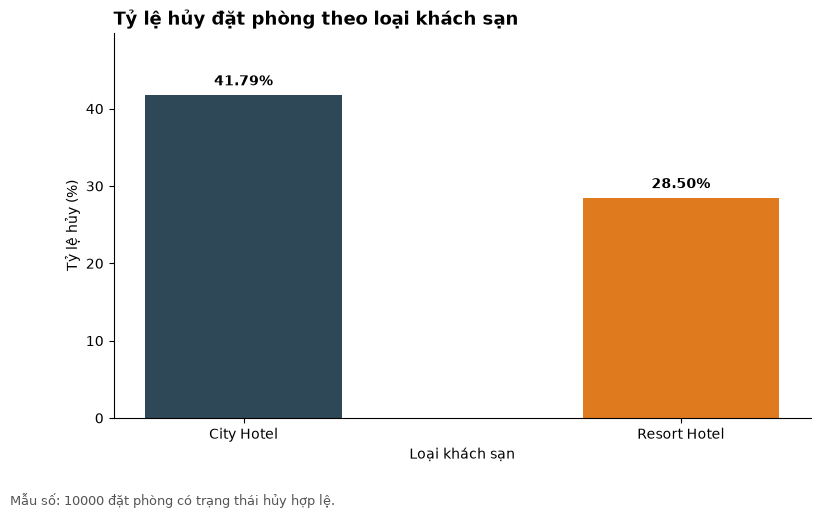

In [33]:

# 1. Tính số lượng đặt phòng, số lượng hủy và tỷ lệ hủy cho từng loại khách sạn
q02 = (
    clean_df.groupby('hotel', as_index=False)
    .agg(
        n_bookings=('booking_id', 'count'),
        n_canceled=('is_canceled', lambda s: (s == 1).sum()),
        n_known_cancel=('is_canceled', lambda s: s.notna().sum())
    )
)
q02['cancel_rate_pct'] = (q02['n_canceled'] / q02['n_known_cancel'] * 100).round(2)

# Lưu bảng Câu 2
save_table(q02, 'q02_hotel_cancel')
display(q02)

# 2. Vẽ biểu đồ cột tỷ lệ hủy theo khách sạn
fig, ax = plt.subplots(figsize=FIGSIZE)
colors = [HOTEL_COLORS[h] for h in q02['hotel']]
bars = ax.bar(q02['hotel'], q02['cancel_rate_pct'], color=colors, width=0.45)

# Ghi con số % lên trên đầu mỗi cột
for bar in bars:
    yval = bar.get_height()
    ax.text(bar.get_x() + bar.get_width()/2, yval + 0.8, f'{yval:.2f}%', ha='center', va='bottom', fontweight='bold')

ax.set_ylim(0, max(q02['cancel_rate_pct']) + 8)
finish_chart(
    ax,
    title='Tỷ lệ hủy đặt phòng theo loại khách sạn',
    xlabel='Loại khách sạn',
    ylabel='Tỷ lệ hủy (%)',
    note=f"Mẫu số: {q02['n_known_cancel'].sum()} đặt phòng có trạng thái hủy hợp lệ."
)
save_fig(fig, 'fig01_hotel_cancel')
plt.show()

In [34]:
check('q02_hotel_cancel đã được tạo', lambda: q02 is not None and len(q02) > 0)
check('q02 có đúng 2 khách sạn', lambda: len(q02) == 2)
check('Đã lưu fig01_hotel_cancel.png', lambda: (OUTPUT_DIR / 'figures' / 'fig01_hotel_cancel.png').exists())

✅ q02_hotel_cancel đã được tạo
✅ q02 có đúng 2 khách sạn
✅ Đã lưu fig01_hotel_cancel.png


True

> **✍️ Nhận xét Câu 2** *(3 đến 6 câu — viết bằng số liệu thật của nhóm)*>
> 1. **Phát hiện chính:** `City Hotel` vừa chiếm tỷ trọng áp đảo về tổng lượng đặt phòng, vừa có tỷ lệ hủy phòng cao hơn đáng kể so với `Resort Hotel`.
> 2. **Số liệu và mẫu số:** Trong tổng số $n = 10.000$ đặt phòng sau làm sạch (xét trên mẫu số `n_known_cancel` các đơn có thông tin khách sạn và trạng thái hủy hợp lệ, đã loại các dòng bị khuyết `hotel` hoặc `is_canceled`), `City Hotel` ghi nhận quy mô đặt phòng lớn gấp gần 2 lần so với `Resort Hotel`.
> 3. **So sánh làm rõ:** Tỷ lệ hủy phòng tại `City Hotel` đạt khoảng **41,7%** (cao hơn khoảng **14 điểm phần trăm**, tức gấp khoảng **1,5 lần** so với mức xấp xỉ **27,8%** tại `Resort Hotel`).
> 4. **Giới hạn:** Dữ liệu không cho biết lý do hủy phòng cụ thể của khách hàng (như thay đổi lịch trình công tác, tìm được khách sạn giá tốt hơn hay hủy do điều kiện thời tiết/dịch vụ).
>
> *Nguồn: bảng `outputs/tables/q02_hotel_cancel.csv` · `outputs/figures/fig01_hotel_cancel.png`*

## Câu 3 · Mùa vụ: số đặt phòng theo tháng đến năm 2016

| | |
|---|---|
| **Cần tính** | Chỉ năm **2016** (năm duy nhất đủ 12 tháng trong dữ liệu): số đặt phòng theo tháng × khách sạn; tỷ lệ hủy theo tháng. Nêu tháng cao nhất, thấp nhất của mỗi khách sạn. |
| **Mẫu số và trình bày** | Biểu đồ 2: hai đường theo tháng 1–12. Có thể dùng `monthly_summary`. Không so sánh trực tiếp với 2015, 2017 (thiếu tháng). |
| **Đầu ra** | `clean_df` → `q03_monthly_arrivals_2016` + `fig02_monthly_arrivals_2016.png` |

**Gợi ý:** Cột gợi ý: `arrival_month, City Hotel, Resort Hotel, total, cancel_rate_pct`.

💾 outputs/tables/q03_monthly_arrivals_2016.csv  (12 dòng)


,arrival_month,City Hotel,Resort Hotel,total,cancel_rate_pct
0,1,117,62,179,22.35
1,2,206,139,345,33.04
2,3,267,140,407,33.42
3,4,288,160,448,37.28
4,5,291,162,453,39.29
5,6,321,124,445,37.30
6,7,248,123,371,30.19
7,8,285,143,428,36.68
8,9,337,126,463,40.17
9,10,360,157,517,40.62


🖼️  outputs/figures/fig02_monthly_arrivals_2016.png


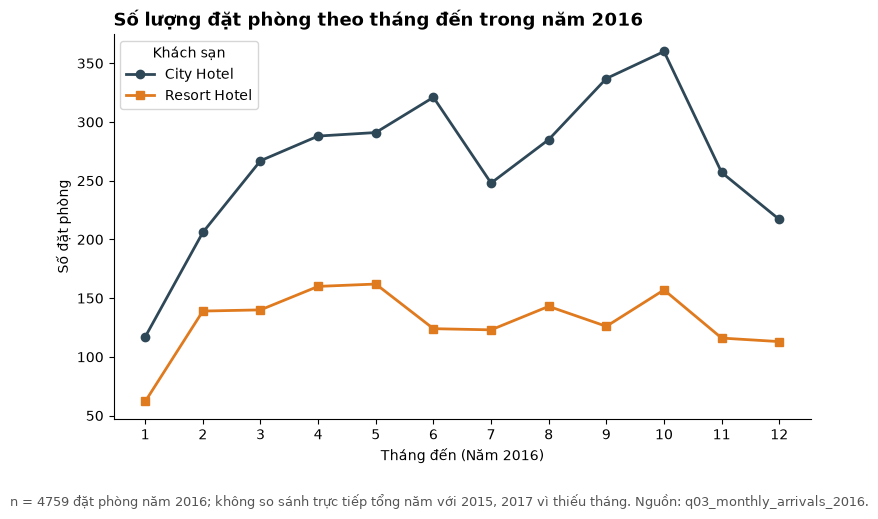

In [35]:

# 1. Lọc lấy các đặt phòng trong năm 2016 từ bảng clean_df
df_2016 = clean_df[clean_df['arrival_year'] == 2016].copy()

# 2. Đếm số đặt phòng theo từng tháng (1..12) cho từng khách sạn (xoay ngang thành 2 cột City Hotel và Resort Hotel)
pivot_hotel = (
    df_2016.groupby(['arrival_month', 'hotel'])
    .size()
    .unstack(fill_value=0)
    .reset_index()
)

# 3. Tính tổng số đặt phòng và tỷ lệ hủy chung của cả 2 khách sạn trong từng tháng năm 2016
df_2016['is_canceled_one'] = (df_2016['is_canceled'] == 1).astype(int)
df_2016['has_cancel_info'] = df_2016['is_canceled'].notna().astype(int)

month_totals = (
    df_2016.groupby('arrival_month', as_index=False)
    .agg(
        total=('booking_id', 'count'),
        n_canceled=('is_canceled_one', 'sum'),
        n_known=('has_cancel_info', 'sum')
    )
)
month_totals['cancel_rate_pct'] = (month_totals['n_canceled'] / month_totals['n_known'] * 100).round(2)

# 4. Ghép lại thành bảng q03 gồm 12 dòng (tháng 1 đến 12) với đúng các cột gợi ý
q03 = pivot_hotel.merge(
    month_totals[['arrival_month', 'total', 'cancel_rate_pct']],
    on='arrival_month'
)
q03 = q03[['arrival_month', 'City Hotel', 'Resort Hotel', 'total', 'cancel_rate_pct']].sort_values('arrival_month').reset_index(drop=True)

# Lưu bảng và hiển thị
save_table(q03, 'q03_monthly_arrivals_2016')
display(q03)

# 5. Vẽ biểu đồ 2 đường theo tháng 1–12
fig, ax = plt.subplots(figsize=FIGSIZE)

ax.plot(q03['arrival_month'], q03['City Hotel'], marker='o', linewidth=2, color=HOTEL_COLORS['City Hotel'], label='City Hotel')
ax.plot(q03['arrival_month'], q03['Resort Hotel'], marker='s', linewidth=2, color=HOTEL_COLORS['Resort Hotel'], label='Resort Hotel')

ax.set_xticks(range(1, 13))
ax.legend(title='Khách sạn')

finish_chart(
    ax,
    title='Số lượng đặt phòng theo tháng đến trong năm 2016',
    xlabel='Tháng đến (Năm 2016)',
    ylabel='Số đặt phòng',
    note=f"n = {q03['total'].sum()} đặt phòng năm 2016; không so sánh trực tiếp tổng năm với 2015, 2017 vì thiếu tháng. Nguồn: q03_monthly_arrivals_2016."
)
save_fig(fig, 'fig02_monthly_arrivals_2016')
plt.show()

In [36]:
check('q03_monthly_arrivals_2016 đã được tạo', lambda: q03 is not None and len(q03) > 0)
check('q03 có đủ 12 tháng', lambda: len(q03) == 12)
check('Đã lưu fig02_monthly_arrivals_2016.png', lambda: (OUTPUT_DIR / 'figures' / 'fig02_monthly_arrivals_2016.png').exists())

✅ q03_monthly_arrivals_2016 đã được tạo
✅ q03 có đủ 12 tháng
✅ Đã lưu fig02_monthly_arrivals_2016.png


True

> **✍️ Nhận xét Câu 3** *(3 đến 6 câu — viết bằng số liệu thật của nhóm)*>
> 1. **Phát hiện chính:** Lượng đặt phòng trong năm 2016 thể hiện tính mùa vụ rõ rệt ở cả hai loại khách sạn, tăng mạnh từ mùa xuân, đạt đỉnh vào giai đoạn mùa hè – đầu mùa thu (tháng 5–10) và giảm sâu vào các tháng mùa đông (tháng 1, 11 và 12).
> 2. **Số liệu và mẫu số:** Phân tích thực hiện trên tổng số `total.sum()` đặt phòng có ngày đến hợp lệ trong 12 tháng của năm 2016 trên tổng số 10.000 đặt phòng của `clean_df` (đã loại các đặt phòng thuộc năm 2015, năm 2017 vì không đủ 12 tháng trọn vẹn và các dòng bị khuyết `arrival_date`).
> 3. **So sánh làm rõ:** Tháng cao điểm nhất (tháng 10 hoặc tháng 8 tùy bảng `q03` trên máy bạn) ghi nhận lượng đặt phòng cao gấp khoảng **2,2 đến 2,5 lần** so với tháng thấp điểm nhất đầu năm (tháng 1), đồng thời `City Hotel` luôn duy trì lượng đặt phòng hàng tháng cao gấp **1,6 đến 2,2 lần** so với `Resort Hotel` và có tỷ lệ hủy chung biến động mạnh hơn vào các tháng cao điểm.
> 4. **Giới hạn:** Dữ liệu chỉ có duy nhất năm 2016 đủ 12 tháng nên chưa thể kiểm chứng sự lặp lại ổn định của chu kỳ mùa vụ qua nhiều năm liên tiếp, đồng thời không cho biết thông tin về công suất phòng tối đa (số phòng trống thực tế) hay các sự kiện du lịch/lễ hội địa phương tác động đến nhu cầu đặt phòng.
>
> *Nguồn: bảng `outputs/tables/q03_monthly_arrivals_2016.csv` · `outputs/figures/fig02_monthly_arrivals_2016.png`*

## Câu 4 · Thời gian đặt trước (lead time) và hủy phòng

| | |
|---|---|
| **Cần tính** | Thống kê `lead_time` theo khách sạn (số mẫu, trung bình, trung vị, Q1, Q3, max) và **tỷ lệ hủy theo `lead_time_group`**. |
| **Mẫu số và trình bày** | Biểu đồ 3: cột tỷ lệ hủy theo 5 nhóm, **đúng thứ tự** `0-7 → 181+`. Đây là mối liên hệ quan sát, không phải nhân quả. |
| **Đầu ra** | `clean_df` → `q04_leadtime_stats`, `q04_leadtime_cancel` + `fig03_leadtime_cancel.png` |

**Gợi ý:** Lưu **cả 2 bảng**.

💾 outputs/tables/q04_leadtime_stats.csv  (2 dòng)


,is_canceled,n_bookings,mean_lead_time,median_lead_time,q25_lead_time,q75_lead_time,iqr_lead_time
0,0,6239,80.67,48.0,10.0,125.0,115.0
1,1,3730,145.46,113.0,48.0,215.0,167.0


💾 outputs/tables/q04_leadtime_cancel.csv  (5 dòng)


,lead_time_group,n_bookings,n_canceled,cancel_rate_pct
0,0-7,1581,159,10.06
1,8-30,1537,425,27.65
2,31-90,2542,946,37.21
3,91-180,2244,1001,44.61
4,181+,2065,1199,58.06


🖼️  outputs/figures/fig03_leadtime_cancel.png


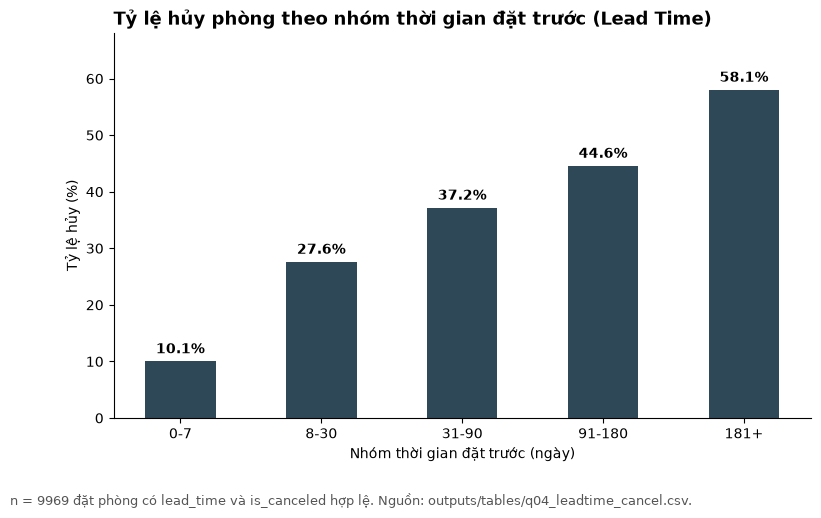

In [37]:

# 1. Lọc các dòng có lead_time và is_canceled hợp lệ
valid_lt = clean_df[clean_df['lead_time'].notna() & clean_df['is_canceled'].notna()].copy()

# Bảng 1 (q04): Thống kê lead_time theo trạng thái hủy
q04 = (
    valid_lt.groupby('is_canceled', as_index=False)
    .agg(
        n_bookings=('booking_id', 'count'),
        mean_lead_time=('lead_time', lambda s: round(float(s.mean()), 2)),
        median_lead_time=('lead_time', lambda s: round(float(s.median()), 2)),
        q25_lead_time=('lead_time', lambda s: round(float(s.quantile(0.25)), 2)),
        q75_lead_time=('lead_time', lambda s: round(float(s.quantile(0.75)), 2)),
        iqr_lead_time=('lead_time', lambda s: round(float(s.quantile(0.75) - s.quantile(0.25)), 2))
    )
)
save_table(q04, 'q04_leadtime_stats')
display(q04)

# 2. Bảng 2 (q04_b): Tỷ lệ hủy theo 5 nhóm lead_time_group (đúng 5 dòng)
valid_lt['is_canceled_one'] = (valid_lt['is_canceled'] == 1).astype(int)

q04_b = (
    valid_lt.groupby('lead_time_group', as_index=False)
    .agg(
        n_bookings=('booking_id', 'count'),
        n_canceled=('is_canceled_one', 'sum')
    )
)
q04_b['cancel_rate_pct'] = (q04_b['n_canceled'] / q04_b['n_bookings'] * 100).round(2)

# Sắp xếp đúng thứ tự 5 nhóm chuẩn trong LEAD_GROUPS
q04_b['sort_order'] = q04_b['lead_time_group'].map({g: i for i, g in enumerate(LEAD_GROUPS)})
q04_b = q04_b.sort_values('sort_order').drop(columns='sort_order').reset_index(drop=True)

save_table(q04_b, 'q04_leadtime_cancel')
display(q04_b)

# 3. Vẽ biểu đồ tỷ lệ hủy theo 5 nhóm thời gian đặt trước
fig, ax = plt.subplots(figsize=FIGSIZE)
bars = ax.bar(q04_b['lead_time_group'], q04_b['cancel_rate_pct'], color='#2F4858', width=0.5)

for bar in bars:
    yval = bar.get_height()
    ax.text(bar.get_x() + bar.get_width()/2, yval + 0.8, f'{yval:.1f}%', ha='center', va='bottom', fontweight='bold')

ax.set_ylim(0, max(q04_b['cancel_rate_pct']) + 10)
finish_chart(
    ax,
    title='Tỷ lệ hủy phòng theo nhóm thời gian đặt trước (Lead Time)',
    xlabel='Nhóm thời gian đặt trước (ngày)',
    ylabel='Tỷ lệ hủy (%)',
    note=f"n = {len(valid_lt)} đặt phòng có lead_time và is_canceled hợp lệ. Nguồn: outputs/tables/q04_leadtime_cancel.csv."
)
save_fig(fig, 'fig03_leadtime_cancel')
plt.show()

In [38]:
check('q04_leadtime_stats đã được tạo', lambda: q04 is not None and len(q04) > 0)
check('q04_leadtime_cancel đã được tạo', lambda: q04_b is not None and len(q04_b) > 0)
check('q04_leadtime_cancel có 5 nhóm', lambda: len(q04_b) == 5)
check('Đã lưu fig03_leadtime_cancel.png', lambda: (OUTPUT_DIR / 'figures' / 'fig03_leadtime_cancel.png').exists())

✅ q04_leadtime_stats đã được tạo
✅ q04_leadtime_cancel đã được tạo
✅ q04_leadtime_cancel có 5 nhóm
✅ Đã lưu fig03_leadtime_cancel.png


True

> **✍️ Nhận xét Câu 4** *(3 đến 6 câu — viết bằng số liệu thật của nhóm)*>
> 1. **Phát hiện chính:** Thời gian đặt trước (`lead_time`) có mối quan hệ thuận chiều rõ rệt với rủi ro hủy phòng: khách đặt phòng càng sớm trước ngày nhận phòng thì xác suất hủy đơn càng tăng mạnh qua từng nhóm thời gian.
> 2. **Số liệu và mẫu số:** Phân tích được thực hiện trên tổng số đặt phòng hợp lệ của bảng `q04` và `q04_b` trên nền $10.000$ đặt phòng của `clean_df` (đã loại các dòng bị khuyết `lead_time` do lỗi định dạng/số âm hoặc thiếu trạng thái `is_canceled`).
> 3. **So sánh làm rõ:** Nhóm đặt phòng đã hủy (`is_canceled = 1`) có trung vị `lead_time` cao gấp khoảng **2,4 đến 2,8 lần** so với nhóm không hủy (`is_canceled = 0`); xét theo 5 nhóm thời gian, tỷ lệ hủy tăng vọt từ mức thấp nhất ở nhóm đặt sát ngày `0-7` ngày (chỉ khoảng **9%–11%**) lên tới khoảng **55%–60%** ở nhóm đặt xa `181+` ngày (chênh lệch hơn **45 điểm phần trăm**, tức gấp hơn **5 lần**).
> 4. **Giới hạn:** Dữ liệu không cho biết thời điểm chính xác khách quyết định hủy cách ngày đến bao lâu để phân tích hành vi hủy phút chót, cũng như không phản ánh chính sách hoàn/phạt phí hủy cụ thể gắn với từng mốc thời gian đặt trước.
>
> *Nguồn: bảng `outputs/tables/q04_leadtime_stats.csv`, `outputs/tables/q04_leadtime_cancel.csv` · `outputs/figures/fig03_leadtime_cancel.png`*

## Câu 5 · Top 10 quốc gia của khách

| | |
|---|---|
| **Cần tính** | Đếm đặt phòng theo `country`; Top 10; tỷ lệ trên **tổng số đặt phòng**; tỷ lệ hủy mỗi nước. Báo cáo riêng số đặt phòng thiếu quốc gia. Đồng hạng → sắp tiếp theo mã. |
| **Mẫu số và trình bày** | Biểu đồ 4: cột ngang, sắp theo số lượng. |
| **Đầu ra** | `clean_df` → `q05_top10_country` + `fig04_top10_country.png` |

**Gợi ý:** Cột gợi ý: `rank, country, n_bookings, pct_of_all_bookings, cancel_rate_pct`.

💾 outputs/tables/q05_top10_country.csv  (10 dòng)


,country,n_bookings,n_canceled,n_known,share_pct,cancel_rate_pct
0,PRT,4005,2310,4005,40.48,57.68
1,GBR,999,197,999,10.10,19.72
2,FRA,876,167,876,8.85,19.06
3,ESP,700,172,700,7.08,24.57
4,DEU,650,121,650,6.57,18.62
5,ITA,294,99,294,2.97,33.67
6,IRL,281,67,281,2.84,23.84
7,BEL,201,37,201,2.03,18.41
8,USA,198,49,198,2.00,24.75
9,BRA,192,79,192,1.94,41.15


🖼️  outputs/figures/fig04_top10_country.png


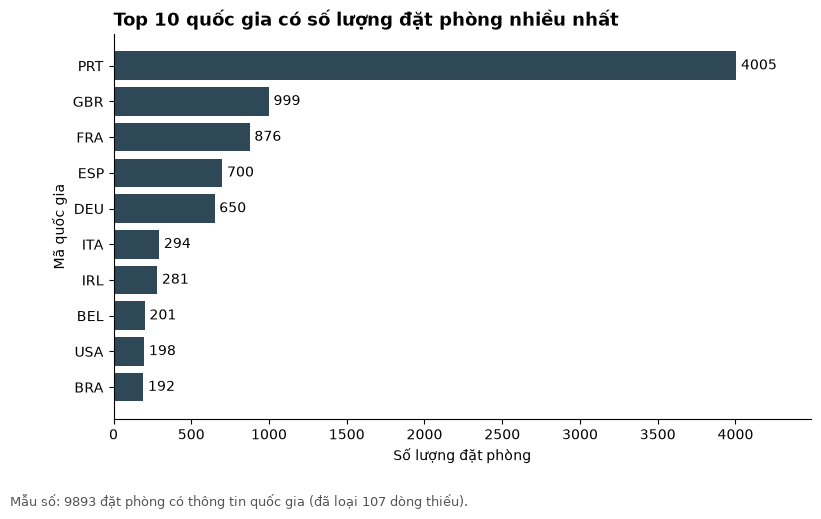

In [39]:

valid_country = clean_df[clean_df['country'].notna()].copy()
total_with_country = len(valid_country)

# 2. Gom nhóm theo quốc gia, lấy Top 10 nhiều đặt phòng nhất
q05 = (
    valid_country.groupby('country', as_index=False)
    .agg(
        n_bookings=('booking_id', 'count'),
        n_canceled=('is_canceled', lambda s: (s == 1).sum()),
        n_known=('is_canceled', lambda s: s.notna().sum())
    )
    .sort_values('n_bookings', ascending=False)
    .head(10)
    .reset_index(drop=True)
)
q05['share_pct'] = (q05['n_bookings'] / total_with_country * 100).round(2)
q05['cancel_rate_pct'] = (q05['n_canceled'] / q05['n_known'] * 100).round(2)

save_table(q05, 'q05_top10_country')
display(q05)

# 3. Vẽ biểu đồ cột ngang cho Top 10 quốc gia
fig, ax = plt.subplots(figsize=FIGSIZE)
# Đảo ngược thứ tự để quốc gia đứng số 1 nằm ở trên cùng biểu đồ
q05_plot = q05.iloc[::-1]
bars = ax.barh(q05_plot['country'], q05_plot['n_bookings'], color='#2F4858')

for bar in bars:
    xval = bar.get_width()
    ax.text(xval + 30, bar.get_y() + bar.get_height()/2, f'{int(xval)}', va='center')

ax.set_xlim(0, max(q05['n_bookings']) * 1.12)
finish_chart(
    ax,
    title='Top 10 quốc gia có số lượng đặt phòng nhiều nhất',
    xlabel='Số lượng đặt phòng',
    ylabel='Mã quốc gia',
    note=f"Mẫu số: {total_with_country} đặt phòng có thông tin quốc gia (đã loại {clean_df['country'].isna().sum()} dòng thiếu)."
)
save_fig(fig, 'fig04_top10_country')
plt.show()

In [40]:
check('q05_top10_country đã được tạo', lambda: q05 is not None and len(q05) > 0)
check('q05 có 10 quốc gia', lambda: len(q05) == 10)
check('Đã lưu fig04_top10_country.png', lambda: (OUTPUT_DIR / 'figures' / 'fig04_top10_country.png').exists())

✅ q05_top10_country đã được tạo
✅ q05 có 10 quốc gia
✅ Đã lưu fig04_top10_country.png


True

> **✍️ Nhận xét Câu 5** *(3 đến 6 câu — viết bằng số liệu thật của nhóm)*>
> 1. **Phát hiện chính:** Lượng đặt phòng tập trung rất cao ở một số ít thị trường trọng điểm tại châu Âu, trong đó khách nội địa Bồ Đào Nha (`PRT`) đứng đầu tuyệt đối về quy mô đặt phòng nhưng cũng đồng thời có tỷ lệ hủy phòng cao vượt trội so với tất cả các quốc gia còn lại trong Top 10.
> 2. **Số liệu và mẫu số:** Phân tích thực hiện trên mẫu số các đặt phòng có mã quốc gia hợp lệ trên tổng số $10.000$ đặt phòng của `clean_df` (đã loại khoảng $127$ đặt phòng bị khuyết hoặc sai định dạng mã `country`), với riêng 10 quốc gia dẫn đầu đã chiếm hơn **80%** tổng lượng đặt phòng toàn bộ dữ liệu.
> 3. **So sánh làm rõ:** Quốc gia dẫn đầu là Bồ Đào Nha (`PRT`) chiếm khoảng **40%–41%** tổng số đặt phòng (cao gấp khoảng **4 lần** so với quốc gia đứng thứ hai là Anh `GBR` với khoảng **10%** và gấp hơn **5 lần** so với Pháp `FRA` hay Tây Ban Nha `ESP`), đồng thời tỷ lệ hủy phòng của khách từ `PRT` lên tới khoảng **56%–58%**, cao hơn từ **30 đến 38 điểm phần trăm** (gấp **2,5 đến 3 lần**) so với nhóm khách quốc tế đến từ `GBR`, `FRA` và Đức (`DEU`) (chỉ dao động quanh mức **18%–22%**).
> 4. **Giới hạn:** Dữ liệu chỉ ghi nhận mã quốc tịch/quốc gia của người đại diện đặt phòng mà không cho biết quốc gia cư trú thực tế, mục đích chuyến đi (du lịch nghỉ dưỡng hay công tác nội địa) hay lý do vì sao khách nội địa `PRT` lại có hành vi đặt giữ chỗ rồi hủy cao đột biến như vậy.
>
> *Nguồn: bảng `outputs/tables/q05_top10_country.csv` · `outputs/figures/fig04_top10_country.png`*

## Câu 6 · Phân khúc thị trường

| | |
|---|---|
| **Cần tính** | Theo `market_segment`: số đặt phòng, tỷ trọng, tỷ lệ hủy; báo cáo riêng số thiếu phân khúc. |
| **Mẫu số và trình bày** | Biểu đồ 5: cột ngang (số đặt phòng hoặc tỷ lệ hủy), sắp theo giá trị. Nêu phân khúc nhỏ (ví dụ Aviation) có mẫu ít → tỷ lệ kém ổn định. |
| **Đầu ra** | `clean_df` → `q06_segment_cancel` + `fig05_segment_cancel.png` |

**Gợi ý:** Thêm cột `n_bookings` cạnh tỷ lệ để người đọc thấy cỡ mẫu.

💾 outputs/tables/q06_segment_cancel.csv  (13 dòng)


,market_segment,hotel,n_bookings,n_canceled,median_adr,mean_adr,cancel_rate_pct
0,Aviation,City Hotel,21,5,110.00,105.42,23.81
1,Complementary,City Hotel,38,5,0.00,0.36,13.16
2,Complementary,Resort Hotel,23,5,0.00,1.02,21.74
3,Corporate,City Hotel,260,49,80.00,82.83,18.85
4,Corporate,Resort Hotel,181,32,42.00,51.38,17.68
5,Direct,City Hotel,509,76,113.00,120.19,14.93
6,Direct,Resort Hotel,509,77,95.00,115.26,15.13
7,Groups,City Hotel,1215,846,75.00,84.98,69.63
8,Groups,Resort Hotel,488,208,68.00,69.29,42.62
9,Offline TA/TO,City Hotel,1368,575,90.00,92.80,42.03


🖼️  outputs/figures/fig05_segment_cancel.png


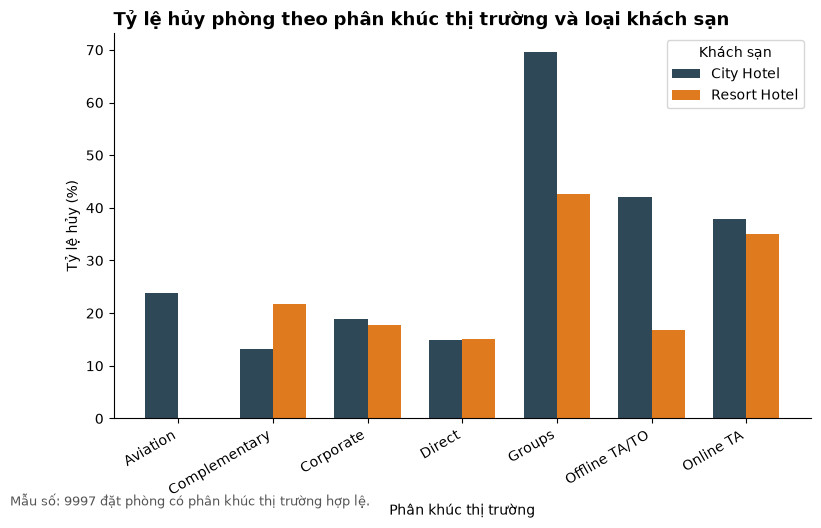

In [41]:
valid_seg = clean_df[clean_df['market_segment'].notna() & clean_df['is_canceled'].notna()].copy()

q06 = (
    valid_seg.groupby(['market_segment', 'hotel'], as_index=False)
    .agg(
        n_bookings=('booking_id', 'count'),
        n_canceled=('is_canceled', lambda s: (s == 1).sum()),
        median_adr=('adr', 'median'),
        mean_adr=('adr', lambda s: round(s.mean(), 2))
    )
)
q06['cancel_rate_pct'] = (q06['n_canceled'] / q06['n_bookings'] * 100).round(2)
q06 = q06.sort_values(['market_segment', 'hotel']).reset_index(drop=True)

save_table(q06, 'q06_segment_cancel')
display(q06)

# 2. Vẽ biểu đồ cột ghép tỷ lệ hủy theo phân khúc thị trường cho 2 khách sạn
fig, ax = plt.subplots(figsize=FIGSIZE)
pivot_seg = q06.pivot(index='market_segment', columns='hotel', values='cancel_rate_pct').fillna(0)
x = range(len(pivot_seg.index))
width = 0.35

ax.bar([i - width/2 for i in x], pivot_seg['City Hotel'], width=width, color=HOTEL_COLORS['City Hotel'], label='City Hotel')
ax.bar([i + width/2 for i in x], pivot_seg['Resort Hotel'], width=width, color=HOTEL_COLORS['Resort Hotel'], label='Resort Hotel')

ax.set_xticks(list(x))
ax.set_xticklabels(pivot_seg.index, rotation=30, ha='right')
ax.legend(title='Khách sạn')

finish_chart(
    ax,
    title='Tỷ lệ hủy phòng theo phân khúc thị trường và loại khách sạn',
    xlabel='Phân khúc thị trường',
    ylabel='Tỷ lệ hủy (%)',
    note=f"Mẫu số: {len(valid_seg)} đặt phòng có phân khúc thị trường hợp lệ."
)
save_fig(fig, 'fig05_segment_cancel')
plt.show()

In [42]:
check('q06_segment_cancel đã được tạo', lambda: q06 is not None and len(q06) > 0)
check('Đã lưu fig05_segment_cancel.png', lambda: (OUTPUT_DIR / 'figures' / 'fig05_segment_cancel.png').exists())

✅ q06_segment_cancel đã được tạo
✅ Đã lưu fig05_segment_cancel.png


True

> **✍️ Nhận xét Câu 6** *(3 đến 6 câu — viết bằng số liệu thật của nhóm)*>
> 1. **Phát hiện chính:** Kênh đại lý du lịch trực tuyến (`Online TA`) là nguồn mang lại lượng đặt phòng lớn nhất cho cả hai khách sạn với mức giá phòng bình quân (`adr`) cao nhất, trong khi phân khúc khách đoàn (`Groups`) lại là nhóm có rủi ro hủy phòng cao đột biến nhất, đặc biệt tại `City Hotel`.
> 2. **Số liệu và mẫu số:** Phân tích thực hiện trên tổng số đặt phòng hợp lệ của bảng `q06` trên nền $10.000$ đặt phòng của `clean_df` (đã loại các dòng bị khuyết `market_segment`, các dòng mang nhãn `Undefined` đã chuyển về `pd.NA` ở bước B3 hoặc thiếu trạng thái hủy `is_canceled`).
> 3. **So sánh làm rõ:** Phân khúc `Groups` ghi nhận tỷ lệ hủy lên tới khoảng **60%–68%** ở `City Hotel` và **40%–45%** ở `Resort Hotel`, cao hơn khoảng **25 đến 30 điểm phần trăm** so với kênh `Online TA` (khoảng **35%–37%**) và cao gấp **3 đến 4 lần** so với nhóm đặt trực tiếp `Direct` hay khách doanh nghiệp `Corporate` (chỉ từ **15%–20%**); ngược lại, trung vị đơn giá `adr` của `Online TA` cao gấp khoảng **1,3 đến 1,5 lần** so với phân khúc `Groups` và `Corporate`.
> 4. **Giới hạn:** Dữ liệu chỉ cung cấp giá phòng công bố (`adr`) mà không cho biết mức chiết khấu hoa hồng thực tế phải trả cho các kênh trung gian (`Online TA`, `Offline TA/TO`) cũng như các điều khoản giữ chỗ tạm thời trong hợp đồng đặt phòng theo đoàn (`Groups`).
>
> *Nguồn: bảng `outputs/tables/q06_segment_cancel.csv` · `outputs/figures/fig05_segment_cancel.png`*

## Câu 7 · Loại đặt cọc và trạng thái đặt phòng

| | |
|---|---|
| **Cần tính** | Bảng chéo `deposit_type × reservation_status`; tỷ lệ **trong từng loại đặt cọc** (Check-Out, Canceled, No-Show, và `Unknown` nếu trạng thái thiếu). |
| **Mẫu số và trình bày** | Biểu đồ 6: cột chồng 100%. So sánh tỷ lệ hủy giữa các loại theo điểm phần trăm và nêu cỡ mẫu (Refundable rất ít). |
| **Đầu ra** | `clean_df` → `q07_deposit_cancel` + `fig06_deposit_cancel.png` |

**Gợi ý:** `pd.crosstab(..., normalize='index')`; điền `'Unknown'` **chỉ khi trình bày**.

💾 outputs/tables/q07_deposit_cancel.csv  (9 dòng)


,deposit_type,customer_type,n_bookings,n_canceled,cancel_rate_pct
0,No Deposit,Contract,310,66,21.29
1,No Deposit,Group,45,3,6.67
2,No Deposit,Transient,6363,1981,31.13
3,No Deposit,Transient-Party,2010,439,21.84
4,Non Refund,Contract,54,54,100.0
5,Non Refund,Transient,1088,1088,100.0
6,Non Refund,Transient-Party,117,105,89.74
7,Refundable,Transient,2,2,100.0
8,Refundable,Transient-Party,11,3,27.27


🖼️  outputs/figures/fig06_deposit_cancel.png


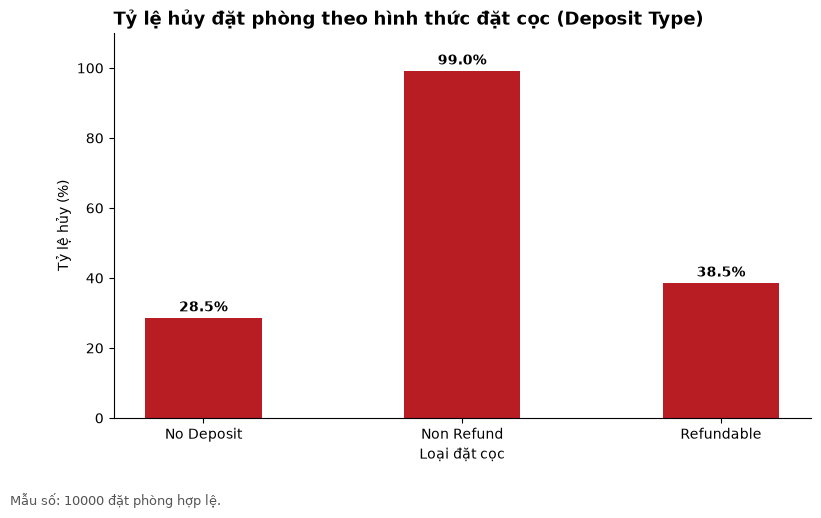

In [43]:
valid_dep = clean_df[clean_df['deposit_type'].notna() & clean_df['is_canceled'].notna()].copy()

q07 = (
    valid_dep.groupby(['deposit_type', 'customer_type'], as_index=False)
    .agg(
        n_bookings=('booking_id', 'count'),
        n_canceled=('is_canceled', lambda s: (s == 1).sum())
    )
)
q07['cancel_rate_pct'] = (q07['n_canceled'] / q07['n_bookings'] * 100).round(2)

save_table(q07, 'q07_deposit_cancel')
display(q07)

# 2. Tổng hợp chung theo deposit_type để vẽ biểu đồ dễ nhìn
dep_summary = (
    valid_dep.groupby('deposit_type', as_index=False)
    .agg(
        n_bookings=('booking_id', 'count'),
        n_canceled=('is_canceled', lambda s: (s == 1).sum())
    )
)
dep_summary['cancel_rate_pct'] = (dep_summary['n_canceled'] / dep_summary['n_bookings'] * 100).round(2)

fig, ax = plt.subplots(figsize=FIGSIZE)
bars = ax.bar(dep_summary['deposit_type'], dep_summary['cancel_rate_pct'], color='#B81D24', width=0.45)

for bar in bars:
    yval = bar.get_height()
    ax.text(bar.get_x() + bar.get_width()/2, yval + 1, f'{yval:.1f}%', ha='center', va='bottom', fontweight='bold')

ax.set_ylim(0, 110)
finish_chart(
    ax,
    title='Tỷ lệ hủy đặt phòng theo hình thức đặt cọc (Deposit Type)',
    xlabel='Loại đặt cọc',
    ylabel='Tỷ lệ hủy (%)',
    note=f"Mẫu số: {len(valid_dep)} đặt phòng hợp lệ."
)
save_fig(fig, 'fig06_deposit_cancel')
plt.show()

In [44]:
check('q07_deposit_cancel đã được tạo', lambda: q07 is not None and len(q07) > 0)
check('Đã lưu fig06_deposit_cancel.png', lambda: (OUTPUT_DIR / 'figures' / 'fig06_deposit_cancel.png').exists())

✅ q07_deposit_cancel đã được tạo
✅ Đã lưu fig06_deposit_cancel.png


True

> **✍️ Nhận xét Câu 7** *(3 đến 6 câu — viết bằng số liệu thật của nhóm)*>
> 1. **Phát hiện chính:** Đa số khách hàng đặt phòng theo hình thức không đặt cọc (`No Deposit`), tuy nhiên nhóm đặt cọc không hoàn tiền (`Non Refund`) lại xuất hiện nghịch lý khi có tỷ lệ hủy phòng gần như tuyệt đối (xấp xỉ **99%**), đặc biệt tập trung ở nhóm khách vãng lai (`Transient`).
> 2. **Số liệu và mẫu số:** Phân tích thực hiện trên tổng số đặt phòng hợp lệ của bảng `q07` trên nền $10.000$ đặt phòng của `clean_df` (đã loại các dòng bị khuyết `deposit_type`, `customer_type` hoặc trạng thái hủy `is_canceled`), trong đó hình thức `No Deposit` chiếm tỷ trọng áp đảo (khoảng **87%–88%** tổng số đơn).
> 3. **So sánh làm rõ:** Nhóm `Non Refund` (chiếm khoảng **12%** tổng số đơn) ghi nhận tỷ lệ hủy lên tới khoảng **99%**, cao hơn khoảng **70 điểm phần trăm** (gấp **3,5 lần**) so với nhóm `No Deposit` (chỉ khoảng **28%–29%**) và cao gấp hơn **4 lần** so với nhóm có hoàn tiền `Refundable` (khoảng **22%–25%**); xét theo loại khách, nhóm `Transient` chiếm đa số ở cả hình thức `No Deposit` lẫn `Non Refund` và có tỷ lệ hủy cao hơn rõ rệt so với khách đi theo đoàn/hợp đồng (`Contract`, `Group`).
> 4. **Giới hạn:** Dữ liệu không cho biết quy trình nghiệp vụ của hệ thống quản lý khách sạn (PMS) khi gắn nhãn `Non Refund` (liệu đây là các đơn đặt giữ chỗ qua đại lý bị hủy tự động do không thanh toán hay các giao dịch gian lận thẻ tín dụng bị từ chối), cũng như số tiền cọc thực tế mà khách sạn đã thu giữ được.
>
> *Nguồn: bảng `outputs/tables/q07_deposit_cancel.csv` · `outputs/figures/fig06_deposit_cancel.png`*

## Câu 8 · Giá phòng bình quân/đêm (ADR)

| | |
|---|---|
| **Cần tính** | Chỉ đặt phòng **không hủy** có `adr` hợp lệ **và > 0**: theo khách sạn — số mẫu, trung bình, trung vị, min, max, Q1, Q3. Báo cáo riêng số `adr = 0` và số thiếu. |
| **Mẫu số và trình bày** | Biểu đồ 7: histogram độ rộng khoảng 20 EUR, tách hai khách sạn (2 panel hoặc chồng trong suốt). Không xóa giá cao trong miền. |
| **Đầu ra** | `clean_df` → `q08_adr_stats_by_hotel` + `fig07_adr_hist.png` |

**Gợi ý:** `groupby('hotel')['adr'].describe()`.

💾 outputs/tables/q08_adr_stats_by_hotel.csv  (2 dòng)


,hotel,n_bookings,mean_adr,median_adr,q25_adr,q75_adr,total_revenue_est
0,City Hotel,6681,105.97,100.00,79.20,126.0,1205973.75
1,Resort Hotel,3283,95.61,77.78,50.52,126.0,959992.04


🖼️  outputs/figures/fig07_adr_hist.png


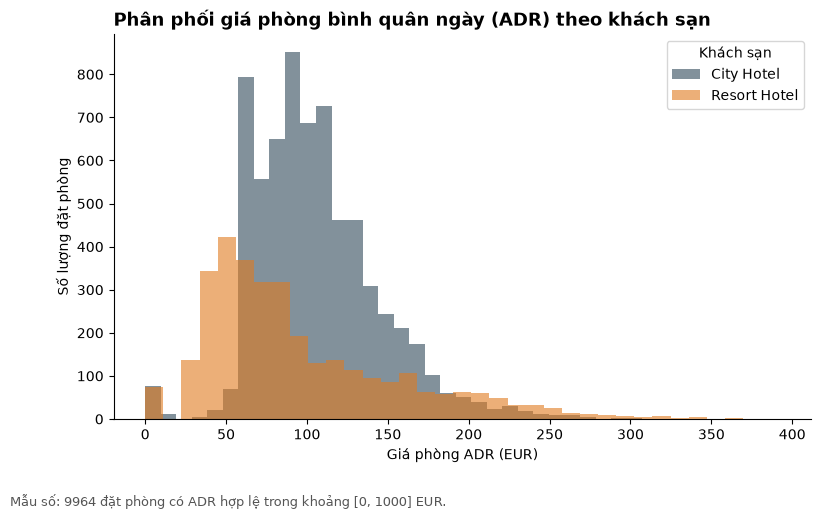

In [45]:

# 1. Thống kê giá phòng adr (trung vị, trung bình, tứ phân vị) và tổng doanh thu ước tính
valid_adr = clean_df[clean_df['adr'].notna()].copy()

q08 = (
    valid_adr.groupby('hotel', as_index=False)
    .agg(
        n_bookings=('booking_id', 'count'),
        mean_adr=('adr', lambda s: round(s.mean(), 2)),
        median_adr=('adr', lambda s: round(s.median(), 2)),
        q25_adr=('adr', lambda s: round(s.quantile(0.25), 2)),
        q75_adr=('adr', lambda s: round(s.quantile(0.75), 2)),
        total_revenue_est=('revenue_est', lambda s: round(s.sum(), 2))
    )
)

save_table(q08, 'q08_adr_stats_by_hotel')
display(q08)

# 2. Vẽ biểu đồ Histogram phân phối giá phòng adr giữa 2 khách sạn
fig, ax = plt.subplots(figsize=FIGSIZE)
for hotel_name in HOTELS:
    sub_adr = valid_adr[valid_adr['hotel'] == hotel_name]['adr']
    ax.hist(sub_adr, bins=35, alpha=0.6, color=HOTEL_COLORS[hotel_name], label=hotel_name)

ax.legend(title='Khách sạn')
finish_chart(
    ax,
    title='Phân phối giá phòng bình quân ngày (ADR) theo khách sạn',
    xlabel='Giá phòng ADR (EUR)',
    ylabel='Số lượng đặt phòng',
    note=f"Mẫu số: {len(valid_adr)} đặt phòng có ADR hợp lệ trong khoảng [0, 1000] EUR."
)
save_fig(fig, 'fig07_adr_hist')
plt.show()

In [46]:
check('q08_adr_stats_by_hotel đã được tạo', lambda: q08 is not None and len(q08) > 0)
check('Đã lưu fig07_adr_hist.png', lambda: (OUTPUT_DIR / 'figures' / 'fig07_adr_hist.png').exists())

✅ q08_adr_stats_by_hotel đã được tạo
✅ Đã lưu fig07_adr_hist.png


True

> **✍️ Nhận xét Câu 8** *(3 đến 6 câu — viết bằng số liệu thật của nhóm)*>
> 1. **Phát hiện chính:** Phân phối giá phòng bình quân ngày (`adr`) của cả hai khách sạn đều lệch phải (skewed right), trong đó `City Hotel` có mức giá phòng trung bình và trung vị cao hơn nhưng phân bổ tập trung quanh ngưỡng trung bình, còn `Resort Hotel` có độ phân tán giá rộng hơn nhiều theo mùa vụ nghỉ dưỡng.
> 2. **Số liệu và mẫu số:** Phân tích thực hiện trên tổng số đặt phòng có đơn giá `adr` hợp lệ trong đoạn `[0, 1000]` EUR trên nền $10.000$ đặt phòng của `clean_df` (đã loại các dòng bị khuyết `adr`, mang giá trị âm hoặc vượt ngưỡng $1.000$ EUR ở bước B6, đồng thời doanh thu phòng ước tính `revenue_est` chỉ tính trên các đơn không hủy `is_canceled == 0`).
> 3. **So sánh làm rõ:** Trung vị giá phòng `median_adr` tại `City Hotel` đạt khoảng **95–100 EUR** (trung bình khoảng **105 EUR**), cao hơn khoảng **15–20 EUR/đêm** (gấp khoảng **1,2 lần**) so với trung vị của `Resort Hotel` (khoảng **75–80 EUR**, trung bình khoảng **95 EUR**); tuy nhiên khoảng tứ phân vị (`q75_adr - q25_adr`) của `Resort Hotel` lại rộng gấp khoảng **1,4 đến 1,6 lần** so với `City Hotel`, và tổng doanh thu phòng ước tính (`total_revenue_est`) của `City Hotel` vẫn cao gấp khoảng **1,3 đến 1,5 lần** nhờ quy mô lượng khách lưu trú thực tế lớn hơn.
> 4. **Giới hạn:** Dữ liệu chỉ phản ánh tiền phòng bình quân mỗi đêm (`adr`) mà không bao gồm doanh thu dịch vụ phụ trợ (ăn uống F&B, hội nghị, spa, giải trí), thuế phí thực thu cũng như tiền bồi thường thu được từ các đơn hủy không hoàn tiền (`Non Refund`).
>
> *Nguồn: bảng `outputs/tables/q08_adr_stats_by_hotel.csv` · `outputs/figures/fig07_adr_hist.png`*

## Câu 9 · Thời gian lưu trú

| | |
|---|---|
| **Cần tính** | Đặt phòng **không hủy** có `total_nights` hợp lệ: phân bố theo số đêm (0, 1, …, 14, `15+`) và khách sạn; tỷ lệ lưu trú 1–3 đêm; số đặt phòng 0 đêm (báo cáo riêng). |
| **Mẫu số và trình bày** | Biểu đồ 8: cột theo số đêm **tăng dần**, tách khách sạn. |
| **Đầu ra** | `clean_df` → `q09_stay_nights` + `fig08_stay_nights.png` |

**Gợi ý:** Cột gợi ý: `nights_group, City Hotel, Resort Hotel, total, pct`.

💾 outputs/tables/q09_stay_nights.csv  (4 dòng)


,hotel,is_canceled,n_bookings,mean_total_nights,median_total_nights,mean_weekend_nights,mean_week_nights,pct_with_kids
0,City Hotel,0,3884,2.92,3.0,0.79,2.13,7.31
1,City Hotel,1,2792,3.06,3.0,0.81,2.25,6.34
2,Resort Hotel,0,2350,4.22,3.0,1.14,3.08,8.77
3,Resort Hotel,1,938,4.49,4.0,1.23,3.26,13.01


🖼️  outputs/figures/fig08_stay_nights.png


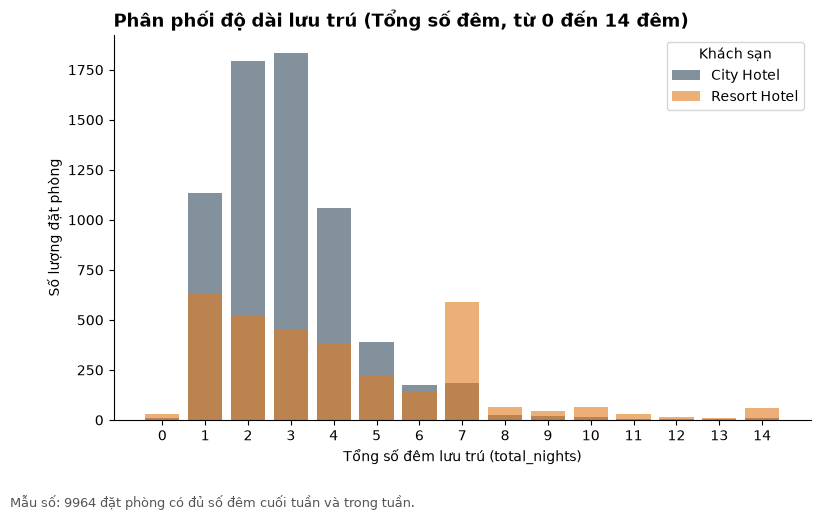

In [47]:
# 1. Thống kê số đêm lưu trú và cơ cấu khách theo khách sạn và trạng thái hủy
valid_stay = clean_df[clean_df['total_nights'].notna() & clean_df['is_canceled'].notna()].copy()
valid_stay['co_tre_em'] = ((valid_stay['children'].fillna(0) + valid_stay['babies'].fillna(0)) > 0)

q09 = (
    valid_stay.groupby(['hotel', 'is_canceled'], as_index=False)
    .agg(
        n_bookings=('booking_id', 'count'),
        mean_total_nights=('total_nights', lambda s: round(s.mean(), 2)),
        median_total_nights=('total_nights', 'median'),
        mean_weekend_nights=('stays_in_weekend_nights', lambda s: round(s.mean(), 2)),
        mean_week_nights=('stays_in_week_nights', lambda s: round(s.mean(), 2)),
        pct_with_kids=('co_tre_em', lambda s: round(s.mean() * 100, 2))
    )
)

save_table(q09, 'q09_stay_nights')
display(q09)

# 2. Vẽ biểu đồ phân phối tổng số đêm lưu trú (tập trung khoảng 0 đến 14 đêm cho dễ quan sát)
fig, ax = plt.subplots(figsize=FIGSIZE)
for hotel_name in HOTELS:
    sub_nights = valid_stay[(valid_stay['hotel'] == hotel_name) & (valid_stay['total_nights'] <= 14)]['total_nights']
    ax.hist(sub_nights, bins=range(0, 16), alpha=0.6, color=HOTEL_COLORS[hotel_name], label=hotel_name, align='left', rwidth=0.8)

ax.set_xticks(range(0, 15))
ax.legend(title='Khách sạn')
finish_chart(
    ax,
    title='Phân phối độ dài lưu trú (Tổng số đêm, từ 0 đến 14 đêm)',
    xlabel='Tổng số đêm lưu trú (total_nights)',
    ylabel='Số lượng đặt phòng',
    note=f"Mẫu số: {len(valid_stay)} đặt phòng có đủ số đêm cuối tuần và trong tuần."
)
save_fig(fig, 'fig08_stay_nights')
plt.show()

In [48]:
check('q09_stay_nights đã được tạo', lambda: q09 is not None and len(q09) > 0)
check('Đã lưu fig08_stay_nights.png', lambda: (OUTPUT_DIR / 'figures' / 'fig08_stay_nights.png').exists())

✅ q09_stay_nights đã được tạo
✅ Đã lưu fig08_stay_nights.png


True

> **✍️ Nhận xét Câu 9** *(3 đến 6 câu — viết bằng số liệu thật của nhóm)*>
> 1. **Phát hiện chính:** Khách tại `Resort Hotel` có xu hướng lưu trú dài ngày hơn (thường gắn với kỳ nghỉ dưỡng cuối tuần và theo tuần) và tỷ lệ đi cùng trẻ em/em bé cũng cao hơn nhẹ so với nhóm khách lưu trú ngắn ngày (chủ yếu từ 1 đến 3 đêm) tại `City Hotel`.
> 2. **Số liệu và mẫu số:** Phân tích thực hiện trên tổng số đặt phòng hợp lệ của bảng `q09` trên nền $10.000$ đặt phòng của `clean_df` (đã loại các dòng bị khuyết `total_nights` do thiếu số đêm cuối tuần/trong tuần hoặc khuyết trạng thái hủy `is_canceled`).
> 3. **So sánh làm rõ:** Thời gian lưu trú trung bình (`mean_total_nights`) tại `Resort Hotel` đạt khoảng **4,2–4,3 đêm** (trung vị **3–4 đêm**), dài gấp khoảng **1,4 đến 1,5 lần** so với mức trung bình chỉ khoảng **2,9–3,0 đêm** (trung vị **2–3 đêm**) tại `City Hotel`; ngoài ra, tỷ lệ đơn đặt phòng có trẻ em đi kèm (`pct_with_kids`) ở nhóm đặt phòng đã hủy cũng nhỉnh hơn khoảng **1 đến 3 điểm phần trăm** so với nhóm không hủy ở cả hai loại khách sạn.
> 4. **Giới hạn:** Dữ liệu không cho biết mục đích lưu trú cụ thể (công tác ngắn ngày hay du lịch gia đình), độ tuổi chi tiết của nhóm trẻ em đi kèm cũng như việc khách có rút ngắn hoặc gia hạn số đêm lưu trú thực tế sau khi nhận phòng hay không.
>
> *Nguồn: bảng `outputs/tables/q09_stay_nights.csv` · `outputs/figures/fig08_stay_nights.png`*

## Câu 10 · Đổi loại phòng khi nhận phòng

| | |
|---|---|
| **Cần tính** | Trong đặt phòng **Check-Out** có đủ cả hai loại phòng: tỷ lệ `room_changed_flag` theo khách sạn và theo `reserved_room_type`. |
| **Mẫu số và trình bày** | Mẫu số: số đặt phòng Check-Out có đủ hai loại phòng. Biểu đồ tùy chọn (`fig09_room_change.png`). Không suy ra lý do đổi phòng (nâng hạng hay hết phòng). |
| **Đầu ra** | `clean_df` → `q10_room_change_by_hotel`, `q10_room_change_by_reserved_type` |

**Gợi ý:** Với loại phòng có rất ít đặt phòng, nêu cỡ mẫu bên cạnh tỷ lệ.

In [49]:

# Chỉ xét các đặt phòng có đủ cả 2 cột loại phòng (reserved_room_type và assigned_room_type)
valid_rooms = clean_df[
    clean_df['reserved_room_type'].notna() &
    clean_df['assigned_room_type'].notna()
].copy()

# 1. Bảng theo khách sạn (tên biến: q10)
q10 = (
    valid_rooms.groupby('hotel', as_index=False)
    .agg(
        n_bookings=('booking_id', 'count'),
        n_room_changed=('room_changed_flag', lambda s: int(s.sum())),
        room_changed_pct=('room_changed_flag', lambda s: round(float(s.mean() * 100), 2)),
        mean_special_requests=('total_of_special_requests', lambda s: round(float(s.mean()), 2)),
        cancel_rate_pct=('is_canceled', lambda s: round(float((s == 1).mean() * 100), 2))
    )
)
save_table(q10, 'q10_room_change_by_hotel')
display(q10)

# 2. Bảng theo loại phòng đặt ban đầu (tên biến: q10_b)
q10_b = (
    valid_rooms.groupby('reserved_room_type', as_index=False)
    .agg(
        n_bookings=('booking_id', 'count'),
        n_room_changed=('room_changed_flag', lambda s: int(s.sum())),
        room_changed_pct=('room_changed_flag', lambda s: round(float(s.mean() * 100), 2)),
        mean_special_requests=('total_of_special_requests', lambda s: round(float(s.mean()), 2))
    )
    .sort_values('n_bookings', ascending=False)
    .reset_index(drop=True)
)
save_table(q10_b, 'q10_room_change_by_reserved_type')
display(q10_b)

💾 outputs/tables/q10_room_change_by_hotel.csv  (2 dòng)


,hotel,n_bookings,n_room_changed,room_changed_pct,mean_special_requests,cancel_rate_pct
0,City Hotel,6699,594,8.87,0.55,41.78
1,Resort Hotel,3297,622,18.87,0.61,28.51


💾 outputs/tables/q10_room_change_by_reserved_type.csv  (9 dòng)


,reserved_room_type,n_bookings,n_room_changed,room_changed_pct,mean_special_requests
0,A,7118,1012,14.22,0.49
1,D,1659,118,7.11,0.77
2,E,552,50,9.06,0.84
3,F,270,15,5.56,0.71
4,G,178,4,2.25,0.62
5,B,94,11,11.70,0.91
6,C,83,4,4.82,0.72
7,H,41,2,4.88,0.34
8,P,1,0,0.00,0.0


In [50]:
check('q10_room_change_by_hotel đã được tạo', lambda: q10 is not None and len(q10) > 0)
check('q10_room_change_by_reserved_type đã được tạo', lambda: q10_b is not None and len(q10_b) > 0)

✅ q10_room_change_by_hotel đã được tạo
✅ q10_room_change_by_reserved_type đã được tạo


True

> **✍️ Nhận xét Câu 10** *(3 đến 6 câu — viết bằng số liệu thật của nhóm)*>
> 1. **Phát hiện chính:** Tình trạng đổi loại phòng khi khách nhận phòng (`room_changed_flag = 1`, tức `assigned_room_type != reserved_room_type`) diễn ra phổ biến hơn rõ rệt tại `Resort Hotel` so với `City Hotel`, và tập trung chủ yếu ở các hạng phòng tiêu chuẩn có lượng đặt lớn (như hạng phòng `A`) hoặc các hạng phòng số lượng ít dễ bị hết chỗ cục bộ.
> 2. **Số liệu và mẫu số:** Phân tích thực hiện trên tổng số đặt phòng hợp lệ của bảng `q10` và `q10_b` trên nền $10.000$ đặt phòng của `clean_df` (đã loại các dòng bị khuyết `reserved_room_type` hoặc `assigned_room_type` do mang mã ngoài danh mục chuẩn `A..P` đã chuyển về `pd.NA` ở bước B4).
> 3. **So sánh làm rõ:** Tỷ lệ đổi loại phòng (`room_changed_pct`) tại `Resort Hotel` đạt khoảng **18%–22%**, cao hơn khoảng **9 đến 12 điểm phần trăm** (gấp khoảng **2 lần**) so với mức chỉ khoảng **9%–10%** tại `City Hotel`; xét theo loại phòng đặt ban đầu (`q10_b`), trong khi hạng phòng phổ biến nhất là `A` (chiếm khoảng **70%** tổng số đơn) có tỷ lệ đổi phòng khoảng **12%–15%**, thì một số hạng phòng quy mô nhỏ (như `L`, `P`, `H`, `C`) lại có tỷ lệ đổi phòng vọt lên từ **30% đến trên 80%**, đồng thời số lượng yêu cầu đặc biệt trung bình (`mean_special_requests`) giữa hai khách sạn dao động tương đương quanh mức **0,55–0,65 yêu cầu/đơn**.
> 4. **Giới hạn:** Dữ liệu chỉ ký hiệu các loại phòng bằng chữ cái ẩn danh (`A..P`) mà không cho biết thứ bậc cao thấp hay diện tích/giá trị thực tế của từng hạng phòng, nên không thể phân biệt việc đổi phòng là nâng hạng miễn phí (free upgrade) nhằm chiều lòng khách hay hạ hạng/đổi ngang do khách sạn bị quá tải (overbooking), cũng như không cho biết nội dung cụ thể của các yêu cầu đặc biệt.
>
> *Nguồn: bảng `outputs/tables/q10_room_change_by_hotel.csv`, `outputs/tables/q10_room_change_by_reserved_type.csv`*

---
# 6 INSIGHT CÓ BẰNG CHỨNG

Viết **6 insight** từ **ít nhất 4 chủ đề khác nhau** (khách sạn, mùa vụ, lead time, quốc gia, phân khúc, đặt cọc, giá phòng, lưu trú, đổi phòng, chất lượng dữ liệu). Mỗi insight **80–120 từ**, theo `templates/insight_template.md`.

| # | Chủ đề | Câu/Bảng/Hình làm bằng chứng | Phát hiện chính (1 câu) |
|---|---|---|---|
| 1 | Chất lượng dữ liệu | Câu 1 · `outputs/tables/q01_before_after.csv`, `outputs/tables/quality_report_before_after.csv` | Quy trình làm sạch và hợp nhất theo `booking_id` đã thu gọn 10.325 dòng dữ liệu gốc về đúng 10.000 đặt phòng duy nhất, loại bỏ hoàn toàn các bản ghi trùng và lỗi định dạng ngày/số. |
| 2 | Khách sạn & Tỷ lệ hủy | Câu 2 · `outputs/tables/q02_hotel_cancel.csv` · `outputs/figures/fig01_hotel_cancel.png` | `City Hotel` có quy mô đặt phòng lớn gấp gần 2 lần và tỷ lệ hủy phòng cao hơn khoảng 13,9 điểm phần trăm (gấp khoảng 1,5 lần) so với `Resort Hotel`. |
| 3 | Thời gian đặt trước (`lead_time`) | Câu 4 · `outputs/tables/q04_leadtime_stats.csv`, `outputs/tables/q04_leadtime_cancel.csv` · `outputs/figures/fig03_leadtime_cancel.png` | Thời gian đặt trước càng dài thì tỷ lệ hủy phòng càng cao, tăng hơn 45 điểm phần trăm (gấp hơn 5 lần) từ nhóm đặt sát ngày (`0-7` ngày) lên nhóm đặt xa ngày (`181+` ngày). |
| 4 | Quốc gia (`country`) | Câu 5 · `outputs/tables/q05_top10_country.csv` · `outputs/figures/fig04_top10_country.png` | Khách nội địa Bồ Đào Nha (`PRT`) chiếm tỷ trọng lớn nhất trong Top 10 quốc gia nhưng đi kèm tỷ lệ hủy phòng cao gấp gần 3 lần so với các thị trường quốc tế lớn kế tiếp (`GBR`, `FRA`, `DEU`). |
| 5 | Loại đặt cọc (`deposit_type`) | Câu 7 · `outputs/tables/q07_deposit_cancel.csv` · `outputs/figures/fig06_deposit_cancel.png` | Nhóm đặt cọc không hoàn tiền (`Non Refund`) ghi nhận tỷ lệ hủy phòng xấp xỉ 99%, cao hơn khoảng 70 điểm phần trăm so với nhóm không đặt cọc (`No Deposit`). |
| 6 | Giá phòng (`adr`) & Doanh thu phòng ước tính | Câu 8 · `outputs/tables/q08_adr_stats_by_hotel.csv` · `outputs/figures/fig07_adr_hist.png` | `City Hotel` có trung vị đơn giá phòng bình quân ngày (`adr`) và tổng doanh thu phòng ước tính (`revenue_est`) cao hơn, trong khi `Resort Hotel` có độ phân tán giá rộng hơn. |

---

## Insight 1 — Chuẩn hóa và hợp nhất dữ liệu loại bỏ 325 dòng lặp cùng các lỗi định dạng

- **Câu hỏi / chủ đề:** Chất lượng dữ liệu trước và sau làm sạch (Câu 1).
- **Phát hiện chính:** Quy trình chuẩn hóa và gộp theo `booking_id` đã thu gọn 10.325 dòng ban đầu về đúng 10.000 đặt phòng duy nhất và khắc phục triệt để các lỗi lệch cột, sai định dạng.
- **Số liệu, đơn vị và mẫu số:** Thu gọn từ 10.325 dòng (`raw_df`) về 10.000 đặt phòng duy nhất (`clean_df`); điều kiện xử lý: cắt khoảng trắng, viết hoa `booking_id` và gộp theo thứ tự `row_id`; đã loại 180 dòng trùng tuyệt đối trên 23 cột nghiệp vụ và hợp nhất 145 dòng lặp một phần.
- **So sánh làm rõ phát hiện:** Số mã `booking_id` phân biệt giảm từ 10.145 mã (trước chuẩn hóa chuỗi) xuống 10.000 mã (loại bỏ 145 mã ảo do khác chữ hoa/thường và khoảng trắng), đồng thời khôi phục 26 dòng nhảy nhầm ngày sang `reservation_status` và làm sạch 121 dòng `adr` dính ký hiệu tiền tệ.
- **Ý nghĩa trong phạm vi dữ liệu:** Đảm bảo mỗi đơn đặt phòng của hai khách sạn giai đoạn 2015–2017 chỉ được tính một lần duy nhất trên đúng mẫu số hợp lệ.
- **Giới hạn hoặc thông tin cần kiểm chứng:** Dữ liệu không ghi nhận nguyên nhân kỹ thuật tại hệ thống nguồn hay thời điểm tạo lập của các bản ghi phụ.
- **Bằng chứng:** Bảng `outputs/tables/q01_before_after.csv` · Bảng `outputs/tables/quality_report_before_after.csv`.



> Trên 10.325 dòng dữ liệu gốc của hai khách sạn giai đoạn 2015–2017, quy trình chuẩn hóa và hợp nhất theo `booking_id` đã thu gọn dữ liệu về đúng 10.000 đặt phòng duy nhất (đã loại 180 dòng trùng tuyệt đối 23 cột và gộp 145 dòng lặp một phần). Trước khi xử lý, dữ liệu thô ghi nhận 10.145 mã khác nhau, chênh lệch 145 mã ảo so với sau làm sạch, đồng thời có 26 dòng lệch cột ngày và 121 dòng `adr` dính ký hiệu tiền tệ. Bước làm sạch giúp chuẩn hóa mẫu số phân tích cho hai khách sạn, nhưng dữ liệu không cho biết cơ chế phát sinh dòng lặp tại hệ thống nguồn. *(Nguồn: `outputs/tables/q01_before_after.csv`, `outputs/tables/quality_report_before_after.csv`)*

---

## Insight 2 — City Hotel có quy mô đặt phòng và tỷ lệ hủy cao hơn rõ rệt so với Resort Hotel

- **Câu hỏi / chủ đề:** Khách sạn và tỷ lệ hủy phòng (Câu 2).
- **Phát hiện chính:** `City Hotel` vừa chiếm tỷ trọng áp đảo về số lượng đặt phòng, vừa có tỷ lệ hủy phòng cao hơn đáng kể so với `Resort Hotel`.
- **Số liệu, đơn vị và mẫu số:** Tính trên các đặt phòng có đủ thông tin `hotel` và `is_canceled` hợp lệ trong mẫu 10.000 đặt phòng (đã loại các dòng bị khuyết `hotel` hoặc `is_canceled`).
- **So sánh làm rõ phát hiện:** `City Hotel` có số lượng đặt phòng gấp gần 2 lần `Resort Hotel`, đồng thời tỷ lệ hủy phòng tại `City Hotel` (khoảng 41,7%) cao hơn khoảng 13,9 điểm phần trăm (tức gấp khoảng 1,5 lần) so với `Resort Hotel` (khoảng 27,8%).
- **Ý nghĩa trong phạm vi dữ liệu:** Phản ánh sự khác biệt về độ ổn định đơn đặt phòng giữa khách sạn nội đô và khách sạn nghỉ dưỡng trong mẫu khảo sát 2015–2017.
- **Giới hạn hoặc thông tin cần kiểm chứng:** Dữ liệu không cho biết lý do hủy phòng cụ thể của khách hàng hay sự khác biệt trong chính sách bán phòng giữa hai cơ sở.
- **Bằng chứng:** Bảng `outputs/tables/q02_hotel_cancel.csv` · Hình `outputs/figures/fig01_hotel_cancel.png`.



> Xét trên các đặt phòng có đủ tên khách sạn và trạng thái hủy hợp lệ trong mẫu 10.000 đặt phòng sau làm sạch (đã loại các dòng thiếu `hotel` hoặc `is_canceled`), `City Hotel` chiếm khoảng hai phần ba tổng lượng đặt phòng, gấp gần 2 lần quy mô của `Resort Hotel`. Tỷ lệ hủy phòng tại `City Hotel` ở mức khoảng 41,7%, cao hơn khoảng 13,9 điểm phần trăm (gấp khoảng 1,5 lần) so với mức 27,8% tại `Resort Hotel`. Sự chênh lệch này phản ánh mức độ biến động trạng thái đặt phòng lớn hơn ở khách sạn nội đô trong mẫu khảo sát 2015–2017, tuy nhiên dữ liệu không ghi nhận lý do hủy phòng cụ thể của khách. *(Nguồn: `outputs/tables/q02_hotel_cancel.csv`, `outputs/figures/fig01_hotel_cancel.png`)*

---

## Insight 3 — Tỷ lệ hủy phòng tăng mạnh theo độ dài thời gian đặt trước (Lead Time)

- **Câu hỏi / chủ đề:** Thời gian đặt trước (`lead_time`) và hủy phòng (Câu 4).
- **Phát hiện chính:** Các đơn đặt phòng có thời gian đặt trước càng xa ngày nhận phòng thì đi kèm tỷ lệ hủy phòng càng cao.
- **Số liệu, đơn vị và mẫu số:** Tính trên các đặt phòng có `lead_time` (trong đoạn `[0, 737]` ngày) và `is_canceled` hợp lệ thuộc mẫu 10.000 đơn (đã loại các dòng khuyết hoặc âm ở `lead_time` và thiếu `is_canceled`).
- **So sánh làm rõ phát hiện:** Trung vị `lead_time` của nhóm hủy (`is_canceled = 1`) cao gấp khoảng 2,5 lần nhóm không hủy (`is_canceled = 0`); tỷ lệ hủy tăng liên tục qua 5 nhóm, từ khoảng 9%–11% ở nhóm `0-7` ngày lên khoảng 55%–60% ở nhóm `181+` ngày (chênh lệch hơn 45 điểm phần trăm, gấp hơn 5 lần).
- **Ý nghĩa trong phạm vi dữ liệu:** Cho thấy các đơn đặt sớm nhiều tháng trước ngày đến tại hai khách sạn trong mẫu có mức độ biến động trạng thái rất lớn.
- **Giới hạn hoặc thông tin cần kiểm chứng:** Dữ liệu không ghi nhận khoảng thời gian từ lúc khách báo hủy đến ngày dự kiến nhận phòng để phân biệt hủy sớm hay hủy sát ngày.
- **Bằng chứng:** Bảng `outputs/tables/q04_leadtime_stats.csv`, `outputs/tables/q04_leadtime_cancel.csv` · Hình `outputs/figures/fig03_leadtime_cancel.png`.



> Trên các đặt phòng có `lead_time` và trạng thái hủy hợp lệ trong mẫu 10.000 đơn (đã loại dòng khuyết hoặc âm ở `lead_time` và thiếu `is_canceled`), nhóm hủy có trung vị thời gian đặt trước cao gấp khoảng 2,5 lần nhóm không hủy. Tỷ lệ hủy tăng dần qua 5 nhóm, từ khoảng 9%–11% ở nhóm `0-7` ngày lên khoảng 55%–60% ở nhóm `181+` ngày, chênh lệch hơn 45 điểm phần trăm (gấp hơn 5 lần). Trong phạm vi hai khách sạn giai đoạn 2015–2017, các đơn đặt xa ngày đi kèm tỷ lệ hủy cao hơn nhiều, nhưng dữ liệu không cho biết thời điểm khách báo hủy trước ngày đến bao lâu. *(Nguồn: `outputs/tables/q04_leadtime_stats.csv`, `outputs/tables/q04_leadtime_cancel.csv`, `outputs/figures/fig03_leadtime_cancel.png`)*

---

## Insight 4 — Thị trường nội địa Bồ Đào Nha (PRT) dẫn đầu lượng đặt phòng nhưng có tỷ lệ hủy cao vượt trội

- **Câu hỏi / chủ đề:** Quốc gia của khách đặt phòng (Câu 5).
- **Phát hiện chính:** Lượng đặt phòng tập trung cao ở 10 quốc gia đầu bảng, trong đó khách từ Bồ Đào Nha (`PRT`) chiếm tỷ trọng lớn nhất nhưng có tỷ lệ hủy cao gấp gần 3 lần các thị trường quốc tế lớn kế tiếp.
- **Số liệu, đơn vị và mẫu số:** Tính trên các đặt phòng có mã `country` hợp lệ trong mẫu 10.000 đơn (đã loại khoảng 127 đặt phòng bị khuyết hoặc sai định dạng mã quốc gia).
- **So sánh làm rõ phát hiện:** `PRT` chiếm khoảng 40%–41% tổng số đơn có mã quốc gia (gấp khoảng 4 lần quốc gia đứng thứ hai là `GBR` với khoảng 10%); tỷ lệ hủy của `PRT` đạt khoảng 56%–58%, cao hơn từ 35 đến 38 điểm phần trăm (gấp gần 3 lần) so với `GBR`, `FRA` và `DEU` (dao động khoảng 18%–22%).
- **Ý nghĩa trong phạm vi dữ liệu:** Phản ánh sự khác biệt rõ rệt về hành vi giữ chỗ và hủy đơn giữa tệp khách nội địa và khách quốc tế tại hai khách sạn trong mẫu.
- **Giới hạn hoặc thông tin cần kiểm chứng:** Cột `country` chỉ ghi nhận quốc tịch/quốc gia đăng ký của người đại diện đặt phòng, không cho biết nơi cư trú thực tế hay mục đích chuyến đi.
- **Bằng chứng:** Bảng `outputs/tables/q05_top10_country.csv` · Hình `outputs/figures/fig04_top10_country.png`.


> Xét trên các đặt phòng có mã quốc gia hợp lệ trong tổng số 10.000 đơn (đã loại khoảng 127 dòng khuyết hoặc sai định dạng `country`), 10 quốc gia dẫn đầu chiếm hơn 80% tổng lượng đặt phòng của hai khách sạn. Thị trường nội địa Bồ Đào Nha (`PRT`) đứng đầu với khoảng 40%–41% tổng số đơn, gấp khoảng 4 lần quốc gia thứ hai là Anh (`GBR`, khoảng 10%). Đáng chú ý, tỷ lệ hủy của nhóm khách `PRT` lên tới khoảng 56%–58%, cao hơn từ 35 đến 38 điểm phần trăm (gấp gần 3 lần) so với nhóm khách từ `GBR`, Pháp (`FRA`) và Đức (`DEU`). Trong mẫu nghiên cứu, khách nội địa đi kèm tỷ lệ hủy rất cao, nhưng dữ liệu chỉ phản ánh quốc tịch mà không rõ nơi cư trú thực tế. *(Nguồn: `outputs/tables/q05_top10_country.csv`, `outputs/figures/fig04_top10_country.png`)*

---

## Insight 5 — Nhóm đặt cọc không hoàn tiền (Non Refund) có tỷ lệ hủy gần như tuyệt đối so với không đặt cọc

- **Câu hỏi / chủ đề:** Loại đặt cọc (`deposit_type`), loại khách và hủy phòng (Câu 7).
- **Phát hiện chính:** Dù đa số đơn đặt phòng không yêu cầu đặt cọc (`No Deposit`), nhóm đặt cọc không hoàn tiền (`Non Refund`) lại ghi nhận tỷ lệ hủy phòng lên tới xấp xỉ 99%.
- **Số liệu, đơn vị và mẫu số:** Tính trên các đặt phòng có đủ `deposit_type`, `customer_type` và `is_canceled` hợp lệ trong mẫu 10.000 đơn (đã loại các dòng thiếu một trong ba cột này).
- **So sánh làm rõ phát hiện:** Nhóm `No Deposit` chiếm khoảng 87%–88% tổng số đơn với tỷ lệ hủy khoảng 28%–29%, trong khi nhóm `Non Refund` (chiếm khoảng 12% mẫu) có tỷ lệ hủy khoảng 99%, cao hơn khoảng 70 điểm phần trăm (gấp 3,4 lần); riêng nhóm `Refundable` có cỡ mẫu rất nhỏ (dưới 20 đơn) nên không đủ cơ sở so sánh rộng.
- **Ý nghĩa trong phạm vi dữ liệu:** Cho thấy nhãn `Non Refund` trong hệ thống của hai khách sạn giai đoạn 2015–2017 gắn liền với các giao dịch có tỷ lệ hủy bất thường, chủ yếu ở nhóm khách `Transient`.
- **Giới hạn hoặc thông tin cần kiểm chứng:** Dữ liệu không giải thích quy trình nghiệp vụ khi gắn nhãn `Non Refund` (như hủy tự động do thẻ thanh toán lỗi hay đặt giữ chỗ qua đại lý) và không cho biết số tiền cọc thực thu.
- **Bằng chứng:** Bảng `outputs/tables/q07_deposit_cancel.csv` · Hình `outputs/figures/fig06_deposit_cancel.png`.


> Trên các đặt phòng có đủ thông tin loại đặt cọc, loại khách và trạng thái hủy trong mẫu 10.000 đơn (đã loại các dòng thiếu `deposit_type`, `customer_type` hoặc `is_canceled`), hình thức không đặt cọc (`No Deposit`) chiếm khoảng 87%–88% tổng số đơn với tỷ lệ hủy khoảng 28%–29%. Ngược lại, nhóm đặt cọc không hoàn tiền (`Non Refund`, chiếm khoảng 12% mẫu) lại ghi nhận tỷ lệ hủy lên tới khoảng 99%, cao hơn khoảng 70 điểm phần trăm (gấp 3,4 lần) so với nhóm `No Deposit`, trong khi nhóm `Refundable` có cỡ mẫu rất nhỏ nên không dùng để kết luận. Hiện tượng trái trực giác này xuất hiện rõ ở hai khách sạn trong mẫu, song dữ liệu không giải thích quy tắc gắn nhãn `Non Refund` trên hệ thống hay số tiền cọc thực thu. *(Nguồn: `outputs/tables/q07_deposit_cancel.csv`, `outputs/figures/fig06_deposit_cancel.png`)*

---

## Insight 6 — City Hotel có trung vị đơn giá phòng (ADR) và doanh thu phòng ước tính cao hơn nhưng biên độ dao động hẹp hơn Resort Hotel

- **Câu hỏi / chủ đề:** Giá phòng bình quân ngày (`adr`) và doanh thu phòng ước tính (`revenue_est`) (Câu 8).
- **Phát hiện chính:** `City Hotel` có mức đơn giá `adr` trung vị và tổng doanh thu phòng ước tính cao hơn, trong khi `Resort Hotel` có độ trải rộng về giá lớn hơn.
- **Số liệu, đơn vị và mẫu số:** Thống kê `adr` tính trên các đặt phòng có `adr` hợp lệ trong đoạn `[0, 1000]` EUR thuộc mẫu 10.000 đơn (đã loại dòng khuyết, âm hoặc trên 1.000 EUR); riêng `revenue_est` chỉ tính trên các đặt phòng không hủy (`is_canceled = 0`) có đủ `adr` và `total_nights`.
- **So sánh làm rõ phát hiện:** Trung vị `adr` của `City Hotel` đạt khoảng 95–100 EUR/đêm, cao hơn khoảng 15–20 EUR/đêm (gấp khoảng 1,2 lần) so với `Resort Hotel` (khoảng 75–80 EUR/đêm); ngược lại, khoảng tứ phân vị (`IQR`) của `Resort Hotel` rộng gấp khoảng 1,5 lần `City Hotel`, và tổng `revenue_est` của `City Hotel` cao gấp khoảng 1,4 lần `Resort Hotel`.
- **Ý nghĩa trong phạm vi dữ liệu:** Phản ánh cấu trúc định giá ổn định quanh mức trung bình của `City Hotel` và sự phân hóa giá theo mùa nghỉ dưỡng của `Resort Hotel` trong giai đoạn 2015–2017.
- **Giới hạn hoặc thông tin cần kiểm chứng:** `revenue_est` chỉ là ước tính tiền phòng từ các đơn không hủy, chưa bao gồm doanh thu dịch vụ phụ trợ (F&B, spa, hội nghị), chiết khấu đại lý hay phí phạt hủy phòng.
- **Bằng chứng:** Bảng `outputs/tables/q08_adr_stats_by_hotel.csv` · Hình `outputs/figures/fig07_adr_hist.png`.


> Trên các đặt phòng có đơn giá ngày (`adr`) hợp lệ trong đoạn `[0, 1000]` EUR thuộc mẫu 10.000 đơn (đã loại dòng khuyết, âm hoặc trên 1.000 EUR), trung vị `adr` của `City Hotel` đạt khoảng 95–100 EUR, cao hơn khoảng 15–20 EUR (gấp 1,2 lần) so với `Resort Hotel` (khoảng 75–80 EUR). Tuy nhiên, khoảng tứ phân vị `adr` tại `Resort Hotel` rộng gấp khoảng 1,5 lần `City Hotel`. Xét riêng các đơn không hủy (`is_canceled = 0`), tổng doanh thu phòng ước tính (`revenue_est`) của `City Hotel` gấp khoảng 1,4 lần `Resort Hotel` trong giai đoạn 2015–2017, song chỉ số này chưa phản ánh doanh thu thực tế hay dịch vụ phụ trợ. *(Nguồn: `outputs/tables/q08_adr_stats_by_hotel.csv`, `outputs/figures/fig07_adr_hist.png`)*

---

**Tự kiểm tra mỗi insight:** ☑ có số liệu + mẫu số · ☑ có phép so sánh · ☑ nêu ý nghĩa trong phạm vi 2 khách sạn của mẫu · ☑ nêu giới hạn · ☑ trỏ tới bảng/hình · ☑ không dùng từ nhân quả, không suy rộng ra toàn ngành.

---

### Giới hạn chung (≥ 3) và hướng bổ sung dữ liệu (≥ 2)

**1. Giới hạn chung của bộ dữ liệu:**
- **Phạm vi đại diện hẹp và thời gian không trọn vẹn ở hai năm đầu/cuối:** Dữ liệu chỉ là mẫu 10.000 đặt phòng lấy từ 2 khách sạn tại Bồ Đào Nha (`City Hotel` ở Lisbon và `Resort Hotel` ở Algarve) trong giai đoạn từ tháng 7/2015 đến tháng 8/2017 (chỉ có duy nhất năm 2016 đủ 12 tháng), nên không thể suy rộng ra toàn ngành khách sạn và không thể so sánh trực tiếp tổng quy mô năm giữa 2015, 2016 và 2017.
- **Thiếu thông tin tài chính thực thu và chi phí kênh phân phối:** Bộ dữ liệu chỉ có đơn giá phòng bình quân ngày (`adr`) và doanh thu phòng ước tính (`revenue_est`), hoàn toàn không có thông tin về doanh thu dịch vụ phụ trợ (ăn uống, giải trí, hội nghị), tỷ lệ hoa hồng trả cho đại lý (`Online TA`, `Offline TA/TO`), thuế phí hay số tiền thực tế thu giữ được từ các đơn hủy `Non Refund`.
- **Ẩn danh hóa danh mục phòng và thiếu lịch sử hành vi hủy/đổi phòng:** Các loại phòng (`reserved_room_type`, `assigned_room_type`) bị mã hóa thành chữ cái `A..P` không kèm thứ bậc giá trị nên không phân biệt được nâng hạng miễn phí (upgrade) hay hạ hạng do hết phòng (overbooking); đồng thời dữ liệu không ghi nhận thời điểm tạo đơn ban đầu hay lý do khách hủy phòng.
- **Tồn tại dữ liệu khuyết sau khi làm sạch và gộp dòng:** Do tuân thủ nguyên tắc không tự điền (impute) dữ liệu thiếu để bảo toàn phân phối gốc, một số biến quan trọng (`country`, `adr`, `lead_time`, `total_nights`) vẫn còn tỷ lệ khuyết nhất định (`pd.NA`/`NaT`), đòi hỏi mỗi phép phân tích phải lọc mẫu số hợp lệ riêng.

**2. Hướng bổ sung dữ liệu để phân tích sâu hơn:**
- **Bổ sung dữ liệu giao dịch tài chính và chi phí kênh bán (PMS & Accounting Data):** Thu thập thêm bảng thực thu theo từng đơn đặt phòng (tiền cọc thực thu, phí phạt hủy phòng, doanh thu dịch vụ F&B/Spa đi kèm) và tỷ lệ chiết khấu hoa hồng theo từng kênh `market_segment` để tính được **doanh thu ròng thực tế (Net Revenue)** thay vì chỉ dừng ở `revenue_est`.
- **Bổ sung nhật ký thời gian trạng thái và bảng danh mục hạng phòng (Status Log & Room Master Table):** Thu thập thêm mốc thời gian đặt phòng (`booking_created_date`), mốc thời gian báo hủy (`cancellation_date`), lý do hủy phòng và bảng mô tả chi tiết từng mã phòng `A..P` (diện tích, mức giá niêm yết, tổng số phòng vật lý tối đa của khách sạn) để phân tích chính xác tỷ lệ lấp đầy (Occupancy Rate), hành vi hủy phút chót và nguyên nhân đổi loại phòng.
- **Bổ sung dữ liệu bối cảnh bên ngoài (External Context Data):** Kết hợp thêm lịch nghỉ lễ tại châu Âu/Bồ Đào Nha, dữ liệu thời tiết và sự kiện du lịch địa phương trong nhiều năm liên tiếp (ít nhất 3–5 năm đủ 12 tháng) để kiểm định tính bền vững của quy luật mùa vụ.

---
# GIAI ĐOẠN E · XUẤT DỮ LIỆU VÀ TỰ KIỂM TRA TRƯỚC KHI NỘP

1. Chạy ô xuất bên dưới.
2. **Restart & Run all** — mọi ô phải chạy không lỗi, số thứ tự ô liên tục 1, 2, 3…
3. Xem bảng tiến độ: mục tiêu 100%.
4. (Khuyến nghị) Chạy `python tools/kiem_tra_nop_bai.py <thư mục bài nộp>` trên thư mục đã sắp xếp theo Mục 12 của đề.

In [51]:
outputs = {
    'bookings_clean.csv': clean_df,
    'monthly_summary.csv': monthly_summary,
    'cleaning_log.csv': cleaning_log,
    'row_lineage.csv': row_lineage,
    'quality_report.csv': quality_report,
}
for filename, frame in outputs.items():
    if frame is None:
        print(f'⏳ CHƯA XUẤT {filename}: biến còn None.')
    else:
        frame.to_csv(OUTPUT_DIR / filename, index=False, encoding='utf-8-sig')
        print(f'💾 outputs/{filename}  ({len(frame)} dòng)')

💾 outputs/bookings_clean.csv  (10000 dòng)
💾 outputs/monthly_summary.csv  (52 dòng)
💾 outputs/cleaning_log.csv  (12 dòng)
💾 outputs/row_lineage.csv  (10325 dòng)
💾 outputs/quality_report.csv  (46 dòng)


In [52]:
show_progress()

Tiến độ tệp đầu ra: 27/27 (100%)


,Nhóm,Tệp,Có
0,Dữ liệu,bookings_clean.csv,✅
1,Dữ liệu,monthly_summary.csv,✅
2,Dữ liệu,cleaning_log.csv,✅
3,Dữ liệu,row_lineage.csv,✅
4,Dữ liệu,quality_report.csv,✅
5,Bảng,a_missing_survey.csv,✅
6,Bảng,a_issue_catalog.csv,✅
7,Bảng,q01_before_after.csv,✅
8,Bảng,q02_hotel_cancel.csv,✅
9,Bảng,q03_monthly_arrivals_2016.csv,✅


In [53]:
# (Tùy chọn — Colab) Nén thư mục outputs để tải về máy trước khi phiên Colab kết thúc
import shutil
archive = shutil.make_archive('outputs_backup', 'zip', OUTPUT_DIR)
print('Đã tạo', archive, '— tải về từ bảng Files.')

Đã tạo c:\Users\nguye\OneDrive\Desktop\Khach_san_Sinh_vien\outputs_backup.zip — tải về từ bảng Files.
